<>:931: SyntaxWarning: invalid escape sequence '\p'
<>:954: SyntaxWarning: invalid escape sequence '\p'
<>:977: SyntaxWarning: invalid escape sequence '\p'
<>:1009: SyntaxWarning: invalid escape sequence '\p'
<>:1294: SyntaxWarning: invalid escape sequence '\P'
<>:1328: SyntaxWarning: invalid escape sequence '\P'
<>:1373: SyntaxWarning: invalid escape sequence '\P'
<>:1408: SyntaxWarning: invalid escape sequence '\P'
<>:2655: SyntaxWarning: invalid escape sequence '\m'
<>:2910: SyntaxWarning: invalid escape sequence '\m'
<>:2924: SyntaxWarning: invalid escape sequence '\m'
<>:3374: SyntaxWarning: invalid escape sequence '\m'
<>:3375: SyntaxWarning: invalid escape sequence '\m'
<>:3388: SyntaxWarning: invalid escape sequence '\m'
<>:3389: SyntaxWarning: invalid escape sequence '\m'
<>:931: SyntaxWarning: invalid escape sequence '\p'
<>:954: SyntaxWarning: invalid escape sequence '\p'
<>:977: SyntaxWarning: invalid escape sequence '\p'
<>:1009: SyntaxWarning: invalid escape sequence '\p'

T_list is [ 60  70  80  90 100 110 120 130]
finish reading CFPs and have got ∂Bkq/∂Xi
we get Hessian matrix from rotation
you consider all the atoms

==================================Reduced Vibrational frequencies:==================================

Mode 1:               -15.19 cm**-1
Mode 2:                 0.00 cm**-1
Mode 3:                 0.00 cm**-1
Mode 4:                 0.00 cm**-1
Mode 5:                 0.00 cm**-1
Mode 6:                 0.00 cm**-1
Mode 7:                 0.00 cm**-1
Mode 8:                24.79 cm**-1
Mode 9:                28.85 cm**-1
Mode 10:                38.27 cm**-1
Mode 11:                39.36 cm**-1
Mode 12:                45.44 cm**-1
Mode 13:                53.22 cm**-1
Mode 14:                56.38 cm**-1
Mode 15:                57.85 cm**-1
Mode 16:                63.92 cm**-1
Mode 17:                69.64 cm**-1
Mode 18:                83.06 cm**-1
Mode 19:                87.16 cm**-1
Mode 20:               111.82 cm**-1
Mode 21:         

C:\Users\10122\AppData\Local\Temp\ipykernel_43528\3374393904.py:2504: ComplexWarning: Casting complex values to real discards the imaginary part
  omega_fi = float(Eigen.Vaules[f]-Eigen.Vaules[i])
C:\Users\10122\AppData\Local\Temp\ipykernel_43528\3374393904.py:2536: ComplexWarning: Casting complex values to real discards the imaginary part
  omega_fi = float(Eigen.Vaules[f]-Eigen.Vaules[i])


Read TPs of T = 60K
[5.71965838e-02 2.93983716e-02 9.82761129e-03 4.38549168e-05
 6.04433159e-05 2.79739037e-02 2.75672959e-01 4.46580057e-04
 1.90874506e-04 4.91873932e-01 4.78986386e-01 5.98543363e-01
 3.52187464e-03 9.99999194e-01 1.54056533e-01 1.53969480e-01]
[-3.81509679e+12 -3.81496052e+12 -2.53840188e+12 -2.53475999e+12
 -2.04967694e+12 -2.04557168e+12 -1.56516491e+12 -1.50878590e+12
 -1.04810756e+12 -9.92117993e+11 -8.16913841e+11 -8.16904174e+11
 -3.15780947e-02  1.84945748e-04 -1.32767731e+12 -1.32768574e+12]
[-1.22124173e-04  3.16525565e-02  8.16904174e+11  8.16913841e+11
  9.92117993e+11  1.04810756e+12  1.32767731e+12  1.32768574e+12
  1.50878590e+12  1.56516491e+12  2.04557168e+12  2.04967694e+12
  2.53475999e+12  2.53840188e+12  3.81496052e+12  3.81509679e+12]
[-1.24094794e-04  1.83069246e-01  6.99189861e+11  6.99193455e+11
  7.51547537e+11  7.54829817e+11  4.27946566e+12  4.33303266e+12
  4.57298591e+12  4.72907054e+12  6.23241344e+12  6.47442399e+12
  8.27590905e+12  

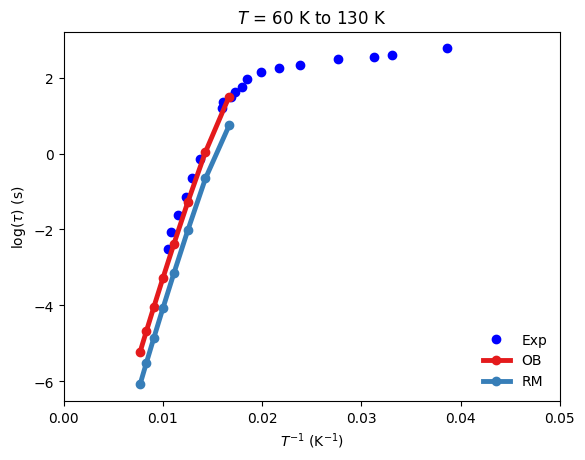

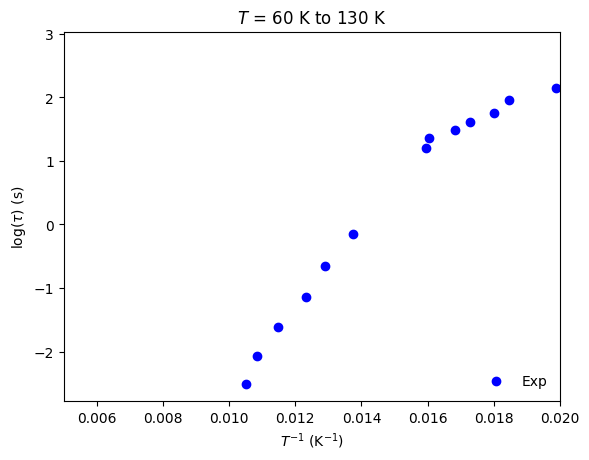

In [2]:
#!/usr/bin/env python3
# -*- coding:utf-8 -*-

import math
import random
import numpy as np
from numpy import polyfit, poly1d
import argparse
from pathlib import Path
import shutil 
import os 
import sys
import re
import yaml
from gen_structures import mol_freq
from Select_group import choose_group
from matplotlib import pyplot as plt
from matplotlib.pyplot import MultipleLocator
from prettytable import PrettyTable

import matplotlib as mpl
from matplotlib import pyplot as plt
from matplotlib.pyplot import MultipleLocator
from matplotlib import cycler
from matplotlib import cm
from mpl_toolkits.axes_grid1 import make_axes_locatable
from sklearn.metrics import r2_score

from sympy.physics.quantum.cg import CG
from sympy import S


from ase import Atoms
from ase.io import read
from ase.visualize import view
from ase.build import fcc111, add_adsorbate
from ase.io import write
from ase.io import vasp

symbols = {1:"H", 6:"C", 7:"N", 8:"O", 14:"Si", 17:"Cl", 66:"Dy"} 
atNos = {"H":1, "C":6, "N":7, "O":8, "Si":14, "Cl":17, "Dy":66} 
palette = plt.get_cmap('Set1')


#set constants
class _const:
    class ConstError(TypeError):pass
    def __setattr__(self,name,value):
        if name in self.__dict__:
            raise self.ConstError("Can't rebind const (%s)" %name) #禁止重新绑定常数
        self.__dict__[name]=value
        
const = _const()

##################################### constants ####################################
# conversion factor from m (reduced mass, amu) and w (frequency, cm^-1) to the amplitude of a harmonic oscillator x ( Angstrom)
const.hbar = 1.05457266  
const.amu = 1.66053886
const.c = 2.9979
const.kb = 13.80649
x_fac = np.sqrt( const.hbar / (const.amu * 2.0 * np.pi * const.c) ) * 10 ** 1.5
#    x = x_fac / np.sqrt( m * w)
symbols = {1:"H", 6:"C", 7:"N", 8:"O", 14:"Si", 17:"Cl", 66:"Dy"} 

#'''
#设置清屏函数
def is_in_notebook():
    import sys
    return 'ipykernel' in sys.modules

def clear_output():
    """
    clear output for both jupyter notebook and the console
    """
    import os
    os.system('cls' if os.name == 'nt' else 'clear')
    if is_in_notebook():
        from IPython.display import clear_output as clear
        clear()
#'''

def count_string(string, filename):
    """
        return the number of appearances of string in the file filename in windows os
    """
    with open(filename) as f:
        data = f.read()
    n = len(data.split(string))-1
    return n

class mol_freq(object):

    def __init__(self, hessian_file, g_file):
        self.hessian_file = hessian_file
        self.g_file = g_file

    def get_r_rotated2eazyaxis(self): #get r_rotated2eazyaxis from SVD of gtensor from Orca output
        g = np.zeros([3,3],dtype=float)
        U_rotated2eazyaxis = np.zeros([3,3], dtype=float)
        U_rotated2eazyaxis[0] = [0,     0,     1]
        U_rotated2eazyaxis[1] = [0,     1,     0]
        U_rotated2eazyaxis[2] = [1,     0,     0]
        with open(self.g_file,"r") as file:
            while True:
                line = file.readline()
                if not line:
                    break
                if len(line.split()) == 2 and " ".join(line.split())== "ELECTRONIC G-MATRIX":
                    for k in range(3):
                        line = file.readline()
                    for i in range(3):
                        line = file.readline()
                        for j in range(3):
                            g[i,j] = float(line.split()[j])
                    U,S,VT = np.linalg.svd(g)
                    r_rotated2eazyaxis = U_rotated2eazyaxis @ np.linalg.inv(U)
                    self.g = g
                    self.r = r_rotated2eazyaxis
            return r_rotated2eazyaxis
    

    def read_modes_orca_byhessian_norotation(self):
        Hessian_file = self.hessian_file
        with open(Hessian_file,"r") as file:
            while True:
                line = file.readline()
                if not line:
                    break
                if line == "$hessian\n": #find the correct position
                    line = file.readline()
                    line = line.rstrip('\n')
                    nhess = int(line) # get the dimension of hess
                    self.nfreqs = nhess
                    self.natoms = int(nhess/3)
                    hess = np.zeros((nhess, nhess))
                    n_group = nhess//5 
                    for i in range(n_group+1):
                        line = file.readline()
                        for j in range(nhess):
                            line = file.readline()
                            line = line.split()
                            for k in range(len(line)-1):
                                hess[j,i*5+k] = float(line[k+1]) 
                    self.hess = hess
                    #np.savetxt("hess.txt",hess)
                if line == "$atoms\n":
                    line = file.readline()
                    line = line.rstrip('\n')
                    natoms = int(line) # get the number of atoms
                    atom_m = np.zeros([natoms])
                    atom_coor = np.zeros([3*natoms])
                    for i in range(natoms):
                        line = file.readline()
                        line = line.split()
                        atom_m[i] = float(line[1])
                        atom_coor[i*3] = float(line[2])
                        atom_coor[i*3+1] = float(line[3])
                        atom_coor[i*3+2] = float(line[4])
                    self.atom_m = atom_m
        hess = ( hess + hess.T ) / 2
        #np.savetxt("hess_symmetry.txt",hess)
        m_matix = np.zeros([nhess, nhess])
        for i in range(nhess):
            m_matix[i, i] = atom_m[i//3]
        kmat = np.zeros([nhess, nhess])
        for i in range(nhess):
            for j in range(nhess):
                kmat[i, j] = hess[i, j] / np.sqrt(m_matix[i, i] * m_matix[j, j])
        #np.savetxt("kmat.txt",kmat)
        #nearestatom = np.array([1,2,3,4,6,7,9,10,13,17,21,22,26,30,34,35,36,38,39,49,53,57,62,63,64,65,66,67,68,74,75,76,77,78,79])
        #nearestatom = np.array([1,2,3,4,5,6,7,8,9,21,34,35,36,37,38,62,63,66,67,68,73])
        #nearestatom = np.array([1,2,3,4,6,7,35,36,62,63,66])
        nearestatom = np.array([i for i in range(1,94)])
        if(len(nearestatom)<(nhess/3)):
            print("you only consider the nearest atoms",nearestatom)
        else:
            print("you consider all the atoms")
        nearatom_num = np.empty([len(nearestatom)*3])
        for i in range(len(nearestatom)):
            for j in range(3):
                nearatom_num[i*3+j] = (nearestatom[i]-1)*3+j
        reduced_hess = np.zeros([len(nearatom_num),len(nearatom_num)])
        for i in range(len(nearatom_num)):
            for j in range(len(nearatom_num)):
                k = int(nearatom_num[i])
                l = int(nearatom_num[j])
                reduced_hess[i,j] = kmat[k,l]
        #np.savetxt("reduced_kmat.txt",reduced_hess)
        eigenvals, eigenvects = np.linalg.eigh(reduced_hess)
        self.eigenvects = eigenvects.copy()
        amu2kg=1.66053878E-27
        b2m=0.529177249E-10
        au2J=4.35974434E-18
        eigenvals = eigenvals * au2J / (b2m**2) / amu2kg
        freq = np.zeros_like(eigenvals)
        for i in range(len(eigenvals)):
            if eigenvals[i] > 0:
                freq[i] = np.sqrt(eigenvals[i]) / (2*np.pi)
            else:
                freq[i] = -np.sqrt(-eigenvals[i]) / (2*np.pi)
        wavenum = freq / 2.99792458E10
        abs_wavenum = np.abs(wavenum)
        min_indices = np.argsort(abs_wavenum)[:6]
        wavenum[min_indices] = 0
        print(f'\n{"Reduced Vibrational frequencies:":=^100}\n')
        for i in range(len(wavenum)):
            print(f'Mode {i+1}: {wavenum[i]:>20.2f} cm**-1')
        atom_m_reduce = np.zeros([len(nearestatom)])
        #np.savetxt("eigenvects",eigenvects)
        for i in range(len(nearestatom)):
            k = nearestatom[i]
            atom_m_reduce[i] = atom_m[k-1]
        for i in range(eigenvects.shape[0]):
            eigenvects[i,:] = eigenvects[i,:] / np.sqrt(atom_m_reduce[i//3])
        #np.savetxt("eigenvects_mass",eigenvects)
        for i in range(eigenvects.shape[1]):
            eigenvects[:,i] = eigenvects[:,i] / np.sqrt(np.sum(eigenvects[:,i]**2))
        vecs = np.zeros([len(wavenum),len(nearestatom),3])
        for i in range(len(wavenum)):
            for j in range(len(wavenum)):
                z1 = int(j/3)
                z2 = j%3
                vecs[i,z1,z2] = eigenvects[j,i]
        self.freqs, self.vecs = wavenum, vecs
        #np.savetxt("eigenvects_mass_normal",eigenvects)
        #np.savetxt("eigenvects.txt",eigenvects)
        #print("vecs[58,:,:]=",vecs[58,:,:])

    def read_modes_orca_byhessian(self,A):
        print("we get Hessian matrix from rotation")
        Hessian_file = self.hessian_file
        with open(Hessian_file,"r") as file:
            while True:
                line = file.readline()
                if not line:
                    break
                if line == "$hessian\n": #find the correct position
                    line = file.readline()
                    line = line.rstrip('\n')
                    nhess = int(line) # get the dimension of hess
                    self.nfreqs = nhess
                    self.natoms = int(nhess/3)
                    hess = np.zeros((nhess, nhess))
                    n_group = nhess//5 
                    for i in range(n_group+1):
                        line = file.readline()
                        for j in range(nhess):
                            line = file.readline()
                            line = line.split()
                            for k in range(len(line)-1):
                                hess[j,i*5+k] = float(line[k+1]) 
                    self.hess = hess
                    #np.savetxt("hess.txt",hess)
                if line == "$atoms\n":
                    line = file.readline()
                    line = line.rstrip('\n')
                    natoms = int(line) # get the number of atoms
                    atom_m = np.zeros([natoms])
                    atom_coor = np.zeros([3*natoms])
                    for i in range(natoms):
                        line = file.readline()
                        line = line.split()
                        atom_m[i] = float(line[1])
                        atom_coor[i*3] = float(line[2])
                        atom_coor[i*3+1] = float(line[3])
                        atom_coor[i*3+2] = float(line[4])
                    self.atom_m = atom_m
        R = np.zeros([self.nfreqs,self.nfreqs],dtype=float)
        r = np.zeros([3,3],dtype=float)
        if A == "none" :
            r[0] = [1.0,0.0,0.0]
            r[1] = [0.0,1.0,0.0]
            r[2] = [0.0,0.0,1.0]
        if A == "Y_90" :
            r[0] = [0.0,0.0,1.0]
            r[1] = [0.0,1.0,0.0]
            r[2] = [-1.0,0.0,0.0]
        if A == "Z_45" :
            r[0] = [0.707,0.707,0.0]
            r[1] = [-0.707,0.707,0.0]
            r[2] = [0.0,0.0,1.0]
        if A == "Y_45" :
            r[0] = [0.707,0.0,0.707]
            r[1] = [0.0,1.0,0.0]
            r[2] = [-0.707,0.0,0.707]
        if A == "Y_45+Z_30" :
            r[0] = [0.866*0.707,-0.5,0.866*0.707]
            r[1] = [0.5*0.707,0.866,0.5*0.707]
            r[2] = [-0.707,0.0,0.707]
        for i in range(int(self.nfreqs)//3):
            for j in range(3):
                for k in range(3):
                    R[i*3+j,i*3+k] = r[j,k]
        R_t = R.T
        hess_rotated = R @ self.hess @ R_t
        hess = hess_rotated
        #print(hess_rotated)
        hess = ( hess + hess.T ) / 2
        #np.savetxt("hess_symmetry.txt",hess)
        m_matix = np.zeros([self.nfreqs, self.nfreqs])
        for i in range(self.nfreqs):
            m_matix[i, i] = self.atom_m[i//3]
        kmat = np.zeros([self.nfreqs, self.nfreqs])
        for i in range(self.nfreqs):
            for j in range(self.nfreqs):
                kmat[i, j] = hess[i, j] / np.sqrt(m_matix[i, i] * m_matix[j, j])
        #np.savetxt("kmat.txt",kmat)
        #nearestatom = np.array([1,2,3,4,6,7,9,10,13,17,21,22,26,30,34,35,36,38,39,49,53,57,62,63,64,65,66,67,68,74,75,76,77,78,79])
        #nearestatom = np.array([1,2,3,4,5,6,7,8,9,21,34,35,36,37,38,62,63,66,67,68,73])
        #nearestatom = np.array([1,2,3,4,6,7,35,36,62,63,66])
        nearestatom = np.array([i for i in range(1,94)])
        if(len(nearestatom)<(self.nfreqs/3)):
            print("you only consider the nearest atoms",nearestatom)
        else:
            print("you consider all the atoms")
        nearatom_num = np.empty([len(nearestatom)*3])
        for i in range(len(nearestatom)):
            for j in range(3):
                nearatom_num[i*3+j] = (nearestatom[i]-1)*3+j
        reduced_hess = np.zeros([len(nearatom_num),len(nearatom_num)])
        for i in range(len(nearatom_num)):
            for j in range(len(nearatom_num)):
                k = int(nearatom_num[i])
                l = int(nearatom_num[j])
                reduced_hess[i,j] = kmat[k,l]
        #np.savetxt("reduced_kmat.txt",reduced_hess)
        eigenvals, eigenvects = np.linalg.eigh(reduced_hess)
        self.eigenvects = eigenvects.copy()
        amu2kg=1.66053878E-27
        b2m=0.529177249E-10
        au2J=4.35974434E-18
        eigenvals = eigenvals * au2J / (b2m**2) / amu2kg
        freq = np.zeros_like(eigenvals)
        for i in range(len(eigenvals)):
            if eigenvals[i] > 0:
                freq[i] = np.sqrt(eigenvals[i]) / (2*np.pi)
            else:
                freq[i] = -np.sqrt(-eigenvals[i]) / (2*np.pi)
        wavenum = freq / 2.99792458E10
        abs_wavenum = np.abs(wavenum)
        min_indices = np.argsort(abs_wavenum)[:6]
        wavenum[min_indices] = 0
        print(f'\n{"Reduced Vibrational frequencies:":=^100}\n')
        for i in range(len(wavenum)):
            print(f'Mode {i+1}: {wavenum[i]:>20.2f} cm**-1')
        atom_m_reduce = np.zeros([len(nearestatom)])
        #np.savetxt("eigenvects",eigenvects)
        for i in range(len(nearestatom)):
            k = nearestatom[i]
            atom_m_reduce[i] = self.atom_m[k-1]
        for i in range(eigenvects.shape[0]):
            eigenvects[i,:] = eigenvects[i,:] / np.sqrt(atom_m_reduce[i//3])
        #np.savetxt("eigenvects_mass",eigenvects)
        for i in range(eigenvects.shape[1]):
            eigenvects[:,i] = eigenvects[:,i] / np.sqrt(np.sum(eigenvects[:,i]**2))
        vecs = np.zeros([len(wavenum),len(nearestatom),3])
        for i in range(len(wavenum)):
            for j in range(len(wavenum)):
                z1 = int(j/3)
                z2 = j%3
                vecs[i,z1,z2] = eigenvects[j,i]
        self.freqs, self.vecs = wavenum, vecs

    def get_hessian_R2E(self):
        self.get_r_rotated2eazyaxis()
        print("we now rotate Hessian to eazyaxis")
        R = np.zeros([self.nfreqs,self.nfreqs],dtype=float)
        r = self.r
        for i in range(int(self.nfreqs)//3):
            for j in range(3):
                for k in range(3):
                    R[i*3+j,i*3+k] = r[j,k]
        R_t = R.T
        hess_rotated = R @ self.hess @ R_t
        hess = hess_rotated
        #print(hess_rotated)
        hess = ( hess + hess.T ) / 2
        #np.savetxt("hess_symmetry.txt",hess)
        m_matix = np.zeros([self.nfreqs, self.nfreqs])
        for i in range(self.nfreqs):
            m_matix[i, i] = self.atom_m[i//3]
        kmat = np.zeros([self.nfreqs, self.nfreqs])
        for i in range(self.nfreqs):
            for j in range(self.nfreqs):
                kmat[i, j] = hess[i, j] / np.sqrt(m_matix[i, i] * m_matix[j, j])
        #np.savetxt("kmat.txt",kmat)
        #nearestatom = np.array([1,2,3,4,6,7,9,10,13,17,21,22,26,30,34,35,36,38,39,49,53,57,62,63,64,65,66,67,68,74,75,76,77,78,79])
        #nearestatom = np.array([1,2,3,4,5,6,7,8,9,21,34,35,36,37,38,62,63,66,67,68,73])
        #nearestatom = np.array([1,2,3,4,6,7,35,36,62,63,66])
        nearestatom = np.array([i for i in range(1,94)])
        if(len(nearestatom)<(self.nfreqs/3)):
            print("you only consider the nearest atoms",nearestatom)
        else:
            print("you consider all the atoms")
        nearatom_num = np.empty([len(nearestatom)*3])
        for i in range(len(nearestatom)):
            for j in range(3):
                nearatom_num[i*3+j] = (nearestatom[i]-1)*3+j
        reduced_hess = np.zeros([len(nearatom_num),len(nearatom_num)])
        for i in range(len(nearatom_num)):
            for j in range(len(nearatom_num)):
                k = int(nearatom_num[i])
                l = int(nearatom_num[j])
                reduced_hess[i,j] = kmat[k,l]
        #np.savetxt("reduced_kmat.txt",reduced_hess)
        eigenvals, eigenvects = np.linalg.eigh(reduced_hess)
        self.eigenvects = eigenvects.copy()
        amu2kg=1.66053878E-27
        b2m=0.529177249E-10
        au2J=4.35974434E-18
        eigenvals = eigenvals * au2J / (b2m**2) / amu2kg
        freq = np.zeros_like(eigenvals)
        for i in range(len(eigenvals)):
            if eigenvals[i] > 0:
                freq[i] = np.sqrt(eigenvals[i]) / (2*np.pi)
            else:
                freq[i] = -np.sqrt(-eigenvals[i]) / (2*np.pi)
        wavenum = freq / 2.99792458E10
        abs_wavenum = np.abs(wavenum)
        min_indices = np.argsort(abs_wavenum)[:6]
        wavenum[min_indices] = 0
        print(f'\n{"Reduced Vibrational frequencies:":=^100}\n')
        for i in range(len(wavenum)):
            print(f'Mode {i+1}: {wavenum[i]:>20.2f} cm**-1')
        atom_m_reduce = np.zeros([len(nearestatom)])
        #np.savetxt("eigenvects",eigenvects)
        for i in range(len(nearestatom)):
            k = nearestatom[i]
            atom_m_reduce[i] = self.atom_m[k-1]
        for i in range(eigenvects.shape[0]):
            eigenvects[i,:] = eigenvects[i,:] / np.sqrt(atom_m_reduce[i//3])
        #np.savetxt("eigenvects_mass",eigenvects)
        for i in range(eigenvects.shape[1]):
            eigenvects[:,i] = eigenvects[:,i] / np.sqrt(np.sum(eigenvects[:,i]**2))
        vecs = np.zeros([len(wavenum),len(nearestatom),3])
        for i in range(len(wavenum)):
            for j in range(len(wavenum)):
                z1 = int(j/3)
                z2 = j%3
                vecs[i,z1,z2] = eigenvects[j,i]
        self.freqs, self.vecs = wavenum, vecs
    
    
    def read_modes_orca(self):
        """
            read in normal modes information from the orca output file
            including the frequencies (cm-1) and atom displacement vectors (unitless). 
        """
        n_freq_analysis = count_string("cm**-1", self.freq_file)-1  #in the windows os
        freqs = np.empty([n_freq_analysis], dtype = float)
        natm = int(n_freq_analysis/3) #Get the number of atoms
        vecs = np.empty([n_freq_analysis,natm,3], dtype = float)
        print("""
There are %4d frequency analysis in the freq_file, and we always use the first part.
When this number is greater than 1, the first part contains more digit numbers for the 
displacement vectors. """ % n_freq_analysis)     
        with open(self.freq_file, "r") as f:
            while True:
                line = f.readline()
                if not line:
                    break
                if len(line.split()) == 2 and " ".join(line.split()) == "VIBRATIONAL FREQUENCIES":
                        # find the correct position, we now read in the normal modes 
                        for i in range(5):
                            line = f.readline()
                        for j in range(n_freq_analysis):
                            freqs[j]=line.split()[1]
                            line = f.readline()
                        for i in range(10):
                            line = f.readline()
                        for l in range(math.ceil(n_freq_analysis/6)):
                            nmodes = len(line.split())        # in this part we have nmodes modes in each line            
                            for i in range(natm):
                               for j in range(3):
                                  line_list = [float(x) for x in f.readline().split()[1:]]
                                  for k in range(nmodes):
                                        vecs[l*6+k,i,j] = line_list[k] 
                            line = f.readline()
        self.freqs, self.vecs = freqs, vecs 
        #print(self.vecs[8,...],self.vecs[11,...])
    '''
    def read_modes_gauss(self):
        """
            read in normal modes information from the output file
            including the frequencies (cm-1), reduced masses (amu), force constants (mDyne/A) 
            and atom displacement vectors (unitless). 
        """
        freqs = []
        masses = []
        frcs = []
        vecs = []
        ir_intensity = []
        syms = []
        n_freq_analysis = count_string("normal coordinates:", self.filename)
        print("""
              There are %4d frequency analysis in the log file, and we always use the first part.
              When this number is greater than 1, the first part contains more digit numbers for the 
              displacement vectors. 
              """ % n_freq_analysis) 
        if n_freq_analysis == 1:
            print("\nThe vectors have only 2 digits, more accurate results could be printed in log by specifying freq=hpmodes in Gaussian input file!\n")      
        with open(self.filename, "r") as f:
            while True:
                line = f.readline()
                if not line:
                    break
                if len(line.split()) == 3 and " ".join(line.split()[-2:]) == "normal coordinates:":
                    # find the correct position, we now read in the normal modes 
                    while True:
                        line = f.readline()
                        nmodes = len(line.split())        # in this part we have nmodes modes in each line
                        if nmodes < 1 or (not line.split()[0].isdigit()): 
                            break # modes reading is done 
                        syms += f.readline().split()
                        freqs += [float(x) for x in f.readline().split()[2:]]
                        masses += [float(x) for x in f.readline().split()[3:]]
                        frcs += [float(x) for x in f.readline().split()[3:]]
                        ir_intensity += [float(x) for x in f.readline().split()[3:]]
                        f.readline()    # useless line
                        nat = self.atNos.size
                        vec_batch = [None] * nmodes
                        for i in range(nmodes):
                            vec_batch[i] = np.zeros((nat, 3)) # different vecs for up to 3 modes 
                        # different reading method for coarse or fine output of the displacement vectors 
                        if n_freq_analysis == 1:
                            # coarse date: only two digits are present
                            for i in range(nat):
                                line_list = [float(x) for x in f.readline().split()[2:]]
                                for j in range(nmodes):
                                    vec_batch[j][i,:] = line_list[3*j:3*j+3]
                        else:
                            # fine output: 5 digits for the vector
                            for i in range(nat):
                                for j in range(3):
                                    line_list = [float(x) for x in f.readline().split()[3:]]
                                    for k in range(nmodes):
                                        vec_batch[k][i,j] = line_list[k] 
                        vecs += vec_batch
                    break
        self.freqs, self.masses, self.frcs, self.ir_intensity, self.syms, self.vecs = \
            np.array(freqs), np.array(masses), np.array(frcs), np.array(ir_intensity), syms, np.array(vecs)
    '''
    def remove_zeroandnegative(self):
        print("Now we'll remove zero and negative values from freqs and vecs")
        self.freqs = np.array(self.freqs)
        self.vecs = np.array(self.vecs)
        filtered_freqs = self.freqs[self.freqs > 0]
        removed_modes = np.where(self.freqs <= 0)
        filtered_vecs = self.vecs[np.setdiff1d(np.arange(self.vecs.shape[0]), removed_modes), :]
        self.freqs = filtered_freqs
        self.vecs = filtered_vecs
        removed_modes = np.array(removed_modes).reshape(np.array(removed_modes).shape[1])
        for X in removed_modes:
            print(f"We have removed mode {X}")
        print("The corresponding vecs have been removed")
        print("After removing, we have nmd = {}".format(self.freqs.shape[0]))


class CFPs_Analyze(object):
    """
        the object corresponds to analyze the CFPs.
    """ 
    def __init__(self, filename,CFPs_X):
        self.filename = filename
        self.X = CFPs_X
    
    def read_CFPs(self):
        """
        read CFPs, number of modes, and the number of points from the file filename,)
        """
        with open(self.filename,"r") as file:
            line = file.readline()
            line = file.readline()
            line = file.readline()
            nmds = int(line.split()[2])  #read number of modes
            line = file.readline()
            npts = int(line.split()[2])  #read number of points
            B = np.empty([nmds,npts,27], dtype = float)
            B2 = np.empty([5], dtype = float)   #B_kq,where k = 2
            B4 = np.empty([9], dtype = float)   #B_kq,where k = 4
            B6 = np.empty([13], dtype = float)  #B_kq,where k = 6
            # B8 = np.empty([17], dtype = float)  #B_kq,where k = 8
            # B10 = np.empty([21], dtype = float)  #B_kq,where k = 10
            # B12 = np.empty([25], dtype = float)  #B_kq,where k = 12
            # B14 = np.empty([29], dtype = float)  #B_kq,where k = 14
            for i in range(0,nmds):
                #print("work on mode "+str(i+1))
                for j in range(0,npts):
                    line = file.readline()
                    #i = int(line.split()[1])-1
                    line = file.readline()
                    B2 = line.split()
                    B[i,j,0:5] = B2
                    line = file.readline()
                    B4 = line.split()
                    B[i,j,5:14] = B4
                    line = file.readline()
                    B6 = line.split()
                    #print(line)
                    B[i,j,14:27] = B6
                    # line = file.readline()
                    # B8 = line.split()
                    # B[i,j,27:44] = B8  
                    # line = file.readline()
                    # B10 = line.split()
                    # B[i,j,44:65] = B10
                    # line = file.readline()
                    # B12 = line.split()
                    # B[i,j,65:90] = B12
                    # line = file.readline()
                    # B14 = line.split()
                    # B[i,j,90:119] = B14
        B = np.insert(B,(npts+1)//2,0,axis = 1) #add the eq perturbation CFPs
        npts = 7
        B_test = np.empty([nmds,npts,27], dtype = float)
        num_list = [1,3,5,6,7,9,11]
        for i in range(nmds):
            for j in range(npts):
                B_test[i,j,...] = B[i,num_list[j]-1,...]
        self.nmds = nmds
        self.npts = npts
        self.Bkq = B

    def read_CFPs_xyz(self):
        """
        read CFPs, number of modes, and the number of points from the file filename 
        """
        with open(self.filename,"r") as file:
            line = file.readline()
            line = file.readline()
            line = file.readline()
            nmds = int(line.split()[2])
            line = file.readline()
            npts = int(line.split()[2])
            B = np.empty([nmds,npts,27], dtype = float)
            B2 = np.empty([5], dtype = float)   #B_kq,where k = 2
            B4 = np.empty([9], dtype = float)   #B_kq,where k = 4
            B6 = np.empty([13], dtype = float)  #B_kq,where k = 6
            for i in range(0,nmds):
                #print("work on mode "+str(i+1))
                for j in range(0,npts):
                    line = file.readline()
                    i = int(line.split()[1])-1
                    line = file.readline()
                    B2 = line.split()
                    B[i,j,0:5] = B2
                    line = file.readline()
                    B4 = line.split()
                    B[i,j,5:14] = B4
                    line = file.readline()
                    B6 = line.split()
                    B[i,j,14:27] = B6    
        B = np.insert(B,(npts+1)//2,0,axis = 1) #add the eq perturbation CFPs
        self.xyznmd = nmds
        self.npts = npts
        self.Bkq = B

    def info(self,nmds,npts):
        self.nmds = nmds
        self.npts = npts

    def random_CFPs(self,x):
        B = np.empty([self.nmds,self.npts+1,27], dtype = float)
        for i in range(0,self.nmds):
            for k in range(0,27):
                a = random.uniform(1-x,1+x)
                B[i,2,k] = self.Bkq[i,2,k]*a
        self.Bkq = B
        
    def random_CFPs_mod(self,x):
        B = np.empty([self.nmds,self.npts+1,27], dtype = float)
        Mod = np.empty([int(x)], dtype = int)
        for i in range(0,int(x)):
            Mod[i] = random.randint(0,self.nmds-1)
        for i in range(0,self.nmds):
            for k in range(0,27):
                j = random.randint(0,9)
                B[i,2,k] = self.Bkq[Mod[j],2,k]
        self.Bkq = B
    
    def random_CFPs_ab(self,x):
        B = np.empty([self.nmds,self.npts+1,27], dtype = float)
        theta_2 = -2/315
        theta_4 = -8/135135
        theta_6 = 4/3864861
        for i in range(0,self.nmds):
            for k in range(0,5):
                B[i,2,k] = x*random.uniform(-1,1)*theta_2
            for k in range(5,14):
                B[i,2,k] = x*random.uniform(-1,1)*theta_4
            for k in range(14,27):
                B[i,2,k] = x*random.uniform(-1,1)*theta_6
        self.Bkq = B
        
    def random_CFPs_gs(self,x):
        B = np.zeros([self.nmds,self.npts+1,27], dtype = float)
        theta_2 = -2/315
        theta_4 = -8/135135
        theta_6 = 4/3864861
        for i in range(0,self.nmds):
            for k in range(0,5):
                B[i,2,k] = np.random.normal(loc=0.0, scale=x)*theta_2/10
            for k in range(5,14):
                B[i,2,k] = np.random.normal(loc=0.0, scale=x)*theta_4/10
            for k in range(14,27):
                B[i,2,k] = np.random.normal(loc=0.0, scale=x)*theta_6/10
        self.Bkq = B 

    def random3_CFPs_gs(self,x):
        B = np.zeros([self.nmds,self.npts+1,27], dtype = float)
        theta_2 = -2/315
        theta_4 = -8/135135
        theta_6 = 4/3864861
        for i in range(0,self.nmds):
            for k in range(0,5):
                B[i,3,k] = np.random.normal(loc=0.0, scale=x)*theta_2/10
            for k in range(5,14):
                B[i,3,k] = np.random.normal(loc=0.0, scale=x)*theta_4/10
            for k in range(14,27):
                B[i,3,k] = np.random.normal(loc=0.0, scale=x)*theta_6/10
        self.Bkq = B  

    def Line_CFPs(self):
        B = np.empty((0,),dtype = float)
        theta_2 = -2/315
        theta_4 = -8/135135
        theta_6 = 4/3864861
        for i in range(0,self.nmds):
            for k in range(0,5):
                B = np.append(B,self.Bkq[i,3,k]/theta_2)
            for k in range(5,14):
                B = np.append(B,self.Bkq[i,3,k]/theta_4)
            for k in range(14,27):
                B = np.append(B,self.Bkq[i,3,k]/theta_6)
        return B

    def write_CFPs(self,filename):
        """
        read CFPs, number of modes, and the number of points from the file filename,)  
        """
        B = np.zeros([self.nmds,self.npts+1,27], dtype = float)
        theta_2 = -2/315
        theta_4 = -8/135135
        theta_6 = 4/3864861
        for i in range(0,self.nmds):
            for k in range(0,5):
                B[i,3,k] = np.random.normal(loc=0.0, scale=10)*theta_2/10
            for k in range(5,14):
                B[i,3,k] = np.random.normal(loc=0.0, scale=10)*theta_4/10
            for k in range(14,27):
                B[i,3,k] = np.random.normal(loc=0.0, scale=10)*theta_6/10
        with open(filename,"w") as file:
            file.write("The Perturbation CFPs\n")
            file.write("Total modes {x}\n".format(x=args.nmds))
            file.write("Total points {y}\n".format(y=args.npts))
            for imod in range(0,self.nmds):
                for ipt in range(0,5):
                    print("Working on the Mode {x} Point {y}".format(x=imod+1,y=ipt+1))
                    file.write("Mode {x} Point {y}\n".format(x=imod+1,y=ipt+1))
                    B2 = B[imod,ipt,0:5]
                    B4 = B[imod,ipt,5:14]
                    B6 = B[imod,ipt,14:27]
                    file.write(" ".join(str(s) for s in B2)+"\n")
                    file.write(" ".join(str(s) for s in B4)+"\n")
                    file.write(" ".join(str(s) for s in B6)+"\n")
        
    def save_picture(self,foldname):
        """
        save the figture of B_kq correspond to displacement x on every vibration mode 
        """
        if not os.path.exists(foldname):
            os.makedirs(foldname)
        else:
            print("the folder foldname exists, delete it and run this program again")
            return 0
        theta_2 = -2/315
        theta_4 = -8/135135
        theta_6 = 4/3864861
        for i in range(0,self.nmds):
            os.makedirs("{f}/mode{x}".format(f=foldname,x=i+1))
            for j in range(0,5):
                plt.plot(self.X,self.Bkq[i,...,j]/theta_2,label = str(j-2))
            plt.xlim(-1.0,1.0)
            plt.ylim(-400,400)
            plt.legend(loc=0,ncol=1)
            plt.title("k = {x}".format(x = 2)) 
            plt.xlabel("x_j") 
            plt.ylabel("B_kq(cm^-1)") 
            plt.savefig("{f}/mode{x}/mode{x}_2.png".format(f=foldname,x=i+1))
            plt.show()
            #print("mode:"+str(i)+" ,k=2")
            for j in range(5,14):
                plt.plot(self.X,self.Bkq[i,...,j]/theta_4,label = str(j-9))
            plt.xlim(-1.0,1.0)
            plt.ylim(-400,400)
            plt.legend(loc=0,ncol=1)
            plt.title("k = {x}".format(x = 4)) 
            plt.xlabel("x_j") 
            plt.ylabel("B_kq(cm^-1)") 
            plt.savefig("{f}/mode{x}/mode{x}_4.png".format(f=foldname,x=i+1))
            plt.show()
            #print("mode:"+str(i)+" ,k=4")
            for j in range(14,27):
                plt.plot(self.X,self.Bkq[i,...,j]/theta_6,label = str(j-20))
            plt.xlim(-1.0,1.0)
            plt.ylim(-400,400)
            plt.legend(loc=0,ncol=1)
            plt.title("k = {x}".format(x = 6)) 
            plt.xlabel("x_j") 
            plt.ylabel("B_kq(cm^-1)") 
            plt.savefig("{f}/mode{x}/mode{x}_6.png".format(f=foldname,x=i+1))
            plt.show()
            #print("mode:"+str(i)+" ,k=6")
        return 1
    
    def save_picture_xyz(self,foldname):
        """
        save the figture of B_kq correspond to displacement x on every vibration mode 
        """
        if not os.path.exists(foldname):
            os.makedirs(foldname)
        else:
            print("the folder foldname exists, delete it and run this program again")
            return 0
        theta_2 = -2/315
        theta_4 = -8/135135
        theta_6 = 4/3864861
        Xmax = 0.1
        Ymax = 200
        for i in range(0,self.xyznmd):
            os.makedirs("{f}/mode{x}".format(f=foldname,x=i+1))
            for j in range(0,5):
                plt.plot(self.X,self.Bkq[i,...,j]/theta_2,label = str(j-2))
            plt.xlim(-Xmax,Xmax)
            plt.ylim(-Ymax,Ymax)
            plt.legend(loc=0,ncol=1)
            plt.title("k = {x}".format(x = 2)) 
            plt.xlabel("x_j") 
            plt.ylabel("B_kq(cm^-1)") 
            plt.savefig("{f}/mode{x}/mode{x}_2.png".format(f=foldname,x=i+1))
            plt.show()
            #print("mode:"+str(i)+" ,k=2")
            for j in range(5,14):
                plt.plot(self.X,self.Bkq[i,...,j]/theta_4,label = str(j-9))
            plt.xlim(-Xmax,Xmax)
            plt.ylim(-Ymax,Ymax)
            plt.legend(loc=0,ncol=1)
            plt.title("k = {x}".format(x = 4)) 
            plt.xlabel("x_j") 
            plt.ylabel("B_kq(cm^-1)") 
            plt.savefig("{f}/mode{x}/mode{x}_4.png".format(f=foldname,x=i+1))
            plt.show()
            #print("mode:"+str(i)+" ,k=4")
            for j in range(14,27):
                plt.plot(self.X,self.Bkq[i,...,j]/theta_6,label = str(j-20))
            plt.xlim(-Xmax,Xmax)
            plt.ylim(-Ymax,Ymax)
            plt.legend(loc=0,ncol=1)
            plt.title("k = {x}".format(x = 6)) 
            plt.xlabel("x_j") 
            plt.ylabel("B_kq(cm^-1)") 
            plt.savefig("{f}/mode{x}/mode{x}_6.png".format(f=foldname,x=i+1))
            plt.show()
            #print("mode:"+str(i)+" ,k=6")
            clear_output()
        return 1
     
    def gen_picture(self,n):
        """
        gen the figture of B_kq correspond to displacement x on vibration mode 'n'
        """
        theta_2 = -2/315
        theta_4 = -8/135135
        theta_6 = 4/3864861
        for j in range(0,5):
            plt.plot(self.X,self.Bkq[i,...,j]/theta_2,label = str(j-2))
        plt.xlim(-1.0,1.0)
        plt.ylim(-400,400)
        plt.legend(loc=0,ncol=1)
        plt.title("k = {x}".format(x = 2)) 
        plt.xlabel("x_j") 
        plt.ylabel("B_kq(cm^-1)") 
        plt.show()
        print("mode:"+str(n)+" ,k=2")
        for j in range(5,14):
            plt.plot(self.X,self.Bkq[n-1,...,j]/theta_4,label = str(j-9))
        plt.xlim(-1.0,1.0)
        plt.ylim(-400,400)
        plt.legend(loc=0,ncol=1)
        plt.title("k = {x}".format(x = 4)) 
        plt.xlabel("x_j") 
        plt.ylabel("B_kq(cm^-1)") 
        plt.show()
        print("mode:"+str(n)+" ,k=4")
        for j in range(14,27):
            plt.plot(self.X,self.Bkq[n-1,...,j]/theta_6,label = str(j-20))
        plt.xlim(-1.0,1.0)
        plt.ylim(-400,400)
        plt.legend(loc=0,ncol=1)
        plt.title("k = {x}".format(x = 6)) 
        plt.xlabel("x_j") 
        plt.ylabel("B_kq(cm^-1)") 
        plt.show()
        print("mode:"+str(n)+" ,k=6")

    def gen_slope(self):
        """
        Fit the function of B(X) to x wirh n-th order function
        """
        print("consider the xyzmodes of every atom")
        B_slope = np.empty([self.nmds,27], dtype = float)
        for i in range(0,self.nmds):
            for j in range(0,27):
                #print(np.shape(self.X),np.shape(self.Bkq[i,...,j]))
                B_slope[i,j] = polyfit(self.X, self.Bkq[i,...,j], 1)[0]
        self.B_slope = B_slope

    def gen_slope_xyz(self):
        """
        Fit the linear function of B(X) to x
        """
        B_slope = np.empty([self.xyznmd,27], dtype = float)
        for i in range(0,self.xyznmd):
            X,B = self.select_XB(i)
            #print(i,X,B)
            for j in range(0,27):
                B_slope[i,j] = polyfit(self.X, self.Bkq[i,...,j], 1)[0]
        self.B_slopexyz = B_slope

    def test_B_trans_se(self,Select_Atnum):
        """
        transform the \partial H/\partial x to \partial H/\partial Q
        """
        #print(vecs.shape)
        #print(self.B_slope.shape)
        #print(self.B_slope.shape[0])
        #print(self.nmds)
        B_slope_trans = np.empty([3,27],dtype = float)
        at_num = int(self.xyznmd/3)
        vecs = np.ones([at_num,3], dtype = float)
        #print(self.nmds,self.xyznmd,np.shape(vecs),np.shape(self.B_slopexyz))
        for i in range(0,3):
            for j in range(0,27):
                bstemp = 0
                for iatom in Select_Atnum:
                    z = 3*iatom+i
                    bstemp = bstemp+vecs[iatom,i]*self.B_slopexyz[z,j]
                B_slope_trans[i,j] = bstemp
        print("x direction",B_slope_trans[0,...])
        print("y direction",B_slope_trans[1,...])
        print("z direction",B_slope_trans[2,...])

    def test_B_trans(self):
        """
        transform the \partial H/\partial x to \partial H/\partial Q
        """
        #print(vecs.shape)
        #print(self.B_slope.shape)
        #print(self.B_slope.shape[0])
        #print(self.nmds)
        B_slope_trans = np.empty([3,27],dtype = float)
        at_num = int(self.xyznmd/3)
        vecs = np.ones([at_num,3], dtype = float)
        #print(self.nmds,self.xyznmd,np.shape(vecs),np.shape(self.B_slopexyz))
        for i in range(0,3):
            for j in range(0,27):
                bstemp = 0
                for iatom in range(0,at_num):
                    z = 3*iatom+i
                    bstemp = bstemp+vecs[iatom,i]*self.B_slopexyz[z,j]
                B_slope_trans[i,j] = bstemp
        print("x direction",B_slope_trans[0,...])
        print("y direction",B_slope_trans[1,...])
        print("z direction",B_slope_trans[2,...])

    def fix_B_trans(self):
        """
        transform the \partial H/\partial x to \partial H/\partial Q
        """
        #print(vecs.shape)
        #print(self.B_slope.shape)
        #print(self.B_slope.shape[0])
        #print(self.nmds)
        B_slope_trans = np.empty([3,27],dtype = float)
        B_slope_abs = np.empty([3,27],dtype = float)
        at_num = int(self.xyznmd/3)
        vecs = np.ones([at_num,3], dtype = float)
        #print(self.nmds,self.xyznmd,np.shape(vecs),np.shape(self.B_slopexyz))
        for i in range(0,3):
            for j in range(0,27):
                bstemp = 0
                bstemp2 = 0
                for iatom in range(0,at_num):
                    z = 3*iatom+i
                    bstemp = bstemp+vecs[iatom,i]*self.B_slopexyz[z,j]
                    bstemp2 = bstemp2+abs(vecs[iatom,i]*self.B_slopexyz[z,j])
                B_slope_trans[i,j] = bstemp
                B_slope_abs[i,j] = bstemp2
        for i in range(0,3):
            for j in range(0,27):
                for iatom in range(0,at_num):
                    z = 3*iatom+i
                    self.B_slopexyz[z,j] = self.B_slopexyz[z,j]-B_slope_trans[i,j]*abs(self.B_slopexyz[z,j])/B_slope_abs[i,j]
        #print("x direction",B_slope_trans[0,...])
        #print("y direction",B_slope_trans[1,...])
        #print("z direction",B_slope_trans[2,...])

    def fix_B_trans_se(self,Select_Atnum):
        """
        transform the \partial H/\partial x to \partial H/\partial Q
        """
        #print(vecs.shape)
        #print(self.B_slope.shape)
        #print(self.B_slope.shape[0])
        #print(self.nmds)
        B_slope_trans = np.empty([3,27],dtype = float)
        B_slope_abs = np.empty([3,27],dtype = float)
        at_num = int(self.xyznmd/3)
        vecs = np.ones([at_num,3], dtype = float)
        #print(self.nmds,self.xyznmd,np.shape(vecs),np.shape(self.B_slopexyz))
        for i in range(0,3):
            for j in range(0,27):
                bstemp = 0
                bstemp2 = 0
                for iatom in Select_Atnum:
                    z = 3*iatom+i
                    bstemp = bstemp+vecs[iatom,i]*self.B_slopexyz[z,j]
                    bstemp2 = bstemp2+abs(vecs[iatom,i]*self.B_slopexyz[z,j])
                B_slope_trans[i,j] = bstemp
                B_slope_abs[i,j] = bstemp2
        for i in range(0,3):
            for j in range(0,27):
                for iatom in Select_Atnum:
                    z = 3*iatom+i
                    self.B_slopexyz[z,j] = self.B_slopexyz[z,j]-B_slope_trans[i,j]*abs(self.B_slopexyz[z,j])/B_slope_abs[i,j]
    
    def gen_slope_reduced(self,atoms_label):
            """
            Fit the function of B(X) to x wirh n-th order function and only consider the nearest atoms
            """
            print("only consider the xzymodes of the nearest atoms")
            B_slope = np.zeros([self.xyznmd,27], dtype = float)
            #atoms_label = np.array([1,2,3,4,6,7,35,36,53,62,66], dtype = int)
            for k in atoms_label:
                for l in range(3):
                    i = k*3+l
                    for j in range(0,27):
                        B_slope[i,j] = polyfit(self.X, self.Bkq[i,...,j], 1)[0]
            self.B_slopexyz = B_slope

    def select_XB(self,i):
        X = np.empty((0,),dtype = float)
        B = np.empty(shape=[0, 27], dtype = float)
        Btest = self.Bkq[i,...]
        for k in range(0,self.npts+1):
            if Btest[k,0] != 0 or k == (self.npts+1)//2:
                #print(np.shape(B))
                #print(Btest[k,...])
                B = np.append(B, [Btest[k,...]], axis=0)
                X = np.append(X,self.X[k])
        return X,B

    def gen_coeff2(self,n):
        """
        Fit the function of B(X) to x wirh n-th order function
        """
        coeff = np.empty([self.nmds,27,n+1], dtype = float)
        for i in range(0,self.nmds):
            for j in range(0,27):
                X = [-0.2,-0.1,0,0.1,0.2]
                Y = [self.Bkq[i,0,j],self.Bkq[i,3,j],self.Bkq[i,5,j]]
                coeff[i,j,...] = polyfit(self.X, self.Bkq[i,...,j], n)
        self.coeff = coeff

    def gen_B_x(self,x,m,n):
        """
        gen B(X) to x wirh mode m and Bkq sequence n
        """
        f = poly1d(self.coeff[m-1,n,...])
        return f(x)

    def transB_sl_new(self,freqs,eigenvects,atom_m):
        total_number = self.xyznmd
        B_slope = np.empty([self.nmds,27],dtype = float)
        remove_num = total_number - self.nmds
        #(xxx,272,279)
        #print(np.shape(freqs),self.nmds,self.xyznmd)
        for j in range(self.nmds):
            for q in range(0,27):
                bstemp = 0
                for i in range(self.xyznmd):
                    #print(j,i)
                    bstemp = bstemp+eigenvects[i,j+remove_num]*self.B_slopexyz[i,q]*x_fac*np.sqrt(1/(freqs[j]*atom_m[int(i/3)]))  #translate units to national units
                B_slope[j,q] = bstemp
        self.B_slope = B_slope
        return B_slope

    def transB_sl_atom(self,freqs,eigenvects,atom_m):
        total_number = self.xyznmd
        B_slope = np.empty([self.xyznmd,self.nmds,27],dtype = float)
        remove_num = total_number - self.nmds
        #(xxx,272,279)
        #print(np.shape(freqs),self.nmds,self.xyznmd)
        for i in range(self.xyznmd):
            for q in range(0,27):
                bstemp = 0
                for j in range(self.nmds):
                    #print(j,i)
                    B_slope[i,j,q] = eigenvects[i,j+remove_num]*self.B_slopexyz[i,q]*x_fac*np.sqrt(1/(freqs[j]*atom_m[int(i/3)]))  #translate units to national units
                #B_slope[i,q] = bstemp
        self.atomB_slope = B_slope
        return B_slope

    def transB_sl(self,freqs,vecs):
        total_number = self.B_slope.shape[0]
        B_slope = np.empty([self.nmds,27],dtype = float)
        for i in range(self.nmds):
            for j in range(0,27):
                bstemp = 0
                for z in range(total_number):
                    z1 = int(z/3)
                    z2 = z%3
                    #bstemp = bstemp+vecs[i,z1,z2]*self.B_slope[z,j]*0.5291772083*np.sqrt(4.134137/(freqs[i]*2*np.pi*const.c*10**(-6)*1823)) #translate units to atom units
                    bstemp = bstemp+vecs[i,z1,z2]*self.B_slope[z,j]*x_fac*np.sqrt(1/freqs[i])  #translate units to national units
                B_slope[i,j] = bstemp
        self.B_slope = B_slope
        return B_slope

    def transB_sl_reducedhess(self,freqs,vecs):#有点问题需要修改
        nearestatom = np.array([1,2,3,4,6,7,35,36,62,63,66])
        #nearestatom = np.array([1,2,3,4,5,6,7,8,9,21,34,35,36,37,38,62,63,66,67,68,73])
        #nearestatom = np.array([i for i in range(1,94)])
        nearatom_num = np.empty([len(nearestatom)*3])
        for i in range(len(nearestatom)):
            for j in range(3):
                nearatom_num[i*3+j] = (nearestatom[i]-1)*3+j
        B_slope_Qj = np.empty([len(nearatom_num),27],dtype = float)
        B_slope_Xj = np.empty([len(nearatom_num),27],dtype = float)
        for i in range(len(nearatom_num)):
            k = int(nearatom_num[i])
            B_slope_Xj[i,...] = self.B_slope[k,...]
        np.savetxt("B_slope_reduced.txt",B_slope_Xj)
        remove_num = self.B_slope.shape[0] - self.nmds
        for i in range(self.nmds):
            for j in range(0,27):
                bstemp = 0
                for z in range(len(nearatom_num)):
                    z1 = int(z/3)
                    z2 = z%3
                    #bstemp = bstemp+vecs[i,z1,z2]*self.B_slope[z,j]*0.5291772083*np.sqrt(4.134137/(freqs[i]*2*np.pi*const.c*10**(-6)*1823)) #translate units to atom units
                    bstemp = bstemp+vecs[i,z1,z2]*B_slope_Xj[z,j]*x_fac*np.sqrt(1/freqs[i])  #translate units to national units
                    #bstemp = bstemp+vecs[i,z1,z2]*self.B_slope[z,j]*x_fac*np.sqrt(1/freqs[i])
                B_slope_Qj[i,j] = bstemp
        self.B_slope = B_slope_Qj
        return B_slope_Qj  
    
    def read_B_slope(self,B_slope_filename): #it's a test 
        self.nmds = 272
        B_slope = np.empty([self.nmds,27],dtype = float)
        with open(B_slope_filename,'r') as file:
            for i in range(self.nmds):
                line = file.readline()
                for j in range(27):
                    B_slope[(self.nmds-1-i),j] = float(line.split()[j])
        self.B_slope = B_slope

class Eigenstates(object):
    """
        the object corresponds to analyze the Eigenstates.
    """ 
    def __init__(self, filename):
        self.filename = filename

    def read_energies_Pyscf(self):
        """
        read Energies from the file filename, get the eigenvalues list of E, and the number of eigenstates n )  
        """
        E = []   #B_kq,where k = 2
        with open(self.filename,"r", encoding="utf-8") as file:
            while True:
                line = file.readline()
                if not line:
                    break
                if len(line.split()) == 6 and " ".join(line.split())== "Nj eigevanlues of the electronic H": #find the correct position
                    # find the correct position,
                    for i in range(0,5):
                        line = file.readline()
                    i = 0
                    while True:
                        line = file.readline()
                        
                        if line.split()[0] == "|":
                            #print(line.split())
                            E += [float(line.split()[3])]
                            i += 1 
                        else:
                            self.Vaules = E
                            self.n_states = i
                            J = float((self.n_states-1)/2)
                            self.J = J
                            return 1
            print("not find eigenvaules")
            return 0

    def read_energies_Molforge(self):
        """
        read Energies from the Molforge output, get the eigenvalues list of E, and the number of eigenstates n
        """
        E = []   #B_kq,where k = 2
        with open(self.filename,"r") as file:
            while True:
                line = file.readline()
                if not line:
                    break
                if len(line.split()) == 7 and " ".join(line.split())== "First Nj eigevanlues of the electronic H": #find the correct position
                    # find the correct position,
                    for i in range(0,2):
                        line = file.readline()
                    i = 0
                    while True:
                        line = file.readline()
                        if line.split()[0] == "EIG:":
                            E += [float(line.split()[3])]
                            i += 1 

                        else:
                            self.Vaules = E
                            self.n_states = i
                            J = float((self.n_states-1)/2)
                            self.J = J
                            return 1
            print("not find eigenstates")
            return 0

    def read_energies_OM(self):
        """
        read Energies from the file filename, get the eigenvalues list of E, and the number of eigenstates n )  
        """
        E = []   #B_kq,where k = 2
        with open(self.filename,"r") as file:
            while True:
                line = file.readline()
                if not line:
                    break
                if len(line.split()) == 9 and " ".join(line.split())== "ENERGY SPLITTING INDUCED BY CUMMULATIVE INDIVIDUAL-RANK OPERATORS (in cm-1).": #find the correct position
                    # find the correct position,
                    for i in range(0,4):
                        line = file.readline()
                    i = 0
                    while True:
                        line = file.readline()
                        if line.split()[0] == "w.f.":
                            E += [float(line.split()[3])]
                            i += 1 
                        else:
                            self.Vaules = E
                            self.n_states = i
                            J = float((self.n_states-1)/2)
                            self.J = J
                            return 1
            print("not find eigenvaules")
            return 0
       
    def read_energies_M(self):
            """
            read Energies from the file filename, get the eigenvalues list of E, and the number of eigenstates n )  
            """
            E = []   #B_kq,where k = 2
            with open(self.filename,"r") as file:
                while True:
                    line = file.readline()
                    if not line:
                        break
                    if len(line.split()) == 10 and " ".join(line.split()) == "OF THE CRYSTAL-FIELD MATRIX USING THE ABOVE PARAMETERS (in cm-1).": #find the correct position
                        # find the correct position,
                        for i in range(0,5):
                            line = file.readline()
                        i = 0
                        while True:
                            line = file.readline()
                            if line.split()[0] == "w.f.":
                                E += [float(line.split()[3])]
                                i += 1 
                            else:
                                self.Vaules = E
                                self.n_states = i
                                J = float((self.n_states-1)/2)
                                self.J = J
                                return 1
                print("not find eigenstates")
                return 0
           
    def read_wavefunction_M(self):
        """
        read wavefunction as expansion coefficient of |JM>  from the file filename, 
        return the expansion coefficient matrix A,B(\Psi = (A*+Bi)*\JM) )  
        """
        A = np.empty([self.n_states,self.n_states], dtype = float)
        B = np.empty([self.n_states,self.n_states], dtype = float)
        with open(self.filename,"r") as file:
            while True:
                line = file.readline()
                if not line:
                    break
                if len(line.split()) == 15 and " ".join(line.split()[:6]) == "DECOMPOSITION OF THE RASSI WAVE FUNCTIONS":
                    for k in range(0,self.n_states//4):
                        for i in range(0,5):
                            line = file.readline()
                        for i in range(0,16):
                            line = file.readline()
                            for j in range(0,4):
                                a = line.split("|")[j+1]
                                A[j+4*k,i] = float(a.split()[0])
                                B[j+4*k,i] = float(a.split()[1])
                    if self.n_states%4 != 0:
                        for i in range(0,5):
                            line = file.readline()
                        for i in range(0,16):
                            line = file.readline()
                            for j in range(0,self.n_states%4):
                                a = line.split("|")[j+1]
                                A[j+self.n_states//4,i] = float(a.split()[0])
                                B[j+self.n_states//4,i] = float(a.split()[1])
                    self.A = A
                    self.B = B   
                    
    def read_wavefunction_OM(self):
        """
        read wavefunction as expansion coefficient of |JM>  from the file filename, 
        return the expansion coefficient matrix A,B(\Psi = (A*+Bi)*\JM) )  
        """
        pattern = re.compile(r"[+-]?\d+\.\d+|[+-]?\d+")   #determine the re pattern of number needed to be found 
        A = np.empty([self.n_states,self.n_states], dtype = float)
        B = np.empty([self.n_states,self.n_states], dtype = float)
        with open(self.filename,"r") as file:
            while True:
                line = file.readline()
                if not line:
                    break
                if len(line.split()) == 15 and " ".join(line.split()[:6]) == "DECOMPOSITION OF THE RASSI WAVE FUNCTIONS":
                    for i in range(0,3):
                            line = file.readline()
                    for k in range(0,self.n_states//2):
                        for i in range(0,3):
                            line = file.readline()
                        for i in range(0,16):
                            line = file.readline()
                            temp = pattern.findall(line.split('|')[2].split()[0])
                            A[2*k,i] = float(temp[0])*10**float(temp[1])
                            temp = pattern.findall(line.split('|')[2].split()[1])
                            B[2*k,i] = float(temp[0])*10**float(temp[1])
                            temp = pattern.findall(line.split('|')[4].split()[0])
                            A[2*k+1,i] = float(temp[0])*10**float(temp[1])
                            temp = pattern.findall(line.split('|')[4].split()[1])
                            B[2*k+1,i] = float(temp[0])*10**float(temp[1])
                    if self.n_states%2 != 0:
                        for i in range(0,3):
                            line = file.readline()
                        for i in range(0,16):
                            line = file.readline()
                            for j in range(0,self.n_states%2):
                                a = line.split("|")[j+1]
                                temp = pattern.findall(line.split('|')[2].split()[0])
                                A[j+self.n_states//2,i] = float(temp[0])*10**float(temp[1])
                                temp = pattern.findall(line.split('|')[2].split()[1])
                                B[j+self.n_states//2,i] = float(temp[0])*10**float(temp[1])
                    C = A + B*1j  
                    np.savetxt("wavefunction_C",C)  
                    self.A = A
                    self.B = B  

    def read_wavefunction_Molforge(self):
        """
        read wavefunction as expansion coefficient of |JM>  from the Molforge output file, 
        return the expansion coefficient matrix A,B(\Psi = (A*+Bi)*\JM) )  
        """
        pattern = re.compile(r"[+-]?\d+\.\d+|[+-]?\d+")   #determine the re pattern of number needed to be found 
        A = np.empty([self.n_states,self.n_states], dtype = float)
        B = np.empty([self.n_states,self.n_states], dtype = float)
        with open(self.filename,"r") as file:
            while True:
                line = file.readline()
                if not line:
                    break
                if len(line.split()) == 7 and " ".join(line.split())== "H eigenstates in the Jz eigenstates basis":
                    for i in range(0,2):
                        line = file.readline()
                    for k in range(0,self.n_states):  #go throught the states Psi
                        line = file.readline()
                        for l in range(0,self.n_states):  #go throught the angle states |JM>
                            line = file.readline()
                            temp1 = pattern.findall(line.split()[1])
                            if len(temp1) == 2:
                                A[k,l] = float(temp1[0])*10**float(temp1[1])
                            else:
                                A[k,l] = float(temp1[0])
                            temp2 = pattern.findall(line.split()[2])
                            if len(temp2) == 2:
                                B[k,l] = float(temp2[0])*10**float(temp2[1])
                            else:
                                B[k,l] = float(temp2[0])
                    C = A + B*1j               
                    self.A = A
                    self.B = B
                    self.C = C

    def read_wavefunction_Pyscf(self):
        """
        read wavefunction as expansion coefficient of |JM>  from the file filename, 
        return the expansion coefficient matrix A,B(\Psi = (A*+Bi)*\JM) )  
        """
        pattern = re.compile(r"[+-]?\d+\.\d+|[+-]?\d+")   #determine the re pattern of number needed to be found 
        A = np.empty([self.n_states,self.n_states], dtype = float)
        B = np.empty([self.n_states,self.n_states], dtype = float)
        with open(self.filename,"r", encoding="utf-8") as file:
            while True:
                line = file.readline()
                if not line:
                    break
                if len(line.split()) == 7 and " ".join(line.split()) == "H eigenstates in the Jz eigenstates basis":
                    #for i in range(0,1):
                    line = file.readline()
                    for k in range(0,self.n_states):
                        for i in range(0,5):
                            line = file.readline()
                        for i in range(0,16):
                            line = file.readline()
                            A[k,i] = float(line.split('|')[2])
                            B[k,i] = float(line.split('|')[3])
                    C = A + B*1j  
                    np.savetxt("wavefunction_C",C)  
                    self.A = A
                    self.B = B  

    def get_Jz_matrix_4_doublet(self,C): #the odim of C is [nstates,2], order of JM:-J → J
        Jz = np.zeros([2,2],dtype = complex)
        for i in range(2):
            for j in range(2):
                for k in range(self.n_states):
                    tmp = C[k,i].conjugate()*C[k,j]*(k-(self.n_states-1)/2)
                    Jz[i,j] = Jz[i,j] + tmp
        eigenvaule, eigenvectors = np.linalg.eigh(Jz)
        C_remix = np.zeros([self.n_states,2], dtype = complex)
        for i in range(2):
            C_remix[...,i] = eigenvectors[0,i] * C[..., 0] + eigenvectors[1,i] * C[..., 1]
        return eigenvaule, C_remix

    def get_C_fromJz_2X2(self,C):
        C = C.T
        C_fromJz_2X2 = np.zeros([self.n_states,self.n_states],dtype = complex)
        Jz_fromJz_2X2 = np.zeros([self.n_states],dtype = complex)
        for i in range(0, self.n_states, 2):
            C_two_cols = C[:,i:i+2]
            Jz, C_remix = self.get_Jz_matrix_4_doublet(C_two_cols)
            # print("Jz=",Jz)
            C_fromJz_2X2[:,i:i+2] = C_remix
            Jz_fromJz_2X2[i:i+2] = Jz
        C_fromJz_2X2 = C_fromJz_2X2.T
        self.A = C_fromJz_2X2.real
        self.B = C_fromJz_2X2.imag
        self.C = C_fromJz_2X2
        self.J = Jz_fromJz_2X2

             
    
    def gen_ESO_matrix(self):
        """
        generate the extend Steven's operators(ESO) matrix from easyspin in matlab
        """
        import matlab.engine
        ESO = np.empty([self.n_states,self.n_states,27], dtype = complex)
        J = float((self.n_states-1)/2)
        eng = matlab.engine.start_matlab()
        for i in range(0,27): 
            k = get_kq(i)[0]
            q = get_kq(i)[1]
            ESO[...,i] = eng.stev(float(J),float(k),float(q))
        eng.quit()
        self.J = J
        self.ESO = ESO
        
    def gen_J_number_orca(self):  #the label for the spin states Psi
        J = float((self.n_states-1)/2)
        Jm = np.empty(self.n_states)
        for i in range(self.n_states):
            Jm[i] = -J+i
        J_check = np.empty(self.n_states)
        for i in range(self.n_states):
            J_tmp = 0
            for j in range(self.n_states):
                J_tmp = J_tmp + get_Mod_square(self.C[i,j])*Jm[j]
            J_check[i]=J_tmp
        JAN = np.empty(self.n_states)
        for i in range(int(self.n_states/2)):
            JAN[2*i] = -J+i
            JAN[2*i+1] = J-i
        for i in range(int(self.n_states/2)):
            if(J_check[2*i]>J_check[2*i+1]):
                a = JAN[2*i]
                JAN[2*i]=JAN[2*i+1]
                JAN[2*i+1]=a
        self.JAN = JAN
        self.J = J

    def gen_J_number(self):
        """
        distribute the J angular for each state
        """
        JAN = np.empty([self.n_states], dtype = float)
        for i in range(0,self.n_states):
            jantemp = 0
            for j in range(0,int(self.n_states/2)):
                jantemp += (self.A[i,j]**2+self.B[i,j]**2)*(-self.J+j)+(self.A[i,self.n_states-1-j]**2+self.B[i,self.n_states-j-1]**2)*(self.J-j)
            print(jantemp)
            JAN[i] = jantemp
        self.JAN = JAN

    def gen_J_number_old(self):
        """
        generate the J angular for each state
        """
        JAN = np.empty([self.n_states], dtype = float)
        for i in range(0,int(self.n_states/2)):
            x1 = self.A[2*i,i]**2+self.B[2*i,i]**2
            y1 = self.A[2*i,self.n_states-1-i]**2+self.B[2*i,self.n_states-i-1]**2
            #x2 = self.A[2*i+1,i]**2+self.B[2*i+1,i]**2
            #y2 = self.A[2*i+1,self.n_states-1-i]**2+self.B[2*i+1,self.n_states-i-1]**2
            if x1>y1:
                JAN[2*i] = -self.J+i
                JAN[2*i+1] = self.J-i
            else:
                JAN[2*i] = self.J-i
                JAN[2*i+1] = -self.J+i  
        self.JAN = JAN
    
    def read_ESO_matrix(self,ESO_foldname):
        """
        read the ESO matrix from the fold "ESO",ESO = ∑∑<JM1|Okq|JM2>|JM2><JM1|
        """
        ESO = np.empty([self.n_states,self.n_states,27], dtype = complex)
        A = np.empty([self.n_states,self.n_states,27], dtype = float)
        B = np.empty([self.n_states,self.n_states,27], dtype = float)
        J = float((self.n_states-1)/2)
        filename = ESO_foldname+"/"+str(self.n_states)+"_real.eso"
        with open(filename,"r") as file:
            for i in range(0,27):  #go through the Bkq
                line = file.readline()
                for j in range(0,self.n_states):
                    line = file.readline()
                    A[j,...,i] = line.split()  #j:row,...:column,i:Okq,so the [1,1,x] means different Okq but same |JM1><JM1|
        filename = ESO_foldname+"/"+str(self.n_states)+"_imag.eso"
        with open(filename,"r") as file:
            for i in range(0,27):
                line = file.readline()
                for j in range(0,self.n_states):
                    line = file.readline()
                    B[j,...,i] = line.split()
        ESO = A+B*1j
        #print("ESO[0,1,3]=",ESO[0,1,3])
        #print("ESO[0,1,1]=",ESO[0,1,1])
        self.J = J
        self.ESO = ESO
    
    def gen_sph_matrix(self,VP_filename,Modes_list,CFPs):
        """
        Generate the perturbation potential matrix of each modes, output the matrix in VPs_filename
        """
        #VP_nmds = Modes_list.shape[0]
        VP = np.zeros([self.n_states,self.n_states,CFPs.nmds], dtype = complex)
        with open(VP_filename+".dat","w") as file:
            file.write("The Perturbation Potential Matrix\n")
            file.write("Total modes {x}\n".format(x=CFPs.nmds))
            file.write("Max total angular momentum {x}\n".format(x=Eigen.J))
            file.write("If_select_sigma: {x} ".format(x=If_select_sigma))
            if If_select_sigma:
                file.write("select_sigma: {x}\n".format(x=select_sigma))
            else:
                file.write("\n")
            for j in Modes_list:
                file.write("modes {x}\n".format(x=j+1))
                for f in range(0,self.n_states):
                    for i in range(0,self.n_states):
                        VP[f,i,j] = self.s_ph(f,i,CFPs.B_slope[j,...])
                    file.write(" ".join(str(s) for s in VP[f,...,j])+"\n")
        os.rename(VP_filename+".dat",VP_filename)
        self.VP = VP
        return VP
    
    def read_sph_matrix(self,VP_filename):
        """
        read the perturbation potential matrix of each modes from the filename
        """
        with open(VP_filename,"r") as file:
            line = file.readline()
            line = file.readline()
            nmds = int(line.split()[2])
            line = file.readline()
            nstates = int(float(line.split()[4])*2+1)
            line = file.readline()
            VP = np.zeros([nstates,nstates,nmds], dtype = complex)
            for j in range(0,nmds):
                line = file.readline()
                if not line:
                    break
                #j = int(line.split()[1])-1
                for f in range(0,nstates):
                    line = file.readline()
                    for i in range(0,nstates):
                        VP[f,i,j] = complex(line.split()[i])  
        self.VP = VP
        return VP
    
    def s_ph(self,f,i,Bkq):
        """
        calculate the spin-phonon coupling element term <f|(∂H/∂Qj)|i> of Transition probability,unit is cm^-1
        """
        a = 0
        for k in range(0,27):
            B1 = Bkq[k]
            H = 0
            for m in range(0,self.n_states):
                for n in range(0,self.n_states):
                    #H += self.ESO[15-m,15-n,k]*complex(self.A[f,m]-self.B[f,m]*1j)*complex(self.A[i,n]+self.B[i,n]*1j) 
                    H += self.ESO[m,n,k]*complex(self.A[f,m]-self.B[f,m]*1j)*complex(self.A[i,n]+self.B[i,n]*1j) #the order of ESO_mol is the same as the order of C
            a += B1*H
        return a

    def Pertubation(self,MF):
        A = self.A
        B = self.B
        H = np.zeros([16,16],dtype=complex)  #H(V)=∑i(βiBi.g.Si)
        g_z = 19.8866
        n_states = self.n_states
        for f in range(0,n_states):
            for i in range(0,n_states):
                Ht = 0
                for m in range(0,n_states):
                    for n in range(0,n_states):
                        Ht += complex(A[f,m]-B[f,m]*1j)*complex(A[i,n]+B[i,n]*1j)*g_z*MF*0.4669*Delta(m,n)*(n-15/2)  #hbar? #|JM1>=|-15/2>,|JM2>=|-13/2>,...
                H[f,i] = Ht  #H[f,i]=<Psi_f|V|Psi_i>
        #print(H)
        Anew = np.zeros([n_states,n_states],dtype=float)
        Bnew = np.zeros([n_states,n_states],dtype=float)
        for i in range(0,int(n_states/2)):
            dH = np.zeros([2,2],dtype=float)
            dH[0,0] = H[2*i,2*i].real
            dH[0,1] = H[2*i,2*i+1].real
            dH[1,0] = H[2*i+1,2*i].real
            dH[1,1] = H[2*i+1,2*i+1].real
            #print(dH)
            eigenvalues,Vector = np.linalg.eig(dH)
            #print(eigenvalues)
            #print(Vector)
            for j in range(0,n_states):  #orthogonalize (Psi1,2); (Psi3,4); (Psi5,6)...
                Anew[2*i,j]   = Vector[0,0]*A[2*i,j]+Vector[1,0]*A[2*i+1,j]
                Anew[2*i+1,j] = Vector[0,1]*A[2*i,j]+Vector[1,1]*A[2*i+1,j]
                Bnew[2*i,j]   = Vector[0,0]*B[2*i,j]+Vector[1,0]*B[2*i+1,j]
                Bnew[2*i+1,j] = Vector[0,1]*B[2*i,j]+Vector[1,1]*B[2*i+1,j]
                #Psi_1' = ∑i((Anew[0,i]+Bnew[0,i]*1j)*|JMi>),...
        #print(Anew)

        # for f in range(0,n_states):
        #     a = 0
        #     for k in range(0,27):
        #         B1 = Bkq[k]
        #         H = 0
        #         for m in range(0,16):
        #             for n in range(0,16):
        #                 H += Eigen.ESO[m,n,k]*complex(Anew[f,m]-Bnew[f,m]*1j)*complex(Anew[f,n]+Bnew[f,n]*1j) 
        #         a += B1*H
        #     #print(a+917)

        Hnew = np.zeros([n_states,n_states],dtype=complex)
        for f in range(0,n_states):
            for i in range(0,n_states):
                Ht = 0
                for m in range(0,n_states):
                    for n in range(0,n_states):
                        Ht += complex(Anew[f,m]-Bnew[f,m]*1j)*complex(Anew[i,n]+Bnew[i,n]*1j)*g_z*MF*0.4669*Delta(m,n)*(n-15/2)
                Hnew[f,i] = Ht  #V in the representation of Psi'

        P = np.zeros([n_states,n_states],dtype=complex)
        for f in range(0,n_states):
            for i in range(0,n_states):
                if int(f/2) == int(i/2):
                    P[f,i] = 0
                else:
                    P[f,i] = Hnew[f,i]/(Eigen.Vaules[i]-Eigen.Vaules[f])  
        
        DE = np.zeros([n_states,n_states],dtype=complex)
        for f in range(0,n_states):
            for i in range(0,n_states):
                if int(f/2) == int(i/2):
                    DE[f,i] = 0
                else:
                    DE[f,i] = get_Mod_square(Hnew[f,i])/(Eigen.Vaules[i]-Eigen.Vaules[f])
        dE = np.zeros([n_states],dtype=complex)
        for i in range(0,n_states):
            for f in range(0,n_states):
                dE[i] += dE[i]+DE[f,i]
        self.Vaules = self.Vaules + dE  #the change of eigenvaules
        #print("eigenvaules after pertubated ="+ str(self.Vaules))
        
        AP1 = np.zeros([n_states,n_states],dtype=float)
        BP1 = np.zeros([n_states,n_states],dtype=float)
        for a in range(0,n_states):
            for i in range(0,n_states):
                dC = 0
                for f in range(0,n_states):
                    dC += P[f,i]*complex(Anew[f,a]+Bnew[f,a]*1j)
                AP1[i,a] = Anew[i,a]+dC.real
                BP1[i,a] = Bnew[i,a]+dC.imag  #Cia of the states after pertubated
        self.A = AP1
        self.B = BP1  

class TPs_Analyze(object):
    """
        the object corresponds to analyze the Transition probability.
    """ 
    OBT_list = np.empty((0,),dtype = float) #the temprature of each Class variable 
    OBRate_list = np.empty((0,),dtype = float) #the relaxation rate of Orbach process of each Class variable 
    LMT_list = np.empty((0,),dtype = float) #the temprature of each Class variable 
    LMRate_list = np.empty((0,),dtype = float) #the relaxation rate of Laman process of each Class variable
    T_list = np.empty((0,),dtype = float) #the temprature of each Class variable 
    Rate_list = np.empty((0,),dtype = float) #the relaxation rate of each Class variable
    Pinf_list = np.empty((0,),dtype = float)
    
    
    def __init__(self,T,Modes_list):
        self.T = T
        TP_nmds = Modes_list.shape[0]
        self.TP_nmds = TP_nmds
        self.Modes_list = Modes_list
        self.OBTP = np.zeros([16,16], dtype = float)
        self.LMTP = np.zeros([16,16], dtype = float)

    def read_OBTPs(self,filename1):
        """
        read TPs of Orbach process from filename1,
        """
        self.filename1 = filename1
        with open(self.filename1,"r") as file:
            line = file.readline()
            line = file.readline()
            nmds = int(line.split()[2])
            line = file.readline()
            nstates = int(float(line.split()[4])*2+1)
            line = file.readline()
            TPs = np.zeros([nstates,nstates,nmds], dtype = float)
            for j in range(0,nmds):
                line = file.readline()
                if not line:
                    break
                for f in range(0,nstates):
                    line = file.readline()
                    TPs[f,...,j] = line.split()    
        self.OBTPs = TPs
        self.nmds =nmds
        self.nstates = nstates
        TP = np.zeros([nstates,nstates], dtype = float)
        """
        sum over j to get the final Transition probability matrix TP
        """
        for j in range(nmds):
            TP += TPs[...,j]
        for i in range(0,nstates):
            for j in range(0,nstates):
                if i != j:
                    TP[i,i] -= TP[j,i]  
        #print(self.TP_nmds)
        """
        Diagonalization TP matrix to get -rate
        """
        #eigenvalues,Vector = np.linalg.eig(TP.T)
        #print(eigenvalues)
        #print(Vector)
        #print(eigenvalues)
        #print(Vector)

        # 步骤1：做右本征值分解（eig返回的vecs列是右本征向量）
        eig_vals, eig_vecs = np.linalg.eig(TP.T)
        
        # 步骤2：构造全1向量（和本征向量同维度）
        n = TP.shape[0]
        ones_vec = np.ones(n, dtype=np.float64)
        
        # 步骤3：计算每个本征向量与全1向量的“相似度”（处理数值误差）
        # 先归一化本征向量（消除缩放影响，比如全2向量和全1向量本质是同一个）
        eig_vecs_norm = eig_vecs / np.linalg.norm(eig_vecs, axis=0, keepdims=True)
        ones_vec_norm = ones_vec / np.linalg.norm(ones_vec)
        
        # 计算每个本征向量与全1向量的余弦相似度（越接近1，越匹配）
        similarity = np.abs(np.dot(eig_vecs_norm.T, ones_vec_norm))
        print(similarity)
        print(eig_vals)
        # 步骤4：找到相似度最高的本征向量（即对应0本征值的那个）
        zero_idx = np.argmax(similarity)
        
        # 步骤5：将该索引对应的本征值强制置0（保留其他极小本征值）
        eig_vals_cleaned = eig_vals.copy()
        eig_vals_cleaned[zero_idx] = 0.0  # 仅置零结构对应的0本征值
        
        # 可选：如果本征值有微小虚部（数值误差），取实部
        eig_vals_cleaned = np.real(eig_vals_cleaned)
        eig_vecs = np.real(eig_vecs)


        #rate = -TP[0,0]
        eigenvalues,Vector = np.linalg.eig(TP)
        rate = -eigenvalues
        rate,Vector = Sort_EV(rate,Vector)  # OBRates in the low temperature are weired
        print(rate)
        self.OBTP = TP
        self.OBrate = rate
        self.OBVector = Vector
        TPP = np.zeros([self.nstates,self.nstates],dtype = float)
        for i in range(self.nstates):
            for j in range(self.nstates):
                if i != j :
                    TPP[i,j] = -TP[i,j]/TP[j,j]
        self.OBTPP = TPP
        """
        Calculate Magnetic component of each relaxation process
        """
        """
        Vector1 = np.linalg.inv(Vector)
        P = np.zeros([nstates], dtype = float)
        P[0] = 1
        Total_Mag = np.zeros([nstates], dtype = float)
        for i in range(0,nstates):
            Total_Mag[i] = -(nstates-1)/2+i
        lamda = np.matmul(Vector1, P)
        Mag = np.zeros([nstates], dtype = float)
        for i in range(0,nstates):
            Mag+=lamda*Total_Mag[i]*Vector[i,...]
        self.Mag = Mag
        self.lamda = lamda
        """
        """
        Add the result th the T_list and Rate_list
        """
        TPs_Analyze.OBT_list = np.append(TPs_Analyze.OBT_list,self.T)
        TPs_Analyze.OBRate_list = np.append(TPs_Analyze.OBRate_list,self.OBrate[1])
        #TPs_Analyze.OBRate_list = np.append(TPs_Analyze.OBRate_list,rate)
        return TP,rate,Vector   

    def read_LMTPs(self,filename2):
        """
        read TPs of Orbach process from filename1,
        """
        self.filename2 = filename2
        with open(self.filename2,"r") as file:
            line = file.readline()
            line = file.readline()
            nmds = int(line.split()[2])
            line = file.readline()
            nstates = int(float(line.split()[4])*2+1)
            line = file.readline()
            TPs = np.zeros([nstates,nstates,nmds,nmds], dtype = float)
            for j in range(0,nmds):
                for k in range(0,nmds):
                    #print("work on mode "+str(j+1))
                    line = file.readline()
                    if not line:
                        break
                    j = int(line.split()[1])-1
                    k = int(line.split()[3])-1
                    for i in range(0,nstates):
                        line = file.readline()
                        TPs[i,...,j,k] = line.split()
                    # if TPs[3,0,j,k]>1e10 and j+k < -5:
                    #     TPs[3,0,j,k] = 0
                    # if T == 180 and TPs[3,0,j,k]>1e10:
                    #     TPcount +=1
                    #     TPtest = TPtest+TPs[3,0,j,k]
                    #     print("modes:{x},{y},Count:{z}".format(x=j,y=k,z=TPcount))
                    #     print("TP:",'%1.2e'%TPs[3,0,j,k],"Total TP:",'%1.2e'%TPtest)
        self.LMTPs = TPs
        self.nmds =nmds
        self.nstates = nstates
        TP = np.zeros([nstates,nstates], dtype = float)
        """
        sum over j,k to get the final Transition probability matrix TP
        """
        for j in range(nmds):
            for k in range(nmds):
                TP += TPs[...,j,k]   
        for i in range(0,nstates):
            TP[i,i] = 0
            for j in range(0,nstates):
                if i != j:
                    TP[i,i] -= TP[j,i]
        self.LMTP = TP
        #print(self.TP_nmds)
        """
        Diagonalization TP matrix to get -rate
        """
        #"""
        #rate = -TP[0,0]
        eigenvalues,Vector = np.linalg.eig(TP)
        rate = -eigenvalues
        rate,Vector = Sort_EV(rate,Vector)
        print(rate)
        self.LMrate = rate
        self.LMVector = Vector
        TPP = np.zeros([self.nstates,self.nstates],dtype = float)
        for i in range(self.nstates):
            for j in range(self.nstates):
                if i != j :
                    TPP[i,j] = -TP[i,j]/TP[j,j]
        self.LMTPP = TPP
        #"""
        """
        Calculate Magnetic component of each relaxation process
        """
        """
        Vector1 = np.linalg.inv(Vector)
        P = np.zeros([nstates], dtype = float)
        P[0] = 1
        Total_Mag = np.zeros([nstates], dtype = float)
        for i in range(0,nstates):
            Total_Mag[i] = -(nstates-1)/2+i
        lamda = np.matmul(Vector1, P)
        print('lamda',lamda)
        Mag = np.zeros([nstates], dtype = float)
        for i in range(0,nstates):
            print('Total_Mag[i]',Total_Mag[i])
            print(Vector[i,...])
            Mag+=lamda*Total_Mag[i]*Vector[i,...]
        
        self.Mag = Mag
        self.lamda = lamda
        """
        """
        Add the result th the T_list and Rate_list
        """
        TPs_Analyze.LMT_list = np.append(TPs_Analyze.LMT_list,self.T)
        TPs_Analyze.LMRate_list = np.append(TPs_Analyze.LMRate_list,self.LMrate[1])
        #TPs_Analyze.LMRate_list = np.append(TPs_Analyze.LMRate_list,rate)
        return TP 
    
    def sum_OBLMTPs(self):
        TP = self.OBTP+self.LMTP
        for i in range(0,self.nstates):
            TP[i,i] = 0
        for i in range(0,self.nstates):
            for j in range(0,self.nstates):
                if i != j:
                    TP[i,i] -= TP[j,i]
        """
        Diagonalization TP matrix to get -rate
        """
        eigenvalues,Vector = np.linalg.eig(TP)
        nstates = self.nstates
        rate = -eigenvalues
        rate,Vector = Sort_EV(rate,Vector)
        self.TP = TP
        self.rate = rate
        self.Vector = Vector
        TPP = np.zeros([self.nstates,self.nstates],dtype = float)
        for i in range(self.nstates):
            for j in range(self.nstates):
                if i != j :
                    TPP[i,j] = -TP[i,j]/TP[j,j]
        self.TPP = TPP
        """
        Calculate Magnetic component of each relaxation process
        """
        """
        Vector1 = np.linalg.inv(Vector)
        P = np.zeros([self.nstates], dtype = float)
        P[0] = 1
        Total_Mag = np.zeros([self.nstates], dtype = float)
        for i in range(0,self.nstates):
            Total_Mag[i] = -(self.nstates-1)/2+i
        lamda = np.matmul(Vector1, P)
        Mag = np.zeros([self.nstates], dtype = float)
        for i in range(0,self.nstates):
            Mag+=lamda*Total_Mag[i]*Vector[i,...]
        self.Mag = Mag
        self.lamda = lamda
        """
        """
        Add the result th the T_list and Rate_list
        """
        TPs_Analyze.T_list = np.append(TPs_Analyze.T_list,self.T)
        TPs_Analyze.Rate_list = np.append(TPs_Analyze.Rate_list,self.rate[1])
        return TP,rate,Vector
    
    def Mod_Analyse_OB(self,kx):
        T = self.T
        OBTPrate= np.zeros([self.nstates],dtype = float) #total rate for every column
        TP = self.OBTP
        TPs = self.OBTPs
        VP_filename = pinput['VP_filename']
        if kx != 0 :
            VP_filename = "inpfile/test/VPgs_{y}_{x}.log".format(y = 10,x = kx)
        if Path(VP_filename).is_file():
            Eigen.read_sph_matrix(VP_filename)
        for i in range(self.nstates):
            OBTPrate[i] = -TP[i,i]
        OBTPRrate = OBTPrate/OBTPrate[0] #relative rate for every column
        OBTPRD = np.empty((0,),dtype = int) #rate-determine step for column 1
        for i in range(0,self.nstates):
            if TP[i,0]>abs(TP[0,0])/10: #考虑占比1/10以上的跃迁，当做决速步
                OBTPRD= np.append(OBTPRD,i)
        OBTPRD= np.append(OBTPRD,2)
        OBTPRD= np.append(OBTPRD,4) #额外加了0-2,0-4的跃迁分析
        self.OBTPRrate = OBTPRrate
        self.OBTPRD = OBTPRD
        figOBT = plt.figure(num='FigOBT').add_subplot(111)
        figOBT.scatter(Eigen.JAN,Eigen.Vaules,color='k')        
        #colormap = cm.get_cmap(name='plasma') 
        colormap = mpl.colormaps['plasma']
        cycles = 7
        CL_fmt = [colormap(i) for i in np.linspace(0, 1, cycles)]
        #CL_fmt = ['purple','lemonchiffon','yellow','orange','orangered','red','crimson']
        cl = CL_fmt[0]
        for i in range(0,self.nstates):
            x = [Eigen.JAN[i]-0.4,Eigen.JAN[i]+0.4]
            y = [Eigen.Vaules[i],Eigen.Vaules[i]]
            plt.plot(x,y,color='k')
        TPup = np.zeros([self.nstates],dtype = float)
        for i in range(0,self.nstates-2): #态的标记1对于|-7.5>，2对于|7.5>...则这里不考虑最上面两个态的向上跃迁
            TPup[i] = 0
            for k in range(0,self.nstates):
                if abs(Eigen.JAN[i]) > abs(Eigen.JAN[k]):
                    TPup[i] += TP[k,i] #只考虑往上爬的TP，则TPup[i]意味着从从i态向上跃迁的速率
            for j in range(0,self.nstates):
                if TP[j,i]>abs(TPup[i])/10 and abs(Eigen.JAN[i])>=abs(Eigen.JAN[j]): #若从i态到某个j态跃迁的速率对其向上跃迁速率的贡献大于1/10，则画线
                    #print('%1.2e'%TP[j,i])
                    cl = CL_fmt[int(i/2)]
                    x = [Eigen.JAN[i],Eigen.JAN[j]]
                    y = [Eigen.Vaules[i],Eigen.Vaules[j]]
                    plt.plot(x,y,color=cl)
                    #x1 = int(np.log10(TPup[i]))
                    #plt.plot(x,y,c=int(i/2),cmap='PuRd')
#         for j in range(0,int(self.nstates/2-1)):
#             i = int(self.nstates/2-1)-1-j
#             #cl = CL_fmt[i]
#             x1 = int(np.log10(TPup[2*i]))
#             x2 = TPup[2*i]/(10**x1)
#             ex = "{y}-{z}".format(y = x1-1,z = x1)
#             La = "%1.2fe$^{%s}$"%(x2,ex)+"s$^{-1}$"
#             #plt.scatter([],[],c=x1,s=100, cmap='PuRd')
        x1 = int(np.log10(TPup[0]))
        x2 = int(np.log10(TPup[13]))
        plt.legend(frameon=False) #加图例，因为没有对数据点加label，所以无图例
        norm = mpl.colors.Normalize(vmin=1, vmax=cycles)
        divider = make_axes_locatable(figOBT)
        cax = divider.append_axes("right", size="5%", pad=0.05)
        cb = plt.colorbar(mpl.cm.ScalarMappable(norm=norm, cmap=colormap),cax=cax, orientation='vertical') # ����colormap
        cb.set_ticks([1,7])
        cb.set_ticklabels(["10$^{%s}$"%(x1), "10$^{%s}$ s$^{-1}$"%(x2)])
        figOBT.set_title("Transition rate for Orbach at {T} K".format(T = T)) 
        figOBT.set_xlabel("<J$_Z$>") 
        figOBT.set_ylabel("Energy (cm$^{-1}$)") 
        plt.savefig("OBTrans.eps",bbox_inches='tight')

        im2 = plt.matshow(self.OBTPP,  cmap = plt.cm.Blues)
        cb = plt.colorbar(im2)
        plt.show()
        print("rate-determing step")
        print(self.OBTPRD) # TP占比大于1/10的当做决速步
        OBRDNmds = np.empty((0,),dtype = int) #rate-determine step for column 1
        OBRDTrans = np.empty((0,),dtype = int) #rate-determine step for column 1
        for i in OBTPRD:
            print("rate-determing step")
            print(i,'%1.2e'%self.OBTP[i,0])
            figOBpie = plt.figure(num='FigOBpie').add_subplot(111)
            Nmds = np.empty((0,),dtype=np.str_)
            Nmdsc = np.empty((0,),dtype=int)
            Trans = np.empty((0,),dtype=float)
            for k in range(0,CFPs.nmds):
                if TPs[i,0,k]>TP[i,0]/20: #挑选对于0-i跃迁贡献超过1/20的模
                    Nmds = np.append(Nmds,"{x}".format(x=k+1))
                    Nmdsc = np.append(Nmdsc,k)
                    Trans = np.append(Trans,TPs[i,0,k]/TP[i,0])
            Nmds = np.append(Nmds,"others")
            Trans = np.append(Trans,1-np.sum(Trans))
            figOBpie.pie(Trans,labels=Nmds,autopct='%.1f%%', ) #画决速步中每一步的饼图，分析的是贡献超过1/20的模
            figOBpie.set_title("Transition probability [{x},0] for Orbach at {T}K".format(x = i,T = self.T)) 
            plt.show()


            table = PrettyTable(["mods","Freqs","Matrix","V","G","delta","n"]) #创建表格
            for k in Nmdsc:
                T = self.T
                omega_fi = Eigen.Vaules[i]-Eigen.Vaules[0]
                a = get_Mod_square(Eigen.VP[i,0,k])
                omega1 = mol.freqs[k]
                b = green_OB(omega_fi,omega1,sigma,T)
                if abs(omega_fi+omega1) < select_sigma:
                    a1 = np.exp(-0.5*((omega_fi+omega1)/sigma)**2)/(sigma*np.sqrt(2.0*np.pi))
                    a2 = 1/(1-np.exp(-const.hbar*2*np.pi*const.c*omega1/T/const.kb))
                if abs(omega_fi-omega1) < select_sigma:
                    a1 = np.exp(-0.5*((omega_fi-omega1)/sigma)**2)/(sigma*np.sqrt(2.0*np.pi))
                    a2 = 1/(np.exp(const.hbar*2*np.pi*const.c*omega1/T/const.kb)-1)
                    
                Datas = np.zeros([7],dtype=float)
                Datas[0] = k+1
                Datas[1] = mol.freqs[k]
                Datas[2] = 2*np.pi**2*a*b*const.c*1e10*(1-Delta(0,i))
                Datas[3] = a
                Datas[4] = b
                Datas[5] = a1
                Datas[6] = a2
                table.add_row(['%1.0f'%Datas[0],'%1.1f'%Datas[1],'%1.2e'%Datas[2],'%1.2e'%Datas[3],'%1.2e'%Datas[4],'%1.2e'%Datas[5],'%1.2e'%Datas[6]])
                #print("mods","Freqs","Matrix","V","G","delta","n")
                #print('%1.0f'%Datas[0],'%1.1f'%Datas[1],'%1.2e'%Datas[2],'%1.2e'%Datas[3],'%1.2e'%Datas[4],'%1.2e'%Datas[5],'%1.2e'%Datas[6])
            print(table)

        
            
    def Mod_Analyse_LM(self,kx):
        T = self.T
        LMTPrate= np.zeros([self.nstates],dtype = float) #total rate for every column
        TP = self.LMTP
        TPs = self.LMTPs
        #CFPs.read_CFPs()
        VP_filename = pinput['VP_filename']
        if kx != 0 :
            VP_filename = "inpfile/test/VPgs_{y}_{x}.log".format(y = 10,x = kx)
        if Path(VP_filename).is_file():
            Eigen.read_sph_matrix(VP_filename)
        for i in range(self.nstates):
            LMTPrate[i] = -TP[i,i]
        LMTPRrate = LMTPrate/LMTPrate[0] #relative rate for every column
        LMTPRD = np.empty((0,),dtype = int) #rate-determine step for column 1
        for i in range(0,self.nstates):
            if TP[i,0]>abs(TP[0,0])/10:
                LMTPRD= np.append(LMTPRD,i)
        LMTPRD= np.append(LMTPRD,1)
        LMTPRD= np.append(LMTPRD,2)
        LMTPRD= np.append(LMTPRD,4)
        self.LMTPRrate = LMTPRrate
        self.LMTPRD = LMTPRD
        figLMT = plt.figure(num='FigLMT').add_subplot(111)
        figLMT.scatter(Eigen.JAN,Eigen.Vaules,color='k')        
        colormap = mpl.colormaps['plasma']
        cycles = 8
        CL_fmt = [colormap(i) for i in np.linspace(0, 1, cycles)]
        #CL_fmt = ['purple','lemonchiffon','yellow','orange','orangered','red','crimson']
        cl = CL_fmt[0]
        for i in range(0,self.nstates):
            x = [Eigen.JAN[i]-0.4,Eigen.JAN[i]+0.4]
            y = [Eigen.Vaules[i],Eigen.Vaules[i]]
            plt.plot(x,y,color='k')
        TPup = np.zeros([self.nstates],dtype = float)
        for i in range(0,self.nstates):
            TPup[i] = 0
            for k in range(0,self.nstates):
                if abs(Eigen.JAN[i]) >= abs(Eigen.JAN[k]) and  i != k:
                    TPup[i] += TP[k,i]
            for j in range(0,self.nstates):
                if TP[j,i]>abs(TPup[i])/10 and abs(Eigen.JAN[i])>=abs(Eigen.JAN[j]) and j != i:
                    #print('%1.2e'%TP[j,i])
                    cl = CL_fmt[int(i/2)]
                    x = [Eigen.JAN[i],Eigen.JAN[j]]
                    y = [Eigen.Vaules[i],Eigen.Vaules[j]]
                    plt.plot(x,y,color=cl)
                    #x1 = int(np.log10(TPup[i]))
                    #plt.plot(x,y,c=int(i/2),cmap='PuRd')
#         for j in range(0,int(self.nstates/2-1)):
#             i = int(self.nstates/2-1)-1-j
#             #cl = CL_fmt[i]
#             x1 = int(np.log10(TPup[2*i]))
#             x2 = TPup[2*i]/(10**x1)
#             ex = "{y}-{z}".format(y = x1-1,z = x1)
#             La = "%1.2fe$^{%s}$"%(x2,ex)+"s$^{-1}$"
#             #plt.scatter([],[],c=x1,s=100, cmap='PuRd')
        #x1 = int(np.log10(TPup[0]))
        #x2 = int(np.log10(TPup[13]))
        plt.legend(frameon=False)
        norm = mpl.colors.Normalize(vmin=1, vmax=cycles)
        divider = make_axes_locatable(figLMT)
        cax = divider.append_axes("right", size="5%", pad=0.05)
        cb = plt.colorbar(mpl.cm.ScalarMappable(norm=norm, cmap=colormap),cax=cax, orientation='vertical') # ����colormap
        cb.set_ticks([1,7])
        #cb.set_ticklabels(["10$^{%s}$"%(x1), "10$^{%s}$ s$^{-1}$"%(x2)])
        figLMT.set_title("Transition rate for Raman at {T} K".format(T = T)) 
        figLMT.set_xlabel("<J$_Z$>") 
        figLMT.set_ylabel("Energy (cm$^{-1}$)") 
        plt.savefig("OBTrans.eps",bbox_inches='tight')

        im2 = plt.matshow(self.LMTPP,  cmap = plt.cm.Blues)
        cb = plt.colorbar(im2)
        plt.show()
        print("rate-determing step")
        print(self.LMTPRD)
        LMRDNmds = np.empty((0,),dtype = int) #rate-determine step for column 1
        LMRDTrans = np.empty((0,),dtype = int) #rate-determine step for column 1
        for i in LMTPRD:
            print("rate-determing step")
            print(i,'%1.2e'%self.LMTP[i,0])
            figLMpie = plt.figure(num='FigLMpie').add_subplot(111)
            Nmds = np.empty((0,),dtype=np.str_)
            Nmdsc1 = np.empty((0,),dtype=int)
            Nmdsc2 = np.empty((0,),dtype=int)
            Trans = np.empty((0,),dtype=float)
            for k in range(0,CFPs.nmds):
                for j in range(0,CFPs.nmds):
                    if TPs[i,0,k,j]>TP[i,0]/50:
                        Nmds = np.append(Nmds,"{x},{y}".format(x=k+1,y=j+1))
                        Nmdsc1 = np.append(Nmdsc1,k)
                        Nmdsc2 = np.append(Nmdsc2,j)
                        Trans = np.append(Trans,TPs[i,0,k,j]/TP[i,0])
            Nmds = np.append(Nmds,"others")
            Trans = np.append(Trans,1-np.sum(Trans))
            figLMpie.pie(Trans,labels=Nmds,autopct='%.1f%%', )
            figLMpie.set_title("Transition probability [{x},0] for Raman at {T}K".format(x = i,T = self.T)) 
            plt.show()          
            
            size = np.shape(Nmdsc1)[0]
            table = PrettyTable(["mods1","mods2","Freqs1","Freqs2","Matrix","V","G","delta","n1","n2"])
            for x in range(0,size):
                j = Nmdsc1[x]
                k = Nmdsc2[x]
                f = 0

                omega_fi = Eigen.Vaules[i]-Eigen.Vaules[0]
                omega = omega_fi
                omega1 = mol.freqs[j]
                omega2 = mol.freqs[k]
                a = 0
                b = 0
                
                select_sigma = 30
                if abs(omega_fi+omega1+omega2) < select_sigma:
                    a = get_LM_VP(Eigen,i,0,j,k,omega2)
                    b = green_LM11(omega_fi,omega1,omega2,sigma,T)
                    a1 = np.exp(-0.5*((omega+omega1+omega2)/sigma)**2)/(sigma*np.sqrt(2.0*np.pi))
                    a2 = 1/(1-np.exp(-const.hbar*2*np.pi*const.c*omega1/T/const.kb))
                    a3 = 1/(1-np.exp(-const.hbar*2*np.pi*const.c*omega2/T/const.kb))
                if abs(omega_fi-omega1+omega2) < select_sigma:
                    if a == 0:
                        a = get_LM_VP(Eigen,i,0,j,k,omega2)
                    b = green_LM12(omega_fi,omega1,omega2,sigma,T)
                    a1 = np.exp(-0.5*((omega-omega1+omega2)/sigma)**2)/(sigma*np.sqrt(2.0*np.pi))
                    a2 = 1/(np.exp(const.hbar*2*np.pi*const.c*omega1/T/const.kb)-1)
                    a3 = 1/(1-np.exp(-const.hbar*2*np.pi*const.c*omega2/T/const.kb))
                    print(omega2,a3)
                if abs(omega_fi+omega1-omega2) < select_sigma:
                    a = get_LM_VP(Eigen,i,0,j,k,-omega2)
                    b = green_LM21(omega_fi,omega1,omega2,sigma,T)
                    a1 = np.exp(-0.5*((omega+omega1-omega2)/sigma)**2)/(sigma*np.sqrt(2.0*np.pi))
                    a2 = 1/(1-np.exp(-const.hbar*2*np.pi*const.c*omega1/T/const.kb))
                    a3 = 1/(np.exp(const.hbar*2*np.pi*const.c*omega2/T/const.kb)-1)
                    print(omega2,a3)
                if abs(omega_fi-omega1-omega2) < select_sigma:
                    if a == 0:
                        a = get_LM_VP(Eigen,i,0,j,k,-omega2)
                    b = green_LM22(omega_fi,omega1,omega2,sigma,T)
                    a1 = np.exp(-0.5*((omega-omega1-omega2)/sigma)**2)/(sigma*np.sqrt(2.0*np.pi))
                    a2 = 1/(np.exp(const.hbar*2*np.pi*const.c*omega1/T/const.kb)-1)
                    a3 = 1/(np.exp(const.hbar*2*np.pi*const.c*omega2/T/const.kb)-1)

                print(omega2,a3)
                Datas = np.zeros([10],dtype=float)
                Datas[0] = j+1
                Datas[1] = k+1
                Datas[2] = mol.freqs[j]
                Datas[3] = mol.freqs[k]
                Datas[4] = np.pi**2*const.c*1e10*a*b*(1-Delta(0,i))
                Datas[5] = a
                Datas[6] = b
                Datas[7] = a1
                Datas[8] = a2
                Datas[9] = a3
                #print("mods1","mods2","Freqs1","Freqs2","Matrix","V","G","delta","n1","n2")
                #print('%1.0f'%Datas[0],'%1.0f'%Datas[1],'%1.1f'%Datas[2],'%1.1f'%Datas[3],'%1.2e'%Datas[4],'%1.2e'%Datas[5],'%1.2e'%Datas[6],'%1.2e'%Datas[7],'%1.2e'%Datas[8],'%1.2e'%Datas[9])
                table.add_row(['%1.0f'%Datas[0],'%1.0f'%Datas[1],'%1.1f'%Datas[2],'%1.1f'%Datas[3],'%1.2e'%Datas[4],'%1.2e'%Datas[5],'%1.2e'%Datas[6],'%1.2e'%Datas[7],'%1.2e'%Datas[8],'%1.2e'%Datas[9]])
            print(table)

def Y(Rate):
    return np.log10(1/Rate)

def logY(lnt):
    return np.log10(np.exp(lnt))

def X(T):
    return 1/T

def Sort_EV(E,V):
    """
    sort the 1-d rate_list E, and get the corresponding eigenvector V
    """
    Elength = np.shape(E)[0]
    while Elength > 0:
        for i in range(0,Elength-1):
            if E[i] > E[i+1]:
                    E[i], E[i+1] = E[i+1], E[i]
                    V[:,[i,i+1]]=V[:,[i+1,i]]
        Elength -= 1
    return E,V

def get_Modes_list1(nmds,Eigen,mol,select_sigma):
    Modes_list = np.empty((0,),dtype = int)
    for j in range(0,nmds):
        for f in range(0,Eigen.n_states-2,2):
            for i in range(f+2,Eigen.n_states,2):
                omega = abs(Eigen.Vaules[f]-Eigen.Vaules[i])
                if abs(mol.freqs[j]-omega) < select_sigma:
                    Modes_list = np.append(Modes_list,j)            
    Modes_list = np.unique(Modes_list)
    Modes_list = np.sort(Modes_list)
    return Modes_list

def get_Modes_list2(nmds,Eigen,mol,select_sigma):
    Modes_list = np.empty((0,),dtype = int)
    for j in range(0,nmds):
        for k in range(0,nmds):
            for f in range(0,Eigen.n_states-2,2):
                for i in range(f+2,Eigen.n_states,2):
                    omega = abs(Eigen.Vaules[f]-Eigen.Vaules[i])
                    if abs(omega)<10:
                        continue
                    if abs(omega+mol.freqs[j]+mol.freqs[k]) < select_sigma:
                        Modes_list = np.append(Modes_list,j)
                        Modes_list = np.append(Modes_list,k)
                    if abs(omega+mol.freqs[j]-mol.freqs[k]) < select_sigma:
                        Modes_list = np.append(Modes_list,j)
                        Modes_list = np.append(Modes_list,k)
                    if abs(omega-mol.freqs[j]+mol.freqs[k]) < select_sigma:
                        Modes_list = np.append(Modes_list,j)
                        Modes_list = np.append(Modes_list,k)
                    if abs(omega-mol.freqs[j]-mol.freqs[k]) < select_sigma:
                        Modes_list = np.append(Modes_list,j)
                        Modes_list = np.append(Modes_list,k)
    Modes_list = np.unique(Modes_list)
    Modes_list = np.sort(Modes_list)
    return Modes_list

def get_format_XY():
    """
    the experiment results
    """
    X = [0.010512,0.010833,0.011465,0.012332,0.012887,0.013754,0.015963,0.016044,0.016826,0.017296,0.018000,0.018471,0.019878,0.021673,0.023857,0.027679,0.031265,0.033137,0.038596]
    Y = [-2.5147,-2.0747,-1.6198,-1.1452,-0.6508,-0.1564,1.2081,1.3663,1.4899,1.6135,1.7519,1.9546,2.1424,2.256,2.3301,2.4782,2.5324,2.6016,2.7694]
    Y = np.asarray(Y)
    return X,Y

def get_kq(n):
    """
    get k,q with  Bkq_sequence "n"
    """
    n = int(n)
    if n >= 0:
        if n < 5:
            return 2,n-2
        elif n < 14:
            return 4,n-9
        elif n < 27:
            return 6,n-20
        else:
            print("you input wrong n")
            return 0,0 
    else:
            print("you input wrong n")
            return 0,0

def Delta(a,b):
    if a == b:
        return 1
    else:
        return 0

def get_Mod_square(a):
    """
    get Mod_square of a complex a 
    """
    return a.real**2+a.imag**2

def draw_std_line(name_of_alg,color_index,datas,iters,nloop):
    color=palette(color_index)
    avg=np.mean(datas,axis=0)
    std=np.std(datas,axis=0)
    #print(name_of_alg,std)
    #r1 = list(map(lambda x: x[0]-x[1], zip(avg, std)))
    #r2 = list(map(lambda x: x[0]+x[1], zip(avg, std)))
    print(iters)
    print(avg)
    plt.plot(iters, avg, color=color,label=name_of_alg,linewidth=3.5, marker = 'o')
    if nloop == 1:
        return iters,avg,std
    else:
        plt.errorbar(iters, avg,std,color=color,capsize=4)
        return iters,avg,std
    
    #plt.fill_between(iters, r1, r2, color=color, alpha=0.2)

def draw_std_line_new(name_of_alg,color_index,avg,std,iters,nloop,Tmin=-1,Tmax=1000):
    color=palette(color_index)
    #print(name_of_alg,std)
    #r1 = list(map(lambda x: x[0]-x[1], zip(avg, std)))
    #r2 = list(map(lambda x: x[0]+x[1], zip(avg, std)))
    for i in range(len(iters)):
        if 1/iters[0]<Tmin:
            iters = np.delete(iters, 0)
            avg = np.delete(avg, 0)
            std = np.delete(std, 0)
        else:
            break
    k=0
    for i in range(len(iters)):
        if 1/iters[k]>Tmax:
            iters = np.delete(iters, k)
            avg = np.delete(avg, k)
            std = np.delete(std, k)
        else:
            k = k+1
    plt.plot(iters, avg, color=color,label=name_of_alg,linewidth=3.5, marker = 'o')
    if nloop == 1:
        return iters,avg,std
    else:
        plt.errorbar(iters, avg,std,color=color,capsize=4)
        return iters,avg,std
    

def green_OB(omega,omega1,sigma,T):
    a1 = np.exp(-0.5*((omega-omega1)/sigma)**2)/(sigma*np.sqrt(2.0*np.pi))
    a2 = 1/(np.exp(const.hbar*2*np.pi*const.c*omega1/T/const.kb)-1)
    #a2 = np.exp(-const.hbar 0202*2*np.pi*const.c*omega1/T/const.kb)
    b1 = np.exp(-0.5*((omega+omega1)/sigma)**2)/(sigma*np.sqrt(2.0*np.pi))
    b2 = 1/(1-np.exp(-const.hbar*2*np.pi*const.c*omega1/T/const.kb))
    return a1*a2+b1*b2

def gen_OBTPs(CFPs,mol,Eigen,T,TPs_filename,Modes_list):
    """
    Generate the Transition probability matrix of each modes, output the matrix in foldname/T.tps
    """
    TP_nmds = Modes_list.shape[0]  #which is the same as CFPs.nmds
    TP = np.zeros([Eigen.n_states,Eigen.n_states,CFPs.nmds], dtype = float)
    with open(TPs_filename+".dat","w") as file:    
        file.write("The Transparant Probilities\n")
        file.write("Total modes {x}\n".format(x=CFPs.nmds))
        file.write("Max total angular momentum {x}\n".format(x=Eigen.J))
        file.write("If_select_sigma: {x} ".format(x=If_select_sigma))
        if If_select_sigma:
            file.write("select_sigma: {x}\n".format(x=select_sigma))
        else:
            file.write("\n")
        for j in Modes_list:
            file.write("modes {x}\n".format(x=j+1))
            for f in range(0,Eigen.n_states):
                for i in range(0,Eigen.n_states):
                    omega_fi = Eigen.Vaules[f]-Eigen.Vaules[i]
                    a = get_Mod_square(Eigen.VP[f,i,j])
                    omega1 = mol.freqs[j]
                    b = green_OB(omega_fi,omega1,sigma,T)
                    #b = phonon_strain(Eigen.Vaules[f],Eigen.Vaules[i],abs(omega_if),T)
                    #c = Rou_omega(abs(omega_if),omega1,sigma)
                    TP[f,i,j] =2*np.pi**2*a*b*const.c*1e10*(1-Delta(f,i))  #translate cm^-1 to J
                    """print("cauculate TP",f,",",i,",",j)
                    print("omega_fi =",omega_fi,"a =",a,"omega1 =",omega1,"b =",b)
                    print("TP[f,i,j] =",TP[f,i,j])"""
                    '''
                    if T == 80 and f == 3 and i == 0 and TP[3,0,j]>1e4:
                        print("modes:{x}".format(x=j))
                        d22 = a*b
                        a1 = np.exp(-0.5*((omega_fi-omega1)/sigma)**2)/(sigma*np.sqrt(2.0*np.pi))
                        a2 = 1/(np.exp(const.hbar*2*np.pi*const.c*omega1/T/const.kb)-1)
                        b1 = np.exp(-0.5*((omega_fi+omega1)/sigma)**2)/(sigma*np.sqrt(2.0*np.pi))
                        b2 = 1/(1-np.exp(-const.hbar*2*np.pi*const.c*omega1/T/const.kb))
                        gre = a1*a2+b1*b2
                        print("a:",'%1.2e'%a,"d22:",'%1.2e'%d22,"green:",'%1.2e'%b)
                        print("a1:",'%1.2e'%a1,"a2:",'%1.2e'%a2,"b1:",'%1.2e'%b1,"b2:",'%1.2e'%b2)
                    '''
                file.write(" ".join(str(s) for s in TP[f,...,j])+"\n")
    os.rename(TPs_filename+".dat",TPs_filename)
    TPs = np.zeros([Eigen.n_states,Eigen.n_states], dtype = float)
    for j in range(0,CFPs.nmds):
        TPs += TP[...,j]
    for i in range(0,Eigen.n_states):
        for j in range(0,Eigen.n_states):
            if i != j:
                TPs[i,i] -= TPs[j,i]
    return TPs

def gen_LMTPs(CFPs,mol,Eigen,T,TPs_filename,Modes_list,select_sigma):
    """
    Generate the Transition probability matrix of each modes, output the matrix in foldname/T.tps
    """
    TP_nmds = Modes_list.shape[0]
    TP = np.zeros([Eigen.n_states,Eigen.n_states,CFPs.nmds,CFPs.nmds], dtype = np.float32)
    with open(TPs_filename+".dat","w") as file:    
        file.write("The Transparant Probilities\n")
        file.write("Total modes {x}\n".format(x=CFPs.nmds))
        file.write("Max total angular momentum {x}\n".format(x=Eigen.J))
        file.write("If_select_sigma: {x} ".format(x=If_select_sigma))
        if If_select_sigma:
            file.write("select_sigma: {x}\n".format(x=select_sigma))
        else:
            file.write("\n")
        TPcount = 0
        TPtest = 0
        for j in Modes_list:
                #k=j
                #file.write("modes {x} modes {y}\n".format(x=j+1,y=k+1))
            for k in Modes_list:
                file.write("modes {x} modes {y}\n".format(x=j+1,y=k+1))
                for f in range(0,Eigen.n_states):
                    for i in range(0,Eigen.n_states):
                        omega_fi = float(Eigen.Vaules[f]-Eigen.Vaules[i])
                        if abs(omega_fi) < -10 and j != k:  #???
                            #print(omega_fi)
                            TP[f,i,j,k] = 0
                        else:
                            """omega1 = float(mol.freqs[j])
                            omega2 = float(mol.freqs[k])
                            a = 0
                            b11=0
                            b12 = 0
                            c = 0
                            d21=0
                            d22 = 0
                            select_sigma = 20
                            if abs(omega_fi+omega1+omega2) < select_sigma:  #release two phonons
                                a = get_LM_VP(Eigen,f,i,j,k,omega2)
                                b11 = a*green_LM11(omega_fi,omega1,omega2,sigma,T)
                            if abs(omega_fi-omega1+omega2) < select_sigma:  #absorb one phonon j and release one phonons phonon k 
                                if a == 0:
                                    a = get_LM_VP(Eigen,f,i,j,k,omega2)
                                b12 = a*green_LM12(omega_fi,omega1,omega2,sigma,T)  
                            #b = phonon_strain(Eigen.Vaules[f],Eigen.Vaules[i],abs(omega_if),T)
                            #c = Rou_omega(abs(omega_if),omega1,sigma)
                            if abs(omega_fi+omega1-omega2) < select_sigma:  #absorb one phonon k and release one phonons phonon j
                                c = get_LM_VP(Eigen,f,i,j,k,-omega2)
                                d21 = c*green_LM21(omega_fi,omega1,omega2,sigma,T)
                            if abs(omega_fi-omega1-omega2) < select_sigma:  #absorb two phonons
                                if c == 0:
                                    c = get_LM_VP(Eigen,f,i,j,k,-omega2)
                                d22 = c*green_LM22(omega_fi,omega1,omega2,sigma,T)
                            TP[f,i,j,k] =np.pi**2*const.c*1e10*(b11+b12+d21+d22)*(1-Delta(f,i))
                            #TP[f,i,j,k] =np.pi**2*const.c*1e10*(b12+d21)*(1-Delta(f,i))"""
                        omega_fi = float(Eigen.Vaules[f]-Eigen.Vaules[i])
                        omega1 = float(mol.freqs[j])
                        omega2 = float(mol.freqs[k])
                        a11 = b11 = a12 = b12 = a21 = b21 = a22 = b22 = 0
                        if abs(omega_fi+omega1+omega2) < select_sigma:  #release two phonons
                            a11 = get_LM_VP11(Eigen,f,i,j,k,omega1,omega2)
                            b11 = a11*green_LM11(omega_fi,omega1,omega2,sigma,T)
                        if abs(omega_fi-omega1+omega2) < select_sigma:  #absorb one phonon j and release one phonons phonon k 
                            a12 = get_LM_VP12(Eigen,f,i,j,k,omega1,omega2)
                            b12 = a12*green_LM12(omega_fi,omega1,omega2,sigma,T)  
                        if abs(omega_fi+omega1-omega2) < select_sigma:  #absorb one phonon k and release one phonons phonon j
                            a21 = get_LM_VP21(Eigen,f,i,j,k,omega1,omega2)
                            b21 = a21*green_LM21(omega_fi,omega1,omega2,sigma,T)
                        if abs(omega_fi-omega1-omega2) < select_sigma:  #absorb two phonons
                            a22 = get_LM_VP22(Eigen,f,i,j,k,omega1,omega2)
                            b22 = a22*green_LM22(omega_fi,omega1,omega2,sigma,T)
                        TP[f,i,j,k] =2*np.pi**2*const.c*1e10*(b11+b12+b21+b22)*(1-Delta(f,i))
                        #TP[f,i,j,k] =2*np.pi**2*const.c*1e10*(b12+b21)*(1-Delta(f,i))
                    file.write(" ".join(str(s) for s in TP[f,...,j,k])+"\n")
    os.rename(TPs_filename+".dat",TPs_filename)
    TPs = np.zeros([Eigen.n_states,Eigen.n_states], dtype = float)
    for j in range(0,CFPs.nmds):
        for k in range(0,CFPs.nmds):
            TPs += TP[...,j,k]
    for i in range(0,Eigen.n_states):
        for j in range(0,Eigen.n_states):
            if i != j:
                TPs[i,i] -= TPs[j,i]
    return TPs

def green_LM11(omega,omega1,omega2,sigma,T):
    a1 = np.exp(-0.5*((omega+omega1+omega2)/sigma)**2)/(sigma*np.sqrt(2.0*np.pi))
    a2 = 1/(1-np.exp(-const.hbar*2*np.pi*const.c*omega1/T/const.kb))
    a3 = 1/(1-np.exp(-const.hbar*2*np.pi*const.c*omega2/T/const.kb))  
    return a1*a2*a3

def green_LM12(omega,omega1,omega2,sigma,T):
    a1 = np.exp(-0.5*((omega-omega1+omega2)/sigma)**2)/(sigma*np.sqrt(2.0*np.pi))
    a2 = 1/(np.exp(const.hbar*2*np.pi*const.c*omega1/T/const.kb)-1)
    a3 = 1/(1-np.exp(-const.hbar*2*np.pi*const.c*omega2/T/const.kb))
    return a1*a2*a3

def green_LM21(omega,omega1,omega2,sigma,T):
    a1 = np.exp(-0.5*((omega+omega1-omega2)/sigma)**2)/(sigma*np.sqrt(2.0*np.pi))
    a2 = 1/(1-np.exp(-const.hbar*2*np.pi*const.c*omega1/T/const.kb))
    a3 = 1/(np.exp(const.hbar*2*np.pi*const.c*omega2/T/const.kb)-1)
    return a1*a2*a3

def green_LM22(omega,omega1,omega2,sigma,T):
    a1 = np.exp(-0.5*((omega-omega1-omega2)/sigma)**2)/(sigma*np.sqrt(2.0*np.pi))
    a2 = 1/(np.exp(const.hbar*2*np.pi*const.c*omega1/T/const.kb)-1)
    a3 = 1/(np.exp(const.hbar*2*np.pi*const.c*omega2/T/const.kb)-1)
    return a1*a2*a3

def get_LM_VP11(Eigen,f,i,j,k,omega1,omega2):
    x11 = 0
    for c in range(0,Eigen.n_states):
        x11 += (Eigen.VP[f,c,j]*Eigen.VP[c,i,k]/(Eigen.Vaules[c]-Eigen.Vaules[i]+omega2-1j*6)+Eigen.VP[f,c,k]*Eigen.VP[c,i,j]/(Eigen.Vaules[c]-Eigen.Vaules[i]+omega1-1j*6))
    return get_Mod_square(x11)

def get_LM_VP12(Eigen,f,i,j,k,omega1,omega2):
    x12 = 0
    for c in range(0,Eigen.n_states):
        x12 += (Eigen.VP[f,c,j]*Eigen.VP[c,i,k]/(Eigen.Vaules[c]-Eigen.Vaules[i]+omega2-1j*6)+Eigen.VP[f,c,k]*Eigen.VP[c,i,j]/(Eigen.Vaules[c]-Eigen.Vaules[i]-omega1-1j*6))
    return get_Mod_square(x12)

def get_LM_VP21(Eigen,f,i,j,k,omega1,omega2):
    x21 = 0
    for c in range(0,Eigen.n_states):
        x21 += (Eigen.VP[f,c,j]*Eigen.VP[c,i,k]/(Eigen.Vaules[c]-Eigen.Vaules[i]-omega2-1j*6)+Eigen.VP[f,c,k]*Eigen.VP[c,i,j]/(Eigen.Vaules[c]-Eigen.Vaules[i]+omega1-1j*6))
    return get_Mod_square(x21)

def get_LM_VP22(Eigen,f,i,j,k,omega1,omega2):
    x22 = 0
    for c in range(0,Eigen.n_states):
        x22 += (Eigen.VP[f,c,j]*Eigen.VP[c,i,k]/(Eigen.Vaules[c]-Eigen.Vaules[i]-omega2-1j*6)+Eigen.VP[f,c,k]*Eigen.VP[c,i,j]/(Eigen.Vaules[c]-Eigen.Vaules[i]-omega1-1j*6))
    return get_Mod_square(x22)

def get_LM_VP(Eigen,f,i,j,k,omega2):
    a = 0
    for c in range(0,Eigen.n_states):
        if Eigen.Vaules[c]<5000:
            a += Eigen.VP[f,c,j]*Eigen.VP[c,i,k]/(Eigen.Vaules[c]-Eigen.Vaules[i]+omega2)  #????
    return get_Mod_square(a)

def check_select_sigma(TPs_filename):
    with open(TPs_filename,'r') as file:
        line = file.readline()
        line = file.readline()
        line = file.readline()
        line = file.readline()
    if line.split()[1] == "True":
        if not If_select_sigma:
            print("the .tps file use select_sigma, but the .yml file didn't use ")
            sys.exit(0)
        if select_sigma < float(line.split()[3]):
            print("your select_sigma is less than the one when calculate the {x}, but it is OK read it.".format(x = TPs_filename))
        if select_sigma > float(line.split()[3]):
            print("your select_sigma is bigger than the one when calculate the {x}, please delete this file and run this program again.".format(x = TPs_filename))
            sys.exit(0)

def density_spc(CFPs,freqs,maxlim,filename):
    nmds = CFPs.nmds
    Ba = np.zeros([nmds],dtype=float)
    theta_2 = -2/315
    theta_4 = -8/135135
    theta_6 = 4/3864861
    for i in range(0,nmds):
        for j in range(0,5):
            Ba[i] += (CFPs.B_slope[i,j]/theta_2)**2
        for j in range(5,14):
            Ba[i] += (CFPs.B_slope[i,j]/theta_4)**2
        for j in range(14,27):
            Ba[i] += (CFPs.B_slope[i,j]/theta_6)**2
    x = np.linspace(0, maxlim, 200)
    y = 0*x
    for i in range(0,nmds):
        y += np.exp(-0.5*((x-freqs[i])/5)**2)/(5*np.sqrt(2.0*np.pi))*Ba[i]
    plt.plot(x, y)
    plt.xlabel("$\mathit{\omega}$ (cm$^{-1}$)") 
    plt.ylabel("SPC((cm$^{-1}$)$^{2}$)") 
    plt.ylim(0,8000)
    np.savetxt(filename+'.txt',y)
    plt.savefig(filename+'.png',bbox_inches='tight')
    plt.show()

def CarHs_atom(CFPs,filename):
    import pymol
    from pymol import cmd

    """
    orig = read('inpfile/eq_opt.xyz')
    num_at = orig.get_number_of_atoms()
    CarHs = np.zeros([num_at],dtype=float)
    for i in range(0,num_at):
        for k in range(0,3):
            for j in range(0,5):
                CarHs[i] += (CFPs.B_slopexyz[i*3+k,j])**2
            for j in range(5,14):
                CarHs[i] += (CFPs.B_slopexyz[i*3+k,j])**2
            for j in range(14,27):
                CarHs[i] += (CFPs.B_slopexyz[i*3+k,j])**2
    orig.set_initial_magnetic_moments(CarHs)
    view(orig) 
    """

    # 1. 启动PyMOL
    # 这个函数会启动PyMOL的GUI窗口
    pymol.finish_launching()

    cmd.load(filename, "my_mol")

    # 3. 获取分子中的原子总数
    num_at = cmd.count_atoms("my_mol")

    # 4. 为每个原子生成一个数值
    CarHs = np.zeros([num_at],dtype=float)
    for i in range(0,num_at):
        for k in range(0,3):
            for j in range(0,5):
                CarHs[i] += (CFPs.B_slopexyz[i*3+k,j])**2
            for j in range(5,14):
                CarHs[i] += (CFPs.B_slopexyz[i*3+k,j])**2
            for j in range(14,27):
                CarHs[i] += (CFPs.B_slopexyz[i*3+k,j])**2

    # 5. 使用 alter 命令将数值赋值给原子的 b 因子
    cmd.alter("my_mol", "b = 0.0")
    for i, val in enumerate(CarHs):
        # 选择第 i 个原子（索引从0开始）
        sel = f"my_mol and index {i+1}"
        cmd.alter(sel, f"b = {val}")

    # 6. 重建模型，使修改生效
    cmd.rebuild()

    # 7. 设置显示样式（例如球棍模型）
    cmd.hide("everything", "my_mol")
    cmd.show("sticks", "my_mol")
    cmd.show("spheres", "my_mol")
    cmd.set("sphere_scale", 0.3, "my_mol")

    # 8. 基于 b 因子进行梯度着色
    #    参数：spectrum <属性>, <选择>, <颜色图谱>, [范围]
    #    b 因子范围：默认自动计算最小值/最大值  minimum=np.min(CarHs), maximum=np.max(CarHs),
    min_val = np.min(CarHs)
    max_val = np.max(CarHs)
    color_rgb_list = [
    hex_to_rgb("#B6B3D6"), 
    hex_to_rgb("#F6DFD6"), 
    hex_to_rgb("#F1837A"), 
    ]
    color_names = []
    for i, rgb in enumerate(color_rgb_list):
        color_name = f"myColor_{i}"
        cmd.set_color(color_name, rgb)
        color_names.append(color_name)

    # 应用渐变
    cmd.spectrum("b", " ".join(color_names), "my_mol", minimum=min_val, maximum=max_val)
    
    # --- 创建颜色渐变映射 (ramp) ---
    # --- 显示颜色条 ---
    # 定义一个与 spectrum 所用调色板一致的颜色列表
    # 创建 ramp 对象
    cmd.ramp_new("my_ramp", map_name="my_mol", range=[min_val, max_val], color=color_names)
    
    # --- 显示原子名称 ---
    cmd.label("my_mol", '"%s" % (name)')

    # 统一调整所有标签的样式
    cmd.set("label_font_id", 7)       # 设置字体为 Sans Bold
    cmd.set("label_size", 15)         # 设置字体大小为24
    cmd.set("label_color", "black")   # 设置标签颜色为黑色
    cmd.set("label_shadow_mode", 0)   # 关闭文字阴影，提高可读性
    cmd.set("ray_shadows", 0)

    # 9. 调整视角
    cmd.bg_color("white")
    cmd.orient()
    cmd.zoom(buffer=2)

    # 保存高质量图片
    #cmd.png("CarHs.png", width=1080, height=1080, dpi=300, ray=1)
    # 保持窗口打开
    pymol.finish_launching()

def CarHs_atom_sumv(CFPs,filename):
    import pymol
    from pymol import cmd

    """
    orig = read('inpfile/eq_opt.xyz')
    num_at = orig.get_number_of_atoms()
    CarHs = np.zeros([num_at],dtype=float)
    for i in range(0,num_at):
        for k in range(0,3):
            for j in range(0,5):
                CarHs[i] += (CFPs.B_slopexyz[i*3+k,j])**2
            for j in range(5,14):
                CarHs[i] += (CFPs.B_slopexyz[i*3+k,j])**2
            for j in range(14,27):
                CarHs[i] += (CFPs.B_slopexyz[i*3+k,j])**2
    orig.set_initial_magnetic_moments(CarHs)
    view(orig) 
    """

    # 1. 启动PyMOL
    # 这个函数会启动PyMOL的GUI窗口
    pymol.finish_launching()

    cmd.load(filename, "my_mol")

    # 3. 获取分子中的原子总数
    num_at = cmd.count_atoms("my_mol")

    # 4. 为每个原子生成一个数值
    CarHs = np.zeros([num_at],dtype=float)
    for i in range(0,num_at):
        for n in range(0,CFPs.nmds):
            #for k in range(0,3):
            for j in range(0,27):
                CarHs[i] += (CFPs.atomB_slope[i*3,n,j]+CFPs.atomB_slope[i*3+1,n,j]+CFPs.atomB_slope[i*3+2,n,j])**2

    # 5. 使用 alter 命令将数值赋值给原子的 b 因子
    cmd.alter("my_mol", "b = 0.0")
    for i, val in enumerate(CarHs):
        # 选择第 i 个原子（索引从0开始）
        sel = f"my_mol and index {i+1}"
        cmd.alter(sel, f"b = {val}")

    # 6. 重建模型，使修改生效
    cmd.rebuild()

    # 7. 设置显示样式（例如球棍模型）
    cmd.hide("everything", "my_mol")
    cmd.show("sticks", "my_mol")
    cmd.show("spheres", "my_mol")
    cmd.set("sphere_scale", 0.3, "my_mol")

    # 8. 基于 b 因子进行梯度着色
    #    参数：spectrum <属性>, <选择>, <颜色图谱>, [范围]
    #    b 因子范围：默认自动计算最小值/最大值  minimum=np.min(CarHs), maximum=np.max(CarHs),
    min_val = np.min(CarHs)
    max_val = np.max(CarHs)
    color_rgb_list = [
    hex_to_rgb("#B6B3D6"), 
    hex_to_rgb("#F6DFD6"), 
    hex_to_rgb("#F1837A"), 
    ]
    color_names = []
    for i, rgb in enumerate(color_rgb_list):
        color_name = f"myColor_{i}"
        cmd.set_color(color_name, rgb)
        color_names.append(color_name)

    # 应用渐变
    cmd.spectrum("b", " ".join(color_names), "my_mol", minimum=min_val, maximum=max_val)
    
    # --- 创建颜色渐变映射 (ramp) ---
    # --- 显示颜色条 ---
    # 定义一个与 spectrum 所用调色板一致的颜色列表
    # 创建 ramp 对象
    #cmd.ramp_new("my_ramp", map_name="my_mol", range=[min_val, max_val], color=color_names)
    
    # --- 显示原子名称 ---
    cmd.label("my_mol", '"%s" % (name)')

    # 统一调整所有标签的样式
    cmd.set("label_font_id", 7)       # 设置字体为 Sans Bold
    cmd.set("label_size", 15)         # 设置字体大小为24
    cmd.set("label_color", "black")   # 设置标签颜色为黑色
    cmd.set("label_shadow_mode", 0)   # 关闭文字阴影，提高可读性
    cmd.set("ray_shadows", 0)

    # 9. 调整视角
    cmd.bg_color("white")
    cmd.orient()
    cmd.zoom(buffer=2)

    # 保存高质量图片
    #cmd.png("CarHs.png", width=1080, height=1080, dpi=300, ray=1)
    # 保持窗口打开
    pymol.finish_launching()

def hex_to_rgb(hex_value):
    # 去除十六进制颜色值中的'#'符号
    hex_value = hex_value.lstrip('#')

    # 从十六进制字符串中提取红、绿、蓝通道的值
    red = int(hex_value[0:2], 16)
    green = int(hex_value[2:4], 16)
    blue = int(hex_value[4:6], 16)

    # 返回RGB值
    return red, green, blue
    

def density_spc_3D(CFPs,mol,maxlim,maxAA,filename):
    from mpl_toolkits.mplot3d import Axes3D
    fig = plt.figure(figsize=(8, 6))
    ax = fig.add_subplot(111, projection='3d')
    x = np.linspace(0, maxlim, 200)
    y = np.linspace(2, maxAA, 20)
    X, Y = np.meshgrid(x, y)
    Z = np.zeros([20,200],dtype=float)
    dZ = np.zeros([20,200],dtype=float)
    Num = np.zeros([20],dtype=float)
    nmds = CFPs.nmds
    for k in range(0,20):
        AAk = y[k]
        origgr,newgr,atoms_label=choose_group('inpfile/eq_opt.xyz','Dy','./',AAk,0)
        Num[k] = newgr.get_number_of_atoms()
        CFPs.gen_slope_reduced(atoms_label)  # get slope of Bkq for selected modes
        CFPs.transB_sl_new(mol.freqs,mol.eigenvects,mol.atom_m)
        #CFPs.transB_sl(mol.vecs)
        Ba = np.zeros([nmds],dtype=float)
        theta_2 = 1#-2/315
        theta_4 = 1#-8/135135
        theta_6 = 1#4/3864861
        for i in range(0,nmds):
            for j in range(0,5):
                Ba[i] += (CFPs.B_slope[i,j]/theta_2)**2
            for j in range(5,14):
                Ba[i] += (CFPs.B_slope[i,j]/theta_4)**2
            for j in range(14,27):
                Ba[i] += (CFPs.B_slope[i,j]/theta_6)**2
        
        for i in range(0,nmds):
            Z[k,...] += np.exp(-0.5*((x-mol.freqs[i])/5)**2)/(5*np.sqrt(2.0*np.pi))*Ba[i]
        if k > 0:
            dZ[k,...] = np.abs(Z[k,...]-Z[k-1,...])
    surf = ax.plot_surface(X, Y, Z, cmap='viridis')

    ax.set_xlabel("$\mathit{\omega}$ (cm$^{-1}$)")
    ax.set_ylabel("range")
    ax.set_zlabel("SPC((cm$^{-1}$)$^{2}$)")
    ax.set_xlim(0,maxlim)
    ax.set_ylim(2,maxAA)
    ax.set_zlim(0,0.05)
    fig.colorbar(surf)
    #plt.ylim(0,8000)
    np.savetxt(filename+'.txt',Z)
    plt.show()
    #plt.savefig(filename+'.png',bbox_inches='tight')
    fig2 = plt.figure(figsize=(8, 6))
    ax2 = fig2.add_subplot(111, projection='3d')
    surf2 = ax2.plot_surface(X, Y, dZ, cmap='viridis')
    ax2.set_xlabel("$\mathit{\omega}$ (cm$^{-1}$)")
    ax2.set_ylabel("range")
    ax2.set_zlabel("dSPC((cm$^{-1}$)$^{2}$)")
    ax2.set_xlim(0,maxlim)
    ax2.set_ylim(2,maxAA)
    ax2.set_zlim(0,0.05)
    fig2.colorbar(surf)
    plt.savefig(filename+'.png',bbox_inches='tight')
    plt.show()
    plt.plot(y, Num)
    plt.xlabel("range") 
    plt.ylabel("Number of atoms") 
    #plt.ylim(0,8000)
    #np.savetxt(filename+'.txt',y)
    plt.show()


def Compareslope(data1,data2):
    from sklearn.metrics import r2_score
    fig1 = plt.figure(num='Fig1').add_subplot(111)
    slope1 = data1[...,0:27].flatten()
    slope2 = data2[...,0:27].flatten()
    print(slope1,slope2)
    slope, intercept = np.polyfit(slope1, slope2, 1)
    fig1.plot(slope1, slope * slope1 + intercept, color='red')
    fig1.scatter(slope1,slope2)
    fig1.set_title("Comparision of $∂B_{kq}/∂X_{α}$") 
    fig1.set_xlabel("AE-CAS") 
    fig1.set_ylabel("DMET-CAS")
    r2 = r2_score(slope1, slope2)
    print("slope:",'%1.2f'%slope, "intercept:",'%1.2f'%intercept)
    print("R2:",'%1.2f'%r2)
    plt.savefig("ComdBkqdx.eps",bbox_inches='tight')
    plt.show()

    fig2 = plt.figure(num='Fig1').add_subplot(111)
    slope1 = data1[...,5:14].flatten()
    slope2 = data2[...,5:14].flatten()
    slope, intercept = np.polyfit(slope1, slope2, 1)
    fig2.plot(slope1, slope * slope1 + intercept, color='red')
    fig2.scatter(slope1,slope2)
    fig2.set_title("Comparision of $∂B_{kq}/∂X_{α}$ for k = 4") 
    fig2.set_xlabel("AE-CAS") 
    fig2.set_ylabel("DMET-CAS")
    r2 = r2_score(slope1, slope2)
    print("slope:",'%1.2f'%slope, "intercept:",'%1.2f'%intercept)
    print("R2:",'%1.2f'%r2)
    plt.show()

    fig3 = plt.figure(num='Fig1').add_subplot(111)
    slope1 = data1[...,14:27].flatten()
    slope2 = data2[...,14:27].flatten()
    slope, intercept = np.polyfit(slope1, slope2, 1)
    fig3.plot(slope1, slope * slope1 + intercept, color='red')
    fig3.scatter(slope1,slope2)
    fig3.set_title("Comparision of $∂B_{kq}/∂X_{i}$ for k = 6") 
    fig3.set_xlabel("AE-CAS") 
    fig3.set_ylabel("DMET-CAS")
    r2 = r2_score(slope1, slope2)
    print("slope:",'%1.2f'%slope, "intercept:",'%1.2f'%intercept)
    print("R2:",'%1.2f'%r2)
    plt.show()





if __name__ == "__main__":
    """
    parser = argparse.ArgumentParser(description=""
        A script to analyze the CFPs extract by "Extract_CFPs.py"."")
    parser.add_argument("--yml", dest="yml", required=True, help="The path of your .yml parameter list input files.")
    args = parser.parse_args()
    """
    Input_filename = "inpfile/4f_ratecaulcu_input.yml"
    """
    reading the input_file
    """
    with open(Input_filename,"r") as file:
        finput = file.read()
    pinput = yaml.safe_load(finput)
    CFPs_filename = pinput['CFPs_filename']
    hessian_filename = pinput['hessian_filename']
    mag_filename = pinput['mag_filename']
    g_filename = pinput['g_filename']
    TPs_foldname = pinput['TPs_foldname']
    ESO_foldname = pinput['ESO_foldname']
    VP_filename = pinput['VP_filename']
    CFPs_X = pinput['CFPs_X']
    Correction_slope = float(pinput['Correction_slope'])    #Correction_slope of freq
    Corrected_intercept = float(pinput['Corrected_intercept'])    #Corrected_intercept of freq
    Fitting_order = int(pinput['Fitting_order'])
    sigma = float(pinput['Linewidth_parameter']) #Linewidth_parameter
    If_T_step = bool(pinput['If_T_step'])
    nTrange = int(pinput['nTrange'])

    """
    Generate the T_list
    """   
    T_list = np.empty((0,),dtype = int) 
    for i in range(1,nTrange+1):
        Tstr = pinput['Trange{x}'.format(x = i)]
        Tmin = int(Tstr.split(",")[0])
        Tmax = int(Tstr.split(",")[1])
        if If_T_step:
            Tstep = int(Tstr.split(",")[2])
            Tnum = int((Tmax-Tmin)//Tstep+1)
            T_list_temp = np.linspace(Tmin,Tmax,num = Tnum)
            T_list = np.concatenate((T_list, T_list_temp))  #connect all the T_list_temps, make T be the linear space
        else:
            Tnum = int(Tstr.split(",")[2])
            T_list_temp = np.linspace(1/Tmax,1/Tmin,num = Tnum)
            T_list_temp = np.array(1/T_list_temp,dtype = int)
            T_list = np.concatenate((T_list, T_list_temp))  #make 1/T be the linear space
    T_list = np.array(T_list,dtype = int)
    T_list = np.unique(T_list)
    print("T_list is",T_list)


    If_get_picture_Tt = bool(pinput['If_get_picture_Tt'])
    If_select_sigma = bool(pinput['If_select_sigma'])
    If_Orbach = bool(pinput['If_Orbach'])
    If_Laman = bool(pinput['If_Laman']) 
    

    """
    Read CFPs, get the slope, get the energy and get the eigenstates
    """
    CFPs = CFPs_Analyze(CFPs_filename,CFPs_X)
    CFPs.read_CFPs_xyz()
    CFPs.gen_slope_xyz()  # get slope of Bkq for every mode
    
    #origgr,newgr,atoms_label=choose_group('inpfile/eq_opt.xyz','Dy','./',2.9,0.1)
    #view(newgr)
    #print(atoms_label)[ 0  1  2  3  5  6 10 34 35 39 61 62 65]
    #atoms_label = np.array([ 0,  1,  2,  3,  5,  6, 34, 35, 61, 62, 65], dtype = int)
    #CFPs.gen_slope_reduced(atoms_label)  # get slope of Bkq for selected modes
    #CFPs.gen_slope_reduced(atoms_label)  # get slope of Bkq for selected modes
    #CFPs.test_B_trans_se(atoms_label)
    #CFPs.fix_B_trans()
    #CFPs.fix_B_trans_se(atoms_label)
    #CFPs.test_B_trans_se(atoms_label)
    #CFPs.test_B_trans()
    #np.savetxt("OrcaCAS_B_slop_xyz",CFPs2.B_slopexyz)
    #np.savetxt("PyscfDMET_B_slop_xyz.txt",CFPsa.B_slopexyz)
    #print(CFPs2.B_slopexyz)
    #print(CFPs.B_slopexyz)
    #CFPsa = CFPs_Analyze("inpfile/CFPs_ang.out",CFPs_X)
    #CFPsa.read_CFPs_xyz()
    #CFPsa.gen_slope_xyz()  # get slope of Bkq for every mode
    #CFPs2 = CFPs_Analyze("inpfile/CFPs_oc.out",CFPs_X)
    #CFPs2.read_CFPs_xyz()
    #CFPs2.gen_slope_xyz()  # get slope of Bkq for every mode
    #Compareslope(CFPs2.B_slopexyz,CFPsa.B_slopexyz)
    #CFPs.save_picture_xyz('Figsang')
    print("finish reading CFPs and have got ∂Bkq/∂Xi")


    mol = mol_freq(hessian_filename, g_filename)
    mol.read_modes_orca_byhessian("none")
    #mol.get_hessian_R2E()
    mol.remove_zeroandnegative()  # remove eigenvaules which is zero or negative and their corresponding eigenstates
    CFPs.info(mol.freqs.size,CFPs.npts)  #update the number of ∂Bkq/∂Qj
    #CFPs.transB_sl(mol.freqs,mol.vecs)
    CFPs.transB_sl_new(mol.freqs,mol.eigenvects,mol.atom_m)
    CFPs.transB_sl_atom(mol.freqs,mol.eigenvects,mol.atom_m)
    #CFPs.transB_sl_reducedhess(mol.freqs,mol.vecs)
    #print("B_slope_xyz translated to B_slope_Qj sussesfully")
    #np.savetxt("B_slop_Qj",CFPs.B_slope)

    Eigen = Eigenstates(mag_filename)
    Eigen.read_energies_Pyscf()
    Eigen.read_wavefunction_Pyscf()
    # Eigen.get_C_fromJz_2X2(Eigen.C)
    #np.savetxt("wavefunction_C",Eigen.C)
    #np.savetxt("wavefunction_A",Eigen.A)
    #np.savetxt("wavefunction_B",Eigen.B)
    #np.savetxt("Jz",Eigen.J)
    Eigen.gen_J_number()
    #CarHs_atom_sumv(CFPs,'inpfile/eq_opt.xyz')
    #density_spc_3D(CFPs,mol,2000,3.8,"dSPCdr")

    #density_spc(CFPs,mol.freqs,100,"SPC_1h_pyang3A")
    #density_spc(CFPs,mol.freqs,250,"SPC_2h_pyang3A")
    #density_spc(CFPs,mol.freqs,2000,"SPC_2k_pyang3A")

    

    """
    set sigma, sigma is the linewidth parameter of the Gaussian function
    """
    if If_select_sigma:
        select_sigma = pinput['select_sigma']
        print("your mode_list depends on select_sigma and sigma = {x}".format(x = select_sigma))
        Modes_list = np.linspace(0,CFPs.nmds-1,num = CFPs.nmds,dtype = int)
        if If_Laman:
            Modes_list = np.linspace(0,CFPs.nmds-1,num = CFPs.nmds,dtype = int)
            #Modes_list = get_Modes_list2(CFPs.nmds,Eigen,mol,select_sigma)
        else:
            Modes_list = get_Modes_list1(CFPs.nmds,Eigen,mol,select_sigma)
    else:
        print("your mode_list is all modes")
        select_sigma = 50000
        Modes_list = np.linspace(0,CFPs.nmds-1,num = CFPs.nmds,dtype = int)
    print("Mode list:",Modes_list)
    print("check the ESO")
    """
    ESO
    """
    if Path(ESO_foldname+"/"+str(Eigen.n_states)+"_real.eso").is_file() and Path(ESO_foldname+"/"+str(Eigen.n_states)+"_imag.eso").is_file():
        Eigen.read_ESO_matrix(ESO_foldname)
    else:
        print("There is no corresponding .eso file, get the extend steven's operators from easyspin of matlab")
        Eigen.gen_ESO_matrix()
    """
    get exp figure
    """
    Tr_format,logtime_format = get_format_XY()
    fig1 = plt.figure(num='Fig1').add_subplot(111)
    fig2 = plt.figure(num='Fig2').add_subplot(111)
    fig1.plot(Tr_format,logtime_format,"ob",label='Exp')  #log(t)-T^-1
    fig2.plot(Tr_format,logtime_format,"ob",label='Exp')
    '''
    #X_ob = [0.0086152,0.0099986,0.0107573,0.0115605,0.0123638,0.013234,0.014171,0.0151526,0.0161789,0.0173613,0.0186329]
    #Y_ob = [-8.5333,-8.2568,-8.1186,-7.9495,-7.7804,-7.5805,-7.3342,-7.0415,-6.7954,-6.4256,-6.025]
    #fig1.plot(X_ob,logY(Y_ob),label='Lg_ob')
    #X_rm = [0.0151322,0.0162481,0.0173416,0.0186138,0.0200198,0.0215596,0.0233005,0.0251305,0.0273847,0.0299959]
    #Y_rm = [-8.0944,-7.9568,-7.8656,-7.7591,-7.6374,-7.454,-7.3329,-7.1808,-7.014,-6.7858]
    #fig1.plot(X_rm,logY(Y_rm),label='Lg_rm')
    #X_rm = [1.97472353870458e-002,2.21169036334913e-002,2.44865718799368e-002,2.76461295418641e-002,3.31753554502370e-002,3.94944707740916e-002,4.97630331753555e-002,5.84518167456556e-002,6.63507109004739e-002,8.29383886255924e-002,9.95260663507109e-002,1.10584518167457e-001,1.24802527646130e-001,1.42180094786730e-001,1.66666666666667e-001,1.99842022116904e-001,2.49605055292259e-001,2.85150078988942e-001,3.33333333333333e-001,3.99684044233807e-001,5.00000000000000e-001]
    #Y_rm = [-9.81445783132530e+000,-9.58313253012048e+000,-9.29397590361446e+000,-8.94698795180723e+000,-8.51325301204819e+000,-7.93493975903614e+000,-7.12530120481928e+000,-6.43132530120482e+000,-5.88192771084337e+000,-4.78313253012048e+000,-3.94457831325301e+000,-3.48192771084337e+000,-3.07710843373494e+000,-2.64337349397590e+000,-2.09397590361446e+000,-1.51566265060241e+000,-7.34939759036145e-001,-2.43373493975904e-001,3.34939759036144e-001,1.08674698795181e+000,2.15662650602410e+000]
    #fig1.plot(X_rm,Y_rm,label='Ss_rm')
    #fig2.plot(X(T_format),Y(Rate_format),"ob",label='Exp')
    #p1 = fig1.plot(X(T_format),Y(Rate_format),"ob",label='Exp')
    #aexp,bexp = polyfit(X(T_format),Y(Rate_format), 1)
    #fig1.plot(X(T_List),aexp*X(T_List)+bexp,label='Exp2')
    #print("Exp:",str(round(aexp,0))+"/T"+str(round(bexp,2)))
    #plt.show()
    '''
    """
    get TP
    """
    print("read TPs")    
    if not Path(TPs_foldname).is_dir():
        os.makedirs(TPs_foldname)
    Eigen.Pertubation(0.01)
    for k in range(0,1):
        AvOBRate_list = np.zeros([len(T_list)],dtype = float)
        AvLMRate_list = np.zeros([len(T_list)],dtype = float)
        AllOBRate_list = []
        AllLMRate_list = []
        AllOBLMRate_list = []
        #dx = 10
        #serange = 2+0.1*k
        #CFPs.read_CFPs_xyz()
        #CFPs.gen_slope_xyz()  # get slope of Bkq for every mode
        #CFPs2 = CFPs_Analyze("inpfile/CFPs_oc.out",CFPs_X)
        #CFPs2.read_CFPs_xyz()
        #CFPs2.gen_slope_xyz()  # get slope of Bkq for every mode
        #origgr,newgr,atoms_label=choose_group('inpfile/eq_opt.xyz','Dy','./',serange,0.001)
        #view(newgr)
        #print(atoms_label)[ 0  1  2  3  5  6 10 34 35 39 61 62 65]
        #atoms_label = np.array([ 0,  1,  2,  3,  5,  6, 34, 35, 61, 62, 65], dtype = int)
        #CFPs.gen_slope_reduced(atoms_label)  # get slope of Bkq for selected modes
        #VP_filename = "inpfile/VPpy0309_{x}_p.log".format(x = serange)
        #TPs_foldname = "TPs/py0309_{x}".format(x = serange)
        if k == 0:
            nloop = 1
            Mlabel = 'Full'
        '''
        if k == 1:
            nloop = 5
            Mlabel = 'Sim'
        Eigen.Pertubation(0.01)
        '''
        for k2 in range(0,nloop):
            TPlist1_test = np.empty((0,),dtype = float)
            #serange = 2+0.1*k2
            #CFPs.read_CFPs_xyz()
            #CFPs.gen_slope_xyz()  # get slope of Bkq for every mode
            #CFPs2 = CFPs_Analyze("inpfile/CFPs_oc.out",CFPs_X)
            #CFPs2.read_CFPs_xyz()
            #CFPs2.gen_slope_xyz()  # get slope of Bkq for every mode
            #origgr,newgr,atoms_label=choose_group('inpfile/eq_opt.xyz','Dy','./',serange,0.001)
            #view(newgr)
            #print(atoms_label)[ 0  1  2  3  5  6 10 34 35 39 61 62 65]
            #atoms_label = np.array([ 0,  1,  2,  3,  5,  6, 34, 35, 61, 62, 65], dtype = int)
            #CFPs.gen_slope_reduced(atoms_label)  # get slope of Bkq for selected modes
            #VP_filename = "inpfile/VPpy0309_{x}_p.log".format(x = serange)
            #TPs_foldname = "TPs/py0309_{x}".format(x = serange)
            '''
            if k2 != 0:
                CFPs.random_CFPs_gs(dx)
                #Eigen.Pertubation(0.01)
                #print(Eigen.A)
                #Eigen.gen_SO_test(CFPs)
                #n_modes = 261
                #Modes_list = np.empty((0,),dtype = int)
                #Modes_list = np.linspace(0,n_modes-1,num = n_modes,dtype = int)
                #print(Modes_list)
                #TPlist2_test = np.empty((0,),dtype = float)
                VP_filename = "inpfile/test2/VPgsp0.01_exp_{x}_{y}.log".format(x = dx,y = k2)
                TPs_foldname = "TPs_test2/TPgsp0.01_{x}_{y}".format(x = dx,y = k2)
            '''
            if Path(VP_filename).is_file():
                Eigen.read_sph_matrix(VP_filename)
            else:
                print("There is no corresponding .vp file, get the vibratioal perturbation potential matrix  ")
                Eigen.gen_sph_matrix(VP_filename,Modes_list,CFPs)        
            if not Path(TPs_foldname).is_dir():
                os.makedirs(TPs_foldname)
            for T in T_list:
                T = int(T)
                if If_Orbach:
                    print("Work on Orbach TPs of T = {x}K".format(x=T))
                    TPs_filename1 = TPs_foldname+"/OB{x}.tps".format(x = T)
                    if Path(TPs_filename1).is_file():
                        check_select_sigma(TPs_filename1)
                    else:
                        print("Calculate the Orbach TPs of T = {x}K".format(x=T))
                        gen_OBTPs(CFPs,mol,Eigen,T,TPs_filename1,Modes_list)  
                if If_Laman:
                    TPs_filename2 = TPs_foldname+"/LM{x}.tps".format(x = T)
                    print("Work on Laman TPs of T = {x}K".format(x=T))
                    if Path(TPs_filename2).is_file():
                        check_select_sigma(TPs_filename2)
                    else:
                        print("Calculate the Laman TPs of T = {x}K".format(x=T))
                        gen_LMTPs(CFPs,mol,Eigen,T,TPs_filename2,Modes_list,select_sigma)
                name = 'TP{x}_{y}'.format(x=T,y=k2)
                print("Read TPs of T = {x}K".format(x=T))
                locals()[name] = TPs_Analyze(T,Modes_list)
                if If_Orbach:
                    locals()[name].read_OBTPs(TPs_filename1)
                    #print(TPs_Analyze.OBRate_list)
                    TP_filename = TPs_foldname+"/OB{x}.tp".format(x=T)
                    np.savetxt(TP_filename,locals()[name].OBTP)
                if If_Laman:
                    locals()[name].read_LMTPs(TPs_filename2)
                    TP_filename = TPs_foldname+"/LM{x}.tp".format(x=T)
                    np.savetxt(TP_filename,locals()[name].LMTP)
                locals()[name].sum_OBLMTPs()
                #print("Simulation TP of OB and LM in T = {x}K".format(x=T))
                #locals()[name].simulation()
                #locals()[name].OBsimulation()
                #TPlist1_test = np.append(TPlist1_test,-locals()[name].OBTP[0,0])
                #TPlist2_test = np.append(TPlist2_test,locals()[name].TP[4,0])

            if If_get_picture_Tt:
                if If_Orbach and If_Laman:
                    Rate_filename = TPs_foldname+"/rate.tps"
                    np.savetxt(Rate_filename,TPs_Analyze.Rate_list)
                if If_Orbach:
                    Rate_filename = TPs_foldname+"/OBrate.tps"
                    np.savetxt(Rate_filename,TPs_Analyze.OBRate_list)
                if If_Laman:
                    Rate_filename = TPs_foldname+"/LMrate.tps"
                    np.savetxt(Rate_filename,TPs_Analyze.LMRate_list)
                Temp_filename = TPs_foldname+"/Temp.tps"
                np.savetxt(Temp_filename,TPs_Analyze.T_list)

                #if If_Orbach and If_Laman:
                    #fig1.plot(X(TPs_Analyze.T_list),Y(TPs_Analyze.Rate_list),label='ToTal', marker = 'o')
                    #fig2.plot(X(TPs_Analyze.T_list),Y(TPs_Analyze.Rate_list),label='ToTal')
                # if If_Orbach:
                #     fig1.plot(X(TPs_Analyze.OBT_list),Y(TPs_Analyze.OBRate_list),label='OB', marker = 'o')
                # if If_Laman:
                #     fig1.plot(X(TPs_Analyze.LMT_list),Y(TPs_Analyze.LMRate_list),label='RM', marker = 'o')
                
                
                
                #fig1.plot(X(TPs_Analyze.T_list),Y(TPlist1_test),label='r$_{lim}$')
                #fig1.plot(X(TPs_Analyze.T_list),Y(TPs_Analyze.Pinf_list*2),label='Pinf')            
                #fig1.plot(X(TPs_Analyze.T_list),Y(TPlist1_test*TPs_Analyze.Pinf_list*2),label='eff')
                #Tpefflist = TPlist1_test*TPs_Analyze.Pinf_list*2
                #np.savetxt("TPs_test/OBeff_p0.01_g{x}.dat".format(x=dx),np.column_stack((T_list,Tpefflist,TPlist1_test,TPs_Analyze.Pinf_list)))
                

                
                #plt.plot(X(TPs_Analyze.T_list),Y(TPlist2_test),label='40')
                #plt.plot(X(TPs_Analyze.T_list),Y(TPs_Analyze.Rate_list),label='delete{x}'.format(x = nd))          
                #plt.plot(X(T_list),Y(Rate_list),label='{x}mds,scale={y}'.format(x = Modes_list.shape[0],y = scale))          
                """
                if If_Orbach:
                    acal,bcal = polyfit(X(TPs_Analyze.OBT_list),Y(TPs_Analyze.OBRate_list), 1)
                    print('Cal_OB({x}mds,{y}cm^-1):'.format(x = Modes_list.shape[0],y = select_sigma),str(round(acal,0))+"/T"+str(round(bcal,2)))
                if If_Laman:
                    acal,bcal = polyfit(X(TPs_Analyze.LMT_list),Y(TPs_Analyze.LMRate_list), 1)
                    print('Cal_LM({x}mds,{y}cm^-1):'.format(x = Modes_list.shape[0],y = select_sigma),str(round(acal,0))+"/T"+str(round(bcal,2)))
                #print('delete{x}'.format(x = nd),str(round(acal,0))+"/T"+str(round(bcal,2)))
                """
                # fig2.plot(X(TPs_Analyze.T_list),Y(TPlist1_test),label=r'$\Gamma_{11}$',marker = 'o')
                # fig2.plot(X(TPs_Analyze.T_list),Y(TPs_Analyze.Pinf_list*2),label='$P_{\mathrm{cross}}$',marker = 'o')            
                # fig2.plot(X(TPs_Analyze.T_list),Y(TPlist1_test*TPs_Analyze.Pinf_list*2),label=r'$\tau_{\mathrm{MKV}}$',marker = 'o')
                # np.savetxt("TPs_test/OBmkv_p0.01.dat".format(x=dx),np.column_stack((T_list,TPlist1_test,TPs_Analyze.Pinf_list*2,TPlist1_test*TPs_Analyze.Pinf_list*2)))

                print("OBRate =",TPs_Analyze.OBRate_list)
                print("LMRate =",TPs_Analyze.LMRate_list)
                OBdata=np.array(Y(TPs_Analyze.OBRate_list))
                LMdata=np.array(Y(TPs_Analyze.LMRate_list))
                OBLMdata=np.array(Y(TPs_Analyze.Rate_list))
                AllOBRate_list.append(OBdata)
                AllLMRate_list.append(LMdata)
                AllOBLMRate_list.append(OBLMdata)
                TPs_Analyze.OBT_list = np.empty((0,),dtype = float)
                TPs_Analyze.OBRate_list = np.empty((0,),dtype = float)
                TPs_Analyze.LMT_list = np.empty((0,),dtype = float)
                TPs_Analyze.LMRate_list = np.empty((0,),dtype = float)
                TPs_Analyze.Pinf_list = np.empty((0,),dtype = float)

        AllOBRate_list=np.array(AllOBRate_list)
        #print(AllOBRate_list)
        AllLMRate_list=np.array(AllLMRate_list)
        #print(AllLMRate_list)
        AllOBLMRate_list=np.array(AllOBLMRate_list)
        #print(AllOBLMRate_list)
        AvOBRate_list = np.mean(AllOBRate_list,axis=0)
        AvLMRate_list = np.mean(AllLMRate_list,axis=0)
        AvOBLMRate_list = np.mean(AllOBLMRate_list,axis=0)

        if If_Orbach:
            plt.figure("Fig1")
            OBT_list,OBavg,OBstd=draw_std_line("OB",2*k,AllOBRate_list,X(T_list),nloop)
            #print(OBavg,OBstd)
            lnOBavg = np.log(10**OBavg)
            OBimfor = np.polyfit(OBT_list, lnOBavg, 1) 
            logOBtau = np.log10(np.exp(OBimfor[1]))
            print(Mlabel+"U_{eff} of Orbach is "+'%1.1f'%OBimfor[0]+" K")
            print("log(tau) is "+'%1.2f'%logOBtau+" s")
            np.savetxt("TPs_file/OB0108_all_oc.dat",np.column_stack((OBT_list,-np.real(OBavg),OBstd)))
            #np.savetxt("TPs_test/OBavg_p0.01_g{x}.dat".format(x=dx),np.column_stack((T_list,-np.real(OBavg),OBstd)))
            #np.savetxt("TPs_test/OBa.dat".format(x=dx),np.column_stack((T_list,-np.real(OBavg),OBstd)))
            #np.savetxt("TPs_test/exp.dat",np.column_stack((np.reciprocal(Tr_format),-logtime_format)))
            #fig1.plot(X(T_list),AvOBRate_list,label='OB_{x}'.format(x=dx), marker = 'o')
            #fig2.plot(X(TPs_Analyze.OBT_list),Y(TPs_Analyze.OBRate_list),label='OB_'+lb)
        if If_Laman:
            plt.figure("Fig1")
            RMT_list,RMavg,RMstd=draw_std_line("RM",2*k+1,AllLMRate_list,X(T_list),nloop)
            #np.savetxt("TPs_test/RMavg_p0.01_g{x}".format(x=dx),RMavg)
            #fig1.plot(X(T_list),AvLMRate_list,label='RM_{x}'.format(x=dx), marker = 'o')
        if If_Orbach and If_Laman:
            plt.figure("Fig1")
            #OBLMavg,OBLMstd=draw_std_line("total",2*k+2,AllOBLMRate_list,X(T_list),nloop)
            #print(OBavg,OBstd)
            #np.savetxt("TPs_test/OBavg_p0.01_g{x}.dat".format(x=dx),np.column_stack((T_list,-np.real(OBavg),OBstd)))

    plt.figure("Fig1")
    plt.legend(frameon=False,bbox_to_anchor=(1, 0),loc=4,ncol=1)
    Tmin = T_list[0]
    Tmax = np.max(T_list)
    fig1.set_title("$\mathit{T}$ "+"= {x} K to {y} K".format(x = int(Tmin),y = int(Tmax))) 
    fig1.set_xlabel("$\mathit{T}^{-1}$ (K$^{-1}$)") 
    fig1.set_ylabel(r"log($\mathit{\tau}$) (s)") 
    #fig1.xaxis.set_major_locator(MultipleLocator(0.01))
    fig1.set_xlim(0,0.05)
    #plt.xticks(1/T_list,T_list)
    fig1.yaxis.set_major_locator(MultipleLocator(2))
    #fig1.set_ylim(-10,6)
    plt.savefig("TPs1.png",bbox_inches='tight')
    #"""
    plt.figure("Fig2")
    plt.legend(frameon=False,bbox_to_anchor=(1, 0),loc=4,ncol=1)
    Tmin = T_list[0]
    Tmax = np.max(T_list)
    fig2.set_title("$\mathit{T}$ "+"= {x} K to {y} K".format(x = int(Tmin),y = int(Tmax))) 
    fig2.set_xlabel("$\mathit{T}^{-1}$ (K$^{-1}$)") 
    fig2.set_ylabel(r"log($\mathit{\tau}$) (s)") 
    fig2.set_xlim(0.005,0.02)
    plt.savefig("TPs2.eps",bbox_inches='tight')
    #"""
    """
    plt.figure("Fig3")    
    plt.legend(bbox_to_anchor=(1, 0),loc=3,ncol=1)
    fig3.set_title("T = {x}K to {y}K".format(x = int(Tmin),y = int(Tmax))) 
    fig3.set_xlabel("1/T") 
    fig3.set_ylabel("-ln(Partition)") 
    plt.savefig("TPPs.png",bbox_inches='tight')
    
    plt.figure("Fig4")    
    plt.legend(bbox_to_anchor=(1, 0),loc=3,ncol=1)
    fig4.set_title("T = {x}K to {y}K(eff)".format(x = int(Tmin),y = int(Tmax))) 
    fig4.set_xlabel("1/T") 
    fig4.set_ylabel("eff/exact") 
    plt.savefig("Eff.png",bbox_inches='tight')
    """
    plt.show()




In [ ]:
TP90_0.Mod_Analyse_OB(0)
#TP90_0.Mod_Analyse_LM(0)

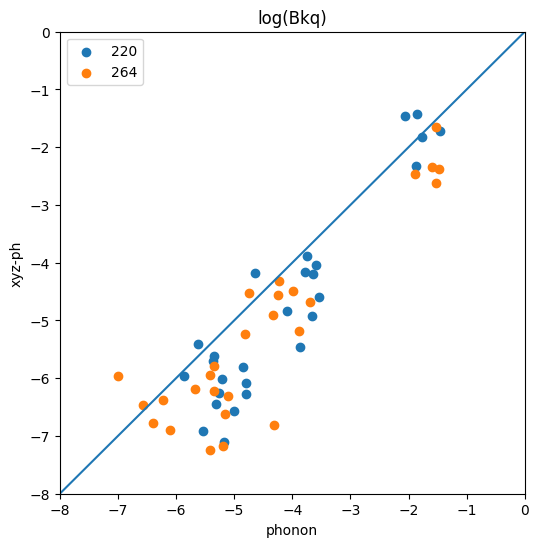

In [ ]:
mod1 = 219
mod2 = 263
standX = np.linspace(-100,100,100)

B_slope_2nd = np.zeros([27],dtype = float)
with open("inpfile/CFPsorca_1.out","r") as file:
    npts = 10
    B220 = np.empty([npts,27], dtype = float)
    for j in range(0,npts):
        line = file.readline()
        #i = int(line.split()[1])-1
        line = file.readline()
        B2 = line.split()
        B220[j,0:5] = B2
        line = file.readline()
        B4 = line.split()
        B220[j,5:14] = B4
        line = file.readline()
        B6 = line.split()
        B220[j,14:27] = B6   
    B220= np.insert(B220,(npts+1)//2,0,axis=0) #add the eq perturbation CFPs
    B264 = np.empty([npts,27], dtype = float)
    for j in range(0,npts):
        line = file.readline()
        #i = int(line.split()[1])-1
        line = file.readline()
        B2 = line.split()
        B264[j,0:5] = B2
        line = file.readline()
        B4 = line.split()
        B264[j,5:14] = B4
        line = file.readline()
        B6 = line.split()
        B264[j,14:27] = B6    
    B264= np.insert(B264,(npts+1)//2,0,axis=0) #add the eq perturbation CFPs


X = [-1,-0.8,-0.6,-0.4,-0.2,0,0.2,0.4,0.6,0.8,1]
order = 2
B_slope = np.empty([2,27], dtype = float)
for j in range(0,27):
    #print(B220[...,j])
    B_slope[0,j] = np.polyfit(X, B220[...,j], order)[int(order-1)]
    B_slope[1,j] = np.polyfit(X, B264[...,j], order)[int(order-1)]
                
fig = plt.figure(figsize=(6, 6))
X = np.zeros([27],dtype = float)
Y = np.zeros([27],dtype = float)
#table = PrettyTable(["Ph","xyz-ph","ratio"])
for j in range(0,27):
    X[j] = np.log10(abs(B_slope[0,j]))
    Y[j] = np.log10(abs(CFPs.B_slope[mod1,j]))
    #table.add_row([E_slope_ph[0,j],E_slope[mod1,j],Y[j]])
#print(table)
plt.scatter(X,Y,marker='o',label="220")

for j in range(0,27):
    X[j] = np.log10(abs(B_slope[1,j]))
    Y[j] = np.log10(abs(CFPs.B_slope[mod2,j]))
    #table.add_row([E_slope_ph[0,j],E_slope[mod1,j],Y[j]])
#print(table)
plt.scatter(X,Y,marker='o',label="264")



plt.plot(standX,standX)
plt.xlabel("phonon")
plt.ylabel("xyz-ph")
plt.legend()
plt.title("log(Bkq)")
plt.xlim(-8,0)
plt.ylim(-8,0)
plt.show()

Range: 2.0
[0]
Start select group
[0]
output dpxs
1
only consider the xzymodes of the nearest atoms


c:\Users\10122\Documents\0File\AStudy\Project\SMM\Calculate\DyCp_Orcapyscf\Select_group.py:183: FutureWarning: Please use len(self) or, if your atoms are distributed, self.get_global_number_of_atoms.
  dpxs = np.zeros([orig.get_number_of_atoms(),3],dtype = int)
c:\Users\10122\Documents\0File\AStudy\Project\SMM\Calculate\DyCp_Orcapyscf\Select_group.py:74: FutureWarning: Please use len(self) or, if your atoms are distributed, self.get_global_number_of_atoms.
  dpxs = np.zeros([orig.get_number_of_atoms(),3],dtype = int)
c:\Users\10122\Documents\0File\AStudy\Project\SMM\Calculate\DyCp_Orcapyscf\Select_group.py:76: FutureWarning: Please use len(self) or, if your atoms are distributed, self.get_global_number_of_atoms.
  for i in range(0,orig.get_number_of_atoms()):
c:\Users\10122\Documents\0File\AStudy\Project\SMM\Calculate\DyCp_Orcapyscf\Select_group.py:225: FutureWarning: Please use len(self) or, if your atoms are distributed, self.get_global_number_of_atoms.
  print(new.get_number_of_atom

Range: 2.103448275862069
[0]
Start select group
[0]
output dpxs
1
only consider the xzymodes of the nearest atoms
Range: 2.206896551724138
[0]
Start select group
[0]
output dpxs
1
only consider the xzymodes of the nearest atoms
Range: 2.310344827586207
[0]
Start select group
[0]
output dpxs
1
only consider the xzymodes of the nearest atoms
Range: 2.413793103448276
[0]
Start select group
[0]
output dpxs
1
only consider the xzymodes of the nearest atoms
Range: 2.5172413793103448
[0]
Start select group
[0]
output dpxs
1
only consider the xzymodes of the nearest atoms
Range: 2.6206896551724137
[0 1 6]
Start select group
[0 1 6]
output dpxs
3
only consider the xzymodes of the nearest atoms
Range: 2.7241379310344827
[ 0  1  2  5  6 35 62 65]
Start select group
[ 0  1  2  5  6 35 62 65]
output dpxs
8
only consider the xzymodes of the nearest atoms
Range: 2.8275862068965516
[ 0  1  2  3  5  6 10 34 35 39 61 62 65]
Start select group
[ 0  1  2  3  5  6 10 34 35 39 61 62 65]
output dpxs
13
only 

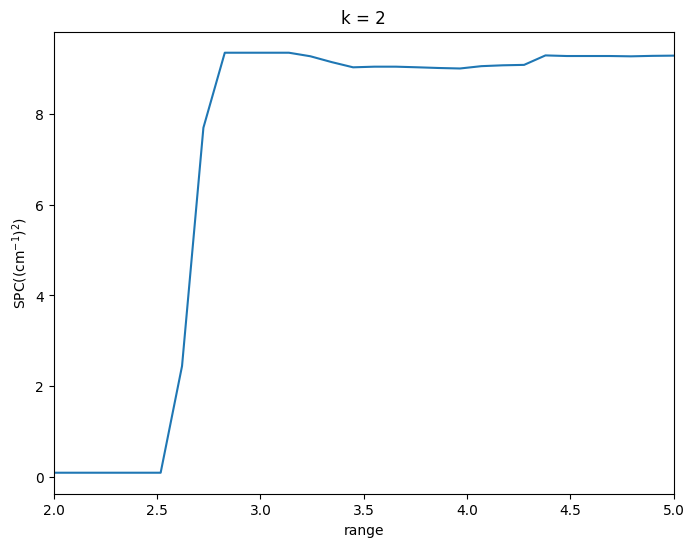

In [2]:
def density_spc_nmds(CFPs,mol,maxAA,nmds_list,filename):
    minAA = 2.0
    fig = plt.figure(figsize=(8, 6))
    x = np.linspace(minAA, maxAA, 30)
    y = np.zeros([30],dtype=float)
    Num = np.zeros([30],dtype=float)
    for k in range(0,30):
        AAk = x[k]
        print("Range:",AAk)
        origgr,newgr,atoms_label=choose_group('inpfile/eq_opt.xyz','Dy','./',AAk,0)
        Num[k] = newgr.get_number_of_atoms()
        CFPs.gen_slope_reduced(atoms_label)  # get slope of Bkq for selected modes
        CFPs.transB_sl_new(mol.freqs,mol.eigenvects,mol.atom_m)
        #CFPs.transB_sl(mol.vecs)
        Ba = 0#np.zeros([nmds],dtype=float)
        theta_2 = 1#-2/315
        theta_4 = 1#-8/135135
        theta_6 = 1#4/3864861
        for i in nmds_list:
            for j in range(0,5):
                Ba += (CFPs.B_slope[i,j]/theta_2)**2
            for j in range(5,14):
                Ba += (CFPs.B_slope[i,j]/theta_4)**2
            for j in range(14,27):
                Ba += (CFPs.B_slope[i,j]/theta_6)**2
        y[k] = Ba
    plt.plot(x,y)
    plt.xlim(minAA,maxAA)
    #plt.ylim(-200,200)
    #plt.legend(loc=0,ncol=1)
    plt.title("k = {x}".format(x = 2)) 
    plt.xlabel("range") 
    plt.ylabel("SPC((cm$^{-1}$)$^{2}$)") 
    np.savetxt(filename+'.txt',y)
    plt.savefig(filename+'.png',bbox_inches='tight')
    plt.show()

density_spc_nmds(CFPs,mol,5.0,Modes_list,"SPC_nmds")

<>:72: SyntaxWarning: invalid escape sequence '\m'
<>:73: SyntaxWarning: invalid escape sequence '\m'
<>:72: SyntaxWarning: invalid escape sequence '\m'
<>:73: SyntaxWarning: invalid escape sequence '\m'
C:\Users\10122\AppData\Local\Temp\ipykernel_27248\3402769964.py:72: SyntaxWarning: invalid escape sequence '\m'
  figs1.set_title("$\mathit{T}$ "+"= {x} K to {y} K".format(x = int(Tmin),y = int(Tmax)))
C:\Users\10122\AppData\Local\Temp\ipykernel_27248\3402769964.py:73: SyntaxWarning: invalid escape sequence '\m'
  figs1.set_xlabel("$\mathit{T}^{-1}$ (K$^{-1}$)")


TypeError: draw_std_line() takes 5 positional arguments but 6 were given

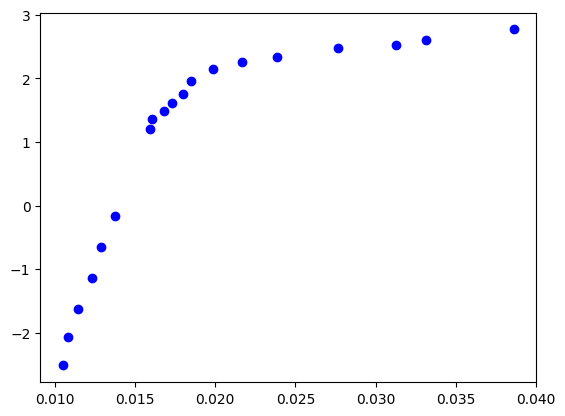

In [ ]:
"""
If_Simplified: True
SimVP_filename: "inpfile/test2/VP_exp12_rt_mode_gs"
SimTPs_foldname: "TPs_test2/TP_exp12_rt_mode_sig10_gs"
nloop: 5
Simsigma: 10
"""
def read_RTfile(filename):
    ad = np.loadtxt(filename)
    RMTlist = ad[...,0]
    RMavg = ad[...,1]
    RMstd = ad[...,2]
    return RMTlist,RMavg,RMstd

Tr_format,logtime_format = get_format_XY()

figs1 = plt.figure(num='Figs1').add_subplot(111)
figs1.plot(Tr_format,logtime_format,"ob",label='Exp')  #log(t)-T^-1
"""
Draw the data you pre-entered in .yml
"""

filename = "dis-ave/AllOB.dat"
OBTlist,OBavg,OBstd = read_RTfile(filename)
#draw_std_line('OB_AE',1,-OBavg,OBstd,OBTlist,10)
draw_std_line_new('OB_AE',1,-OBavg,OBstd,OBTlist,10)
lnOBavg = np.log(10**OBavg)
OBimfor = np.polyfit(OBTlist, lnOBavg, 1) 
logOBtau = np.log10(np.exp(OBimfor[1]))
print(Mlabel+"U_{eff} of Orbach is "+'%1.1f'%OBimfor[0]+" K")
print("log(tau) is "+'%1.2f'%logOBtau+" s")

# filename = "TPs_file/OB_all.dat"
# OBTlist,OBavg,OBstd = read_RTfile(filename)
# draw_std_line_new('OB_DMET',2,-OBavg,OBstd,OBTlist,nloop)
# filename = "TPs_file/OB_29.dat"
# OBTlist,OBavg,OBstd = read_RTfile(filename)
# draw_std_line_new('OB_2.9',2,-OBavg,OBstd,OBTlist,nloop)
# filename = "TPs_file/OB_se.dat"
# OBTlist,OBavg,OBstd = read_RTfile(filename)
# draw_std_line_new('OB_se',3,-OBavg,OBstd,OBTlist,nloop)

# j = 277
# k = 276
# omega0 = 1257
# omega1 = mol.freqs[j]
# omega2 = mol.freqs[k]
# omega3 = mol.freqs[274]

# k0=const.hbar*2*np.pi*const.c*omega0/const.kb
# b0 = 11.83
# k1=const.hbar*2*np.pi*const.c*omega1/const.kb
# b1 = -2.69
# k2=const.hbar*2*np.pi*const.c*omega2/const.kb
# b2 = -2.55
# k3=const.hbar*2*np.pi*const.c*omega3/const.kb
# b3 = -3.45


# print(np.exp(k1*0.1))
# x = np.linspace(0,0.1,10)
# y1 = np.exp(-k1*x)*10**b1
# y2 = np.exp(-k2*x)*10**b2
# y3 = np.exp(-k3*x)*10**b3
# print(np.log(1/y1))
# figs1.plot(x,np.log10(1/y1),label=r"$\mathit{\alpha}$")
# figs1.plot(x,np.log10(1/y2),label=r"$\mathit{\beta}$")
# figs1.plot(x,np.log10(1/y3),label=r"$\mathit{\gamma}$")
# figs1.plot(x,np.log10(1/(y1+y2+y3)),label=r"$\mathit{\alpha}+\mathit{\beta}$")

Tmin = T_list[0]
Tmax = np.max(T_list)
figs1.set_title("$\mathit{T}$ "+"= {x} K to {y} K".format(x = int(Tmin),y = int(Tmax))) 
figs1.set_xlabel("$\mathit{T}^{-1}$ (K$^{-1}$)") 
figs1.set_ylabel(r"log($\mathit{\tau}$) (s)") 
#figs1.set_xlim(0,0.025)
#figs1.set_ylim(-4,6)
figs1.yaxis.set_major_locator(MultipleLocator(2))

#fig1.xaxis.set_major_locator(MultipleLocator(0.01))
#plt.xticks(1/T_list,T_list)



plt.legend(frameon=False,bbox_to_anchor=(1, 0),loc=4,ncol=1)
plt.savefig("TPss1.eps",bbox_inches='tight')
plt.show()
#TP90_0.Mod_Analyse_OB(0)
#TP90_0.Mod_Analyse_RM(0)
#TP80_0.Mod_Analyse_OB(0)
#TP80_0_0.Mod_Analyse_OB(-1)
#TP80_0_0.Mod_Analyse_RM(-1)
#TP40_0_0.Mod_Analyse_RM(-1)
TP15_0_0.Mod_Analyse_OB(-1)
#TP10_0_0.Mod_Analyse_RM(-1)
#TP100_0.Mod_Analyse_OB(0)
#TP20_0.Mod_Analyse_RM(0)
#print(TP30_0.OBTP)
#print(TP30_0.OBrate)
#print(TP35_0.OBrate)
#print(TP30_0.OBrate)

#print(TP60_0.testS)
#print(TP60_0.U)
#print(TP60_0.Vh)

#print(TP40_0.testS)
#print(TP40_0.U)
#print(TP40_0.Vh)
#print(TP45_0.OBrate)

#print(TP100_0.OBrate)
#print(TP100_0.testS)
#print(TP45_0.OBrate)
#print(TP40_0.OBTP)
#TP100_3.Mod_Analyse_RM(3)
#TP100_0.Mod_Analyse_OB(0)
#TP30_0.Mod_Analyse_OB(0)
#TP20_0.Mod_Analyse_RM(0)
#TP25_0.Mod_Analyse_RM(0)
# TP80_2.Mod_Analyse_OB(1)
# TP70_2.Mod_Analyse_OB(1)
# TP60_2.Mod_Analyse_OB(1)

In [29]:
f = 1
i = 0
k = 276
j = 277
a = 0
omega1 = mol.freqs[j]
omega2 = mol.freqs[k]
#VP_filename = "inpfile/VP_exp_Cp_diag_mf.log"
VP_filename = "inpfile/test2/VP_exp12_rt_mode.log"
#VP_filename = "inpfile/VP_exp_CPmf_mode.log"
#VP_filename = "inpfile/VPori_exp_Cp_diag.log"
if Path(VP_filename).is_file():
    print("yes")
    Eigen.read_sph_matrix(VP_filename)
table = PrettyTable(["i","V1","V2","dE+","dE-","s1","s2","a","da","a2"]) 
for c in range(0,Eigen.n_states):
    if Eigen.Vaules[c]<5000:
        #da = Eigen.VP[f,c,j]*Eigen.VP[c,i,k]/(Eigen.Vaules[c]-Eigen.Vaules[i]-omega1)
        da = Eigen.VP[f,c,j]*Eigen.VP[c,i,k]/(Eigen.Vaules[c]-Eigen.Vaules[i]+omega2)+Eigen.VP[f,c,k]*Eigen.VP[c,i,j]/(Eigen.Vaules[c]-Eigen.Vaules[i]-omega1)
        s1 = Eigen.VP[f,c,j]*Eigen.VP[c,i,k]/(Eigen.Vaules[c]-Eigen.Vaules[i]+omega2)
        s2 = Eigen.VP[f,c,k]*Eigen.VP[c,i,j]/(Eigen.Vaules[c]-Eigen.Vaules[i]-omega1)
        #da = Eigen.VP[f,c,j]*Eigen.VP[c,i,k]+Eigen.VP[f,c,k]*Eigen.VP[c,i,j]
        print(Eigen.Vaules[c],Eigen.Vaules[i],omega1,omega2)
        a = a+da
        a2 = get_Mod_square(a)
        table.add_row([c,'%1.1e'%(Eigen.VP[f,c,j]*Eigen.VP[c,i,k]).real+","+'%1.1e'%(Eigen.VP[f,c,j]*Eigen.VP[c,i,k]).imag+'j',\
                       '%1.1e'%(Eigen.VP[f,c,k]*Eigen.VP[c,i,j]).real+","+'%1.1e'%(Eigen.VP[f,c,k]*Eigen.VP[c,i,j]).imag+'j',\
                        '%1.2e'%(Eigen.Vaules[c]-Eigen.Vaules[i]+omega2),\
                        '%1.2e'%(Eigen.Vaules[c]-Eigen.Vaules[i]-omega1),\
                        '%1.2e'%s1.real+","+'%1.2e'%s1.imag+'j',\
                        '%1.2e'%s2.real+","+'%1.2e'%s2.imag+'j',\
                        '%1.2e'%a.real+","+'%1.2e'%a.imag+'j',\
                        '%1.5e'%da.real+","+'%1.5e'%da.imag+'j',\
                        '%1.2e'%a2])
print(table)
"""
table.add_row([c,'%1.1e'%(Eigen.VP[f,c,j]*Eigen.VP[c,i,k]).real+","+'%1.1e'%(Eigen.VP[f,c,j]*Eigen.VP[c,i,k]).imag+'j',\
    '%1.1e'%(Eigen.VP[f,c,k]*Eigen.VP[c,i,j]).real+","+'%1.1e'%(Eigen.VP[f,c,k]*Eigen.VP[c,i,j]).imag+'j',\
    '%1.2e'%(Eigen.Vaules[c]-Eigen.Vaules[i]+omega2),\
    '%1.2e'%(Eigen.Vaules[c]-Eigen.Vaules[i]-omega1),\
    '%1.2e'%s1.real+","+'%1.2e'%s1.imag+'j',\
    '%1.2e'%s2.real+","+'%1.2e'%s2.imag+'j',\
    '%1.2e'%a.real+","+'%1.2e'%a.imag+'j',\
    '%1.5e'%da.real+","+'%1.5e'%da.imag+'j',\
    '%1.2e'%a2])
"""

yes
0.0 0.0 20.712868 38.761422
0.0 0.0 20.712868 38.761422
481.86100249 0.0 20.712868 38.761422
481.86100249 0.0 20.712868 38.761422
755.67250372 0.0 20.712868 38.761422
755.67250372 0.0 20.712868 38.761422
934.02605753 0.0 20.712868 38.761422
934.02605753 0.0 20.712868 38.761422
1094.99946264 0.0 20.712868 38.761422
1094.99946264 0.0 20.712868 38.761422
1247.45393569 0.0 20.712868 38.761422
1247.45393569 0.0 20.712868 38.761422
1366.83113592 0.0 20.712868 38.761422
1366.83113592 0.0 20.712868 38.761422
1446.56347659 0.0 20.712868 38.761422
1446.56347659 0.0 20.712868 38.761422
+----+--------------------+--------------------+----------+-----------+----------------------+----------------------+----------------------+----------------------------+----------+
| i  |         V1         |         V2         |   dE+    |    dE-    |          s1          |          s2          |          a           |             da             |    a2    |
+----+--------------------+--------------------+----

'\ntable.add_row([c,\'%1.1e\'%(Eigen.VP[f,c,j]*Eigen.VP[c,i,k]).real+","+\'%1.1e\'%(Eigen.VP[f,c,j]*Eigen.VP[c,i,k]).imag+\'j\',    \'%1.1e\'%(Eigen.VP[f,c,k]*Eigen.VP[c,i,j]).real+","+\'%1.1e\'%(Eigen.VP[f,c,k]*Eigen.VP[c,i,j]).imag+\'j\',    \'%1.2e\'%(Eigen.Vaules[c]-Eigen.Vaules[i]+omega2),    \'%1.2e\'%(Eigen.Vaules[c]-Eigen.Vaules[i]-omega1),    \'%1.2e\'%s1.real+","+\'%1.2e\'%s1.imag+\'j\',    \'%1.2e\'%s2.real+","+\'%1.2e\'%s2.imag+\'j\',    \'%1.2e\'%a.real+","+\'%1.2e\'%a.imag+\'j\',    \'%1.5e\'%da.real+","+\'%1.5e\'%da.imag+\'j\',    \'%1.2e\'%a2])\n'

In [28]:
f = 1
i = 0
k = 274
j = 275
a = 0
omega1 = mol.freqs[j]
omega2 = mol.freqs[k]
#VP_filename = "inpfile/VP_exp_Cp_diag_mf.log"
#VP_filename = "inpfile/test2/VP_exp12_rtp_xyz4.log"
VP_filename = "inpfile/VP_exp_CPmf_mode.log"
#VP_filename = "inpfile/VPori_exp_Cp_diag.log"
if Path(VP_filename).is_file():
    print("yes")
    Eigen.read_sph_matrix(VP_filename)
table = PrettyTable(["i","V1","V2","dE+","dE-","s1","s2","a","da","a2"]) 
for c in range(0,Eigen.n_states):
    if Eigen.Vaules[c]<5000:
        #da = Eigen.VP[f,c,j]*Eigen.VP[c,i,k]/(Eigen.Vaules[c]-Eigen.Vaules[i]-omega1)
        da = Eigen.VP[f,c,j]*Eigen.VP[c,i,k]/(Eigen.Vaules[c]-Eigen.Vaules[i]+omega2)+Eigen.VP[f,c,k]*Eigen.VP[c,i,j]/(Eigen.Vaules[c]-Eigen.Vaules[i]-omega1)
        s1 = Eigen.VP[f,c,j]*Eigen.VP[c,i,k]/(Eigen.Vaules[c]-Eigen.Vaules[i]+omega2)
        s2 = Eigen.VP[f,c,k]*Eigen.VP[c,i,j]/(Eigen.Vaules[c]-Eigen.Vaules[i]-omega1)
        #da = Eigen.VP[f,c,j]*Eigen.VP[c,i,k]+Eigen.VP[f,c,k]*Eigen.VP[c,i,j]
        print(Eigen.Vaules[c],Eigen.Vaules[i],omega1,omega2)
        a = a+da
        a2 = get_Mod_square(a)
        table.add_row([c,'%1.1e'%(Eigen.VP[f,c,j]*Eigen.VP[c,i,k]).real+","+'%1.1e'%(Eigen.VP[f,c,j]*Eigen.VP[c,i,k]).imag+'j',\
                       '%1.1e'%(Eigen.VP[f,c,k]*Eigen.VP[c,i,j]).real+","+'%1.1e'%(Eigen.VP[f,c,k]*Eigen.VP[c,i,j]).imag+'j',\
                        '%1.2e'%(Eigen.Vaules[c]-Eigen.Vaules[i]+omega2),\
                        '%1.2e'%(Eigen.Vaules[c]-Eigen.Vaules[i]-omega1),\
                        '%1.2e'%s1.real+","+'%1.2e'%s1.imag+'j',\
                        '%1.2e'%s2.real+","+'%1.2e'%s2.imag+'j',\
                        '%1.2e'%a.real+","+'%1.2e'%a.imag+'j',\
                        '%1.5e'%da.real+","+'%1.5e'%da.imag+'j',\
                        '%1.2e'%a2])
print(table)
"""
table.add_row([c,'%1.1e'%(Eigen.VP[f,c,j]*Eigen.VP[c,i,k]).real+","+'%1.1e'%(Eigen.VP[f,c,j]*Eigen.VP[c,i,k]).imag+'j',\
    '%1.1e'%(Eigen.VP[f,c,k]*Eigen.VP[c,i,j]).real+","+'%1.1e'%(Eigen.VP[f,c,k]*Eigen.VP[c,i,j]).imag+'j',\
    '%1.2e'%(Eigen.Vaules[c]-Eigen.Vaules[i]+omega2),\
    '%1.2e'%(Eigen.Vaules[c]-Eigen.Vaules[i]-omega1),\
    '%1.2e'%s1.real+","+'%1.2e'%s1.imag+'j',\
    '%1.2e'%s2.real+","+'%1.2e'%s2.imag+'j',\
    '%1.2e'%a.real+","+'%1.2e'%a.imag+'j',\
    '%1.5e'%da.real+","+'%1.5e'%da.imag+'j',\
    '%1.2e'%a2])
"""

yes
0.0 0.0 43.578574 52.13984
0.0 0.0 43.578574 52.13984
481.86100249 0.0 43.578574 52.13984
481.86100249 0.0 43.578574 52.13984
755.67250372 0.0 43.578574 52.13984
755.67250372 0.0 43.578574 52.13984
934.02605753 0.0 43.578574 52.13984
934.02605753 0.0 43.578574 52.13984
1094.99946264 0.0 43.578574 52.13984
1094.99946264 0.0 43.578574 52.13984
1247.45393569 0.0 43.578574 52.13984
1247.45393569 0.0 43.578574 52.13984
1366.83113592 0.0 43.578574 52.13984
1366.83113592 0.0 43.578574 52.13984
1446.56347659 0.0 43.578574 52.13984
1446.56347659 0.0 43.578574 52.13984
+----+--------------------+--------------------+----------+-----------+----------------------+----------------------+----------------------+----------------------------+----------+
| i  |         V1         |         V2         |   dE+    |    dE-    |          s1          |          s2          |          a           |             da             |    a2    |
+----+--------------------+--------------------+----------+---------

'\ntable.add_row([c,\'%1.1e\'%(Eigen.VP[f,c,j]*Eigen.VP[c,i,k]).real+","+\'%1.1e\'%(Eigen.VP[f,c,j]*Eigen.VP[c,i,k]).imag+\'j\',    \'%1.1e\'%(Eigen.VP[f,c,k]*Eigen.VP[c,i,j]).real+","+\'%1.1e\'%(Eigen.VP[f,c,k]*Eigen.VP[c,i,j]).imag+\'j\',    \'%1.2e\'%(Eigen.Vaules[c]-Eigen.Vaules[i]+omega2),    \'%1.2e\'%(Eigen.Vaules[c]-Eigen.Vaules[i]-omega1),    \'%1.2e\'%s1.real+","+\'%1.2e\'%s1.imag+\'j\',    \'%1.2e\'%s2.real+","+\'%1.2e\'%s2.imag+\'j\',    \'%1.2e\'%a.real+","+\'%1.2e\'%a.imag+\'j\',    \'%1.5e\'%da.real+","+\'%1.5e\'%da.imag+\'j\',    \'%1.2e\'%a2])\n'

yes


100%|██████████| 278/278 [00:26<00:00, 10.59it/s]

[-7.10059463 -7.72157679 -7.82939474 ... -7.77152713 -5.4286531
 -7.11658246]


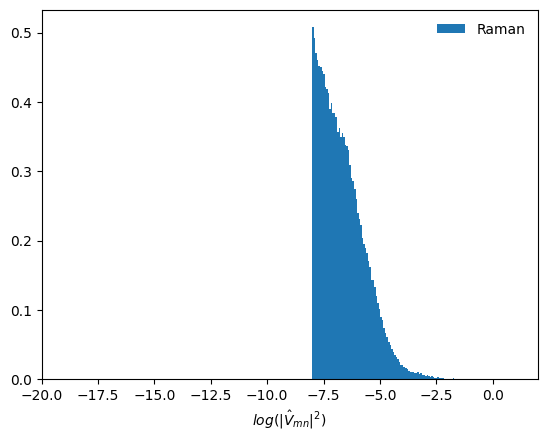

In [27]:
from tqdm import tqdm  
f = 2
i = 0
Vlist2 = np.empty((0,),dtype=float)
#VP_filename = "inpfile/VP_exp12_rt_xyz.log"
VP_filename = "inpfile/test2/VP_exp12_rt_per_gs1_0.log"
#VP_filename = "inpfile/VP_exp12_rt_mode3.log"
#VP_filename = "inpfile/VPori_exp_Cp_diag.log"
if Path(VP_filename).is_file():
    print("yes")
    Eigen.read_sph_matrix(VP_filename)
for k in tqdm(range(0,CFPs.nmds)):
    for j in range(0,CFPs.nmds):
        omega1 = mol.freqs[j]
        omega2 = mol.freqs[k]
        for c in range(0,Eigen.n_states):
            a = 0
            if Eigen.Vaules[c]<5000:
                #da = Eigen.VP[f,c,j]*Eigen.VP[c,i,k]/(Eigen.Vaules[c]-Eigen.Vaules[i]-omega1)
                da = Eigen.VP[f,c,j]*Eigen.VP[c,i,k]/(Eigen.Vaules[c]-Eigen.Vaules[i]+omega2)+Eigen.VP[f,c,k]*Eigen.VP[c,i,j]/(Eigen.Vaules[c]-Eigen.Vaules[i]-omega1)
                #s1 = Eigen.VP[f,c,j]*Eigen.VP[c,i,k]/(Eigen.Vaules[c]-Eigen.Vaules[i]+omega2)
                #s2 = Eigen.VP[f,c,k]*Eigen.VP[c,i,j]/(Eigen.Vaules[c]-Eigen.Vaules[i]-omega1)
                #da = Eigen.VP[f,c,j]*Eigen.VP[c,i,k]+Eigen.VP[f,c,k]*Eigen.VP[c,i,j]
                #print(Eigen.Vaules[c],Eigen.Vaules[i],omega1,omega2)
                a = a+da
            a2 = get_Mod_square(a)
            #a2 = max(1e-10,a2)
            if a2 > 1e-8:
                Vlist2 = np.append(Vlist2,np.log10(a2))
print(Vlist2)
figB = plt.figure(num='FigB').add_subplot(111)
n,bins,patchs=figB.hist(Vlist2, bins=100,density=True,label='Raman')
# #figB.set_title("$\mathit{T}$ "+"= {x} K to {y} K".format(x = int(Tmin),y = int(Tmax))) 
figB.set_xlabel("$log(|\hat{V}_{mn}|^2)$") 
# #figB.set_ylabel(r"log($\mathit{\tau}$) (s)") 
plt.legend(frameon=False,bbox_to_anchor=(1, 1),loc=1,ncol=1)
figB.set_xlim(-20,2)
plt.show()


In [68]:
#print(TP90_0.OBVector)
TP = TP90_0.OBTP
eigenvalues,Vector = np.linalg.eig(TP)
eigen = np.zeros([16,16],dtype = float)
for i in range(0,16):
    eigen[i,i] = eigenvalues[i]
rate = -eigenvalues
rate,Vector = Sort_EV(rate,Vector)
#print(eigenvalues[1]*Vector[:,1])
Vector1 = np.linalg.inv(Vector)
#print(np.dot(eigen,Vector1)-np.dot(Vector1,TP))
#print(np.dot(TP,Vector))
print(-rate)
print(-rate[1])
i = 0
a = 0
for j in range(0,16):
    a += Vector1[1,j]*TP[j,i]
    print(a,j)
print(a,-rate[1]*Vector1[1,i])

np.savetxt("Vector1file",Vector1)

[-2.34061258e-04 -3.66671721e+02 -3.49638362e+07 -3.55092550e+07
 -4.47895992e+10 -4.50198948e+10 -6.46997666e+10 -6.47797759e+10
 -1.11191202e+11 -4.43610937e+11 -6.77773114e+12 -6.79782858e+12
 -8.05185150e+12 -8.06648324e+12 -1.28549501e+13 -1.31786940e+13]
-366.67172111485667
13804.204290958136 0
13804.204290958136 1
13804.204290958136 2
13804.204290958136 3
13804.204290958136 4
13804.204290958136 5
13804.20432556997 6
11191.052599938002 7
259.1387995220375 8
259.15665485054143 9
259.15665485054143 10
259.15665485054143 11
259.1566548505418 12
259.15665485045383 13
259.1554130598457 14
259.1577907403045 15
259.1577907403045 259.1579850620367


466.430822


100%|██████████| 10000/10000 [19:02<00:00,  8.75it/s]


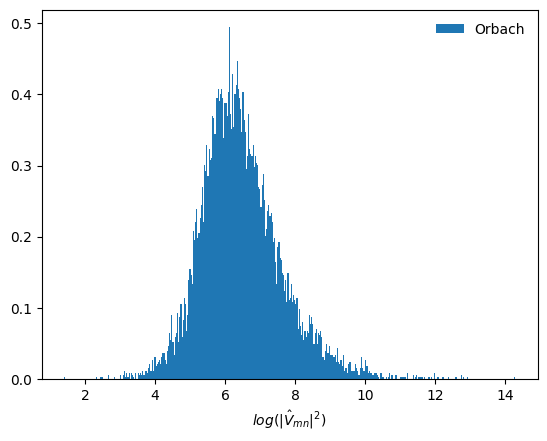

"k = 246\nj = 188\nomega1 = mol.freqs[j]\n#b1 = green_OB(omega_fi,omega1,sigma,T)  \nomega2 = mol.freqs[k]\nCFPs.read_CFPs()\nCFPs.gen_slope()\nfor ipt in range(0,number):\n    CFPs.random_CFPs_gs(10)     \n    a=0 \n    for c in range(0,Eigen.n_states):\n        V1 = Eigen.s_ph(f2,c,CFPs.B_slope[j,...])          \n        V2 = Eigen.s_ph(c,i,CFPs.B_slope[k,...]) \n        V3 = Eigen.s_ph(f2,c,CFPs.B_slope[k,...])          \n        V4 = Eigen.s_ph(c,i,CFPs.B_slope[j,...]) \n        da = V1*V2/(Eigen.Vaules[c]-Eigen.Vaules[i]+omega2)+V3*V4/(Eigen.Vaules[c]-Eigen.Vaules[i]-omega1)\n        #da = Eigen.VP[f2,c,j]*Eigen.VP[c,i,k]/(Eigen.Vaules[c]-Eigen.Vaules[i]+omega2)+Eigen.VP[f2,c,k]*Eigen.VP[c,i,j]/(Eigen.Vaules[c]-Eigen.Vaules[i]-omega1)\n        a = a+da\n    a2 = get_Mod_square(a)\n    #print(a2)\n    Vlist3 = np.append(Vlist3,np.log10(a2))\n\nfigC = plt.figure(num='FigB').add_subplot(111)\nn,bins,patchs=figC.hist(Vlist3, bins=400,density=True,label='2-0rm')\nplt.legend(frameon=Fal

In [3]:
from tqdm import tqdm  

T = 80
f = 2
i = 0
mod1 = 202
mod2 = 203
number = 10000
Vlist1 = np.empty((0,),dtype=float)
Vlist2 = np.empty((0,),dtype=float)
Vlist3 = np.empty((0,),dtype=float)
Blist = np.empty((0,),dtype=float)
omega_fi = Eigen.Vaules[f]-Eigen.Vaules[i]
omega_fi2 = Eigen.Vaules[f]-Eigen.Vaules[i]
omega1 = mol.freqs[mod1]
print(omega1)
#b1 = green_OB(omega_fi,omega1,sigma,T)  
omega2 = mol.freqs[mod2]
#b2 = green_OB(omega_fi,omega2,sigma,T) 
#widgets = ["doing task: ", progressbar.Percentage()," ", progressbar.Bar(), " ", progressbar.ETA()]


#pbar = progressbar.ProgressBar(maxval=number, widgets=widgets).start()
#Eigen.Expansion(1)
#Eigen.Expansion(3)
#Eigen.Expansion(8)


for ipt in tqdm(range(0,number)):
    CFPs.random_CFPs_llz(1.70,3.09)
    VPfi1 = Eigen.s_ph(f,i,CFPs.B_slope[mod1,...])          
    a = get_Mod_square(VPfi1)
    b = green_OB(omega_fi,omega1,sigma,T)
    VPfi2 = Eigen.s_ph(f,i,CFPs.B_slope[mod2,...])          
    a2 = get_Mod_square(VPfi2)
    b2 = green_OB(omega_fi,omega2,sigma,T)
    #b = phonon_strain(Eigen.Vaules[f],Eigen.Vaules[i],abs(omega_if),T)
    #c = Rou_omega(abs(omega_if),omega1,sigma)
    TPtemp =2*np.pi**2*(a*b+a2*b2)*const.c*1e10*(1-Delta(f,i))
    #rate = 2*np.pi**2*(a1*b1+a2*b2)*const.c*1e10*(1-Delta(f,i))  
    #time = np.log10(1/rate)
    Vlist1 = np.append(Vlist1,np.log10(TPtemp))
    #Vlist2 = np.append(Vlist2,np.log10(a2))
    #Blist = np.append(Vlist1,np.log10(a1))

np.savetxt(Out_foldname+"/Vlist.dat",Vlist1)
figB = plt.figure(num='FigB').add_subplot(111)
n,bins,patchs=figB.hist(Vlist1, bins=400,density=True,label='Orbach')
#n,bins,patchs=figB.hist(Vlist2, bins=400,density=True,label='Raman')
# #figB.set_title("$\mathit{T}$ "+"= {x} K to {y} K".format(x = int(Tmin),y = int(Tmax))) 
figB.set_xlabel("$log(|\hat{V}_{mn}|^2)$") 
# #figB.set_ylabel(r"log($\mathit{\tau}$) (s)") 
plt.legend(frameon=False,bbox_to_anchor=(1, 1),loc=1,ncol=1)
# figB.set_xlim(-4,0)
plt.show()
"""k = 246
j = 188
omega1 = mol.freqs[j]
#b1 = green_OB(omega_fi,omega1,sigma,T)  
omega2 = mol.freqs[k]
CFPs.read_CFPs()
CFPs.gen_slope()
for ipt in range(0,number):
    CFPs.random_CFPs_gs(10)     
    a=0 
    for c in range(0,Eigen.n_states):
        V1 = Eigen.s_ph(f2,c,CFPs.B_slope[j,...])          
        V2 = Eigen.s_ph(c,i,CFPs.B_slope[k,...]) 
        V3 = Eigen.s_ph(f2,c,CFPs.B_slope[k,...])          
        V4 = Eigen.s_ph(c,i,CFPs.B_slope[j,...]) 
        da = V1*V2/(Eigen.Vaules[c]-Eigen.Vaules[i]+omega2)+V3*V4/(Eigen.Vaules[c]-Eigen.Vaules[i]-omega1)
        #da = Eigen.VP[f2,c,j]*Eigen.VP[c,i,k]/(Eigen.Vaules[c]-Eigen.Vaules[i]+omega2)+Eigen.VP[f2,c,k]*Eigen.VP[c,i,j]/(Eigen.Vaules[c]-Eigen.Vaules[i]-omega1)
        a = a+da
    a2 = get_Mod_square(a)
    #print(a2)
    Vlist3 = np.append(Vlist3,np.log10(a2))

figC = plt.figure(num='FigB').add_subplot(111)
n,bins,patchs=figC.hist(Vlist3, bins=400,density=True,label='2-0rm')
plt.legend(frameon=False,bbox_to_anchor=(1, 1),loc=1,ncol=1)
#figC.set_xlim(-4,0)
plt.show()"""


#np.log10(1/Rate)

#np.savetxt("Vectorfile",TP90_0.OBVector)

100%|██████████| 10/10 [00:29<00:00,  2.98s/it]


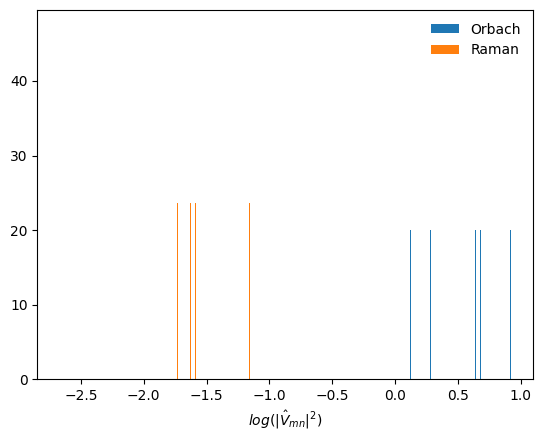

"k = 246\nj = 188\nomega1 = mol.freqs[j]\n#b1 = green_OB(omega_fi,omega1,sigma,T)  \nomega2 = mol.freqs[k]\nCFPs.read_CFPs()\nCFPs.gen_slope()\nfor ipt in range(0,number):\n    CFPs.random_CFPs_gs(10)     \n    a=0 \n    for c in range(0,Eigen.n_states):\n        V1 = Eigen.s_ph(f2,c,CFPs.B_slope[j,...])          \n        V2 = Eigen.s_ph(c,i,CFPs.B_slope[k,...]) \n        V3 = Eigen.s_ph(f2,c,CFPs.B_slope[k,...])          \n        V4 = Eigen.s_ph(c,i,CFPs.B_slope[j,...]) \n        da = V1*V2/(Eigen.Vaules[c]-Eigen.Vaules[i]+omega2)+V3*V4/(Eigen.Vaules[c]-Eigen.Vaules[i]-omega1)\n        #da = Eigen.VP[f2,c,j]*Eigen.VP[c,i,k]/(Eigen.Vaules[c]-Eigen.Vaules[i]+omega2)+Eigen.VP[f2,c,k]*Eigen.VP[c,i,j]/(Eigen.Vaules[c]-Eigen.Vaules[i]-omega1)\n        a = a+da\n    a2 = get_Mod_square(a)\n    #print(a2)\n    Vlist3 = np.append(Vlist3,np.log10(a2))\n\nfigC = plt.figure(num='FigB').add_subplot(111)\nn,bins,patchs=figC.hist(Vlist3, bins=400,density=True,label='2-0rm')\nplt.legend(frameon=Fal

In [ ]:
from tqdm import tqdm  

T = 60
f1 = 2
f2 = 2
i = 0
mod1 = 245
mod2 = 188
number = 1000
Vlist1 = np.empty((0,),dtype=float)
Vlist2 = np.empty((0,),dtype=float)
Vlist3 = np.empty((0,),dtype=float)
Blist = np.empty((0,),dtype=float)
omega_fi1 = Eigen.Vaules[f1]-Eigen.Vaules[i]
omega_fi2 = Eigen.Vaules[f1]-Eigen.Vaules[i]
omega1 = mol.freqs[mod1]
#b1 = green_OB(omega_fi,omega1,sigma,T)  
omega2 = mol.freqs[mod2]
#b2 = green_OB(omega_fi,omega2,sigma,T) 
#widgets = ["doing task: ", progressbar.Percentage()," ", progressbar.Bar(), " ", progressbar.ETA()]


#pbar = progressbar.ProgressBar(maxval=number, widgets=widgets).start()
#Eigen.Expansion(1)
#Eigen.Expansion(3)
#Eigen.Expansion(8)


for ipt in tqdm(range(0,number)):
    CFPs.random_CFPs_llz(llzA,llzw)
    VPfi1 = Eigen.s_ph(f1,i,CFPs.B_slope[mod1,...])          
    a1 = get_Mod_square(VPfi1)
    """VPfi2 = Eigen.s_ph(f2,i,CFPs.B_slope[mod2,...])  
    a1 = get_Mod_square(VPfi1)"""
    a = 0
    for c in range(0,Eigen.n_states):
        #da = Eigen.VP[f,c,j]*Eigen.VP[c,i,k]/(Eigen.Vaules[c]-Eigen.Vaules[i]-omega1)
        VP1 = Eigen.s_ph(f2,c,CFPs.B_slope[mod1,...])
        VP2 = Eigen.s_ph(c,i,CFPs.B_slope[mod2,...])
        VP3 = Eigen.s_ph(f2,c,CFPs.B_slope[mod2,...])
        VP4 = Eigen.s_ph(c,i,CFPs.B_slope[mod1,...])
        da = VP1*VP2/(Eigen.Vaules[c]-Eigen.Vaules[i]+omega2)+VP3*VP4/(Eigen.Vaules[c]-Eigen.Vaules[i]-omega1)
        #da = Eigen.VP[f,c,j]*Eigen.VP[c,i,k]+Eigen.VP[f,c,k]*Eigen.VP[c,i,j]
        a = a+da
    a2 = get_Mod_square(a)
    #rate = 2*np.pi**2*(a1*b1+a2*b2)*const.c*1e10*(1-Delta(f,i))  
    #time = np.log10(1/rate)
    Vlist1 = np.append(Vlist1,np.log10(a1))
    Vlist2 = np.append(Vlist2,np.log10(a2))
    #Blist = np.append(Vlist1,np.log10(a1))


figB = plt.figure(num='FigB').add_subplot(111)
n,bins,patchs=figB.hist(Vlist1, bins=400,density=True,label='Orbach')
n,bins,patchs=figB.hist(Vlist2, bins=400,density=True,label='Raman')
# #figB.set_title("$\mathit{T}$ "+"= {x} K to {y} K".format(x = int(Tmin),y = int(Tmax))) 
figB.set_xlabel("$log(|\hat{V}_{mn}|^2)$") 
# #figB.set_ylabel(r"log($\mathit{\tau}$) (s)") 
plt.legend(frameon=False,bbox_to_anchor=(1, 1),loc=1,ncol=1)
# figB.set_xlim(-4,0)
plt.show()
"""k = 246
j = 188
omega1 = mol.freqs[j]
#b1 = green_OB(omega_fi,omega1,sigma,T)  
omega2 = mol.freqs[k]
CFPs.read_CFPs()
CFPs.gen_slope()
for ipt in range(0,number):
    CFPs.random_CFPs_gs(10)     
    a=0 
    for c in range(0,Eigen.n_states):
        V1 = Eigen.s_ph(f2,c,CFPs.B_slope[j,...])          
        V2 = Eigen.s_ph(c,i,CFPs.B_slope[k,...]) 
        V3 = Eigen.s_ph(f2,c,CFPs.B_slope[k,...])          
        V4 = Eigen.s_ph(c,i,CFPs.B_slope[j,...]) 
        da = V1*V2/(Eigen.Vaules[c]-Eigen.Vaules[i]+omega2)+V3*V4/(Eigen.Vaules[c]-Eigen.Vaules[i]-omega1)
        #da = Eigen.VP[f2,c,j]*Eigen.VP[c,i,k]/(Eigen.Vaules[c]-Eigen.Vaules[i]+omega2)+Eigen.VP[f2,c,k]*Eigen.VP[c,i,j]/(Eigen.Vaules[c]-Eigen.Vaules[i]-omega1)
        a = a+da
    a2 = get_Mod_square(a)
    #print(a2)
    Vlist3 = np.append(Vlist3,np.log10(a2))

figC = plt.figure(num='FigB').add_subplot(111)
n,bins,patchs=figC.hist(Vlist3, bins=400,density=True,label='2-0rm')
plt.legend(frameon=False,bbox_to_anchor=(1, 1),loc=1,ncol=1)
#figC.set_xlim(-4,0)
plt.show()"""


#np.log10(1/Rate)

7506
(401,)
(400,)
[-592.10787511 -588.69160792 -585.27534073 -581.85907354 -578.44280635
 -575.02653916 -571.61027197 -568.19400478 -564.77773759 -561.3614704
 -557.94520321 -554.52893602 -551.11266883 -547.69640165 -544.28013446
 -540.86386727 -537.44760008 -534.03133289 -530.6150657  -527.19879851
 -523.78253132 -520.36626413 -516.94999694 -513.53372975 -510.11746256
 -506.70119537 -503.28492818 -499.868661   -496.45239381 -493.03612662
 -489.61985943 -486.20359224 -482.78732505 -479.37105786 -475.95479067
 -472.53852348 -469.12225629 -465.7059891  -462.28972191 -458.87345472
 -455.45718753 -452.04092035 -448.62465316 -445.20838597 -441.79211878
 -438.37585159 -434.9595844  -431.54331721 -428.12705002 -424.71078283
 -421.29451564 -417.87824845 -414.46198126 -411.04571407 -407.62944688
 -404.2131797  -400.79691251 -397.38064532 -393.96437813 -390.54811094
 -387.13184375 -383.71557656 -380.29930937 -376.88304218 -373.46677499
 -370.0505078  -366.63424061 -363.21797342 -359.80170623 -3

c:\Users\10122\AppData\Local\Programs\Python\Python312\Lib\site-packages\numpy\lib\histograms.py:885: RuntimeWarning: invalid value encountered in divide
  return n/db/n.sum(), bin_edges


0.8472813257242207 65.44833208074904


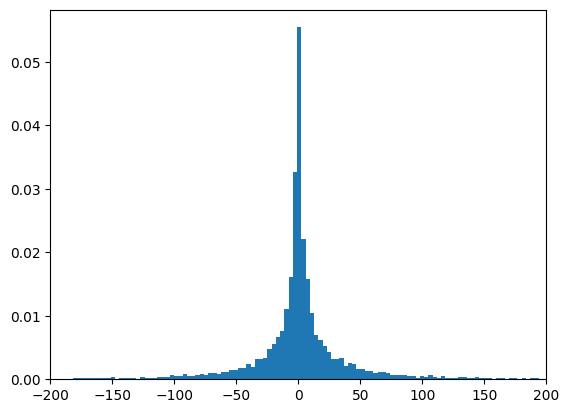

KstestResult(statistic=0.37534346447589884, pvalue=0.0, statistic_location=2.155948952846863, statistic_sign=-1)


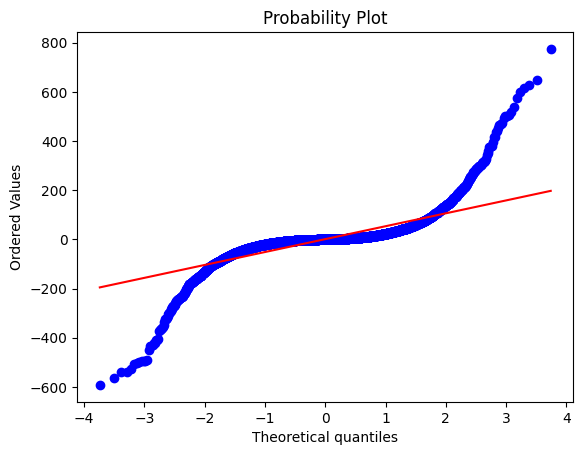

In [14]:
from scipy import stats
CFPs.read_CFPs()
B = CFPs.Line_CFPs()
np.savetxt(Out_foldname+"/Btheta.dat",B)
print(B.size)
B_new = []
A_new = []
lim = 200
A = []
# A = np.random.normal(0,1,9000)
# A2 = np.random.normal(0,5,6000)
# A3 = np.random.normal(0,10,3000)
# A4 = np.random.uniform(-200,200,3000)
# A = np.append(A,A2)
# A = np.append(A,A3)
# A = np.append(A,A4)
# for k in range(0,10000):
#     num = np.random.randint(1,8)
#     if num <= 3:
#         A.append(np.random.normal(loc=0.0, scale=1))
#     if num > 3 and num <= 5:
#         A.append(np.random.normal(loc=0.0, scale=5))
#     if num == 6:
#         A.append(np.random.normal(loc=0.0, scale=10))
#     if num == 7:
#         A.append(np.random.random()*400-200)
for i in range(0,np.shape(B)[0]):
    if B[i] <= lim and B[i] >= -lim:
        B_new.append(10*B[i])
# for i in range(0,np.shape(A)[0]):
#     if A[i] <= lim and A[i] >= -lim:
#         A_new.append(A[i])
figB = plt.figure(num='FigB').add_subplot(111)
n,bins,patchs=figB.hist(B_new, bins=400,density=True)
print(np.shape(bins))
print(np.shape(n))
print(bins)
#np.savetxt(Out_foldname+"/distri.dat",np.column_stack((bins,n)))
n,bins,patchs=figB.hist(A_new, bins=400,density=True)
figB.set_xlim(-lim,lim)
#figB.set_ylim(0,0.05)
#B = [-1,0,1]
#B = np.random.normal(0,10,1000)
avg=np.mean(B_new)
std=np.std(B_new)
print(avg,std)
# avg=np.mean(A_new)
# std=np.std(A_new)
# print(avg,std)
plt.savefig("PB_acac.png",bbox_inches='tight')
plt.show()



#A = np.random.normal(0,10,1000)
B = np.sort(B_new)
stats.probplot(B_new,dist="norm",plot=plt)
plt.savefig("QQ_acac.png",bbox_inches='tight')
p = stats.kstest(B_new,"norm")
print(p)


T = 80K
2.26e+01 2.26e+01 2.35e+03 0.0047984446193518725
T = 90K
3.67e+02 3.67e+02 1.95e+04 0.009391186829806478
T = 100K
3.47e+03 3.46e+03 1.07e+05 0.01614055747991533


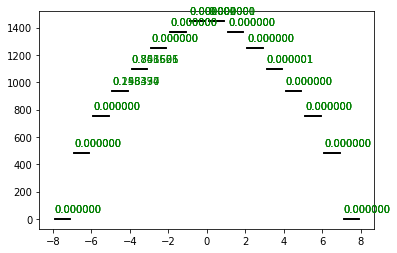

In [29]:
for T in T_list:
    if T < 50:
        continue
    else:
        T = int(T)
        name = 'TP{x}_{y}'.format(x=T,y=0)
        print("T = {x}K".format(x=T))
        P_states = np.zeros([16],dtype = float)
        P_states_temp = np.zeros([16],dtype = float)
        OBTP = locals()[name].OBTP
        OBTPP = locals()[name].OBTPP
        OBrate = locals()[name].OBrate
        for i in range(1,16):
            P_states[i] = -OBTP[i,0]/OBTP[0,0]
        for i in range(0,16):
            x = [Eigen.JAN[i]-0.4,Eigen.JAN[i]+0.4]
            y = [Eigen.Vaules[i],Eigen.Vaules[i]]
            plt.plot(x,y,color='k')
        for i in range(0,16):  
            plt.text(Eigen.JAN[i]-0.4, Eigen.Vaules[i]+50, '%1.6f'%P_states[i], fontsize=10, color='green')
        # figOBT = plt.figure(num='FigOBT').add_subplot(111)
        # figOBT.set_title("Transition probability for Orbach at {T}K".format(T = T)) 
        # figOBT.set_xlabel("<J$_Z$>") 
        # figOBT.set_ylabel("Energy(cm$^{-1}$)") 
        # plt.show()
        #print(P_states[0],'%1.6f'%P_states[1])
        while True:
            P_states_temp = np.zeros([16],dtype = float)
            for i in range(0,16):
                for j in range(2,16):
                    P_states_temp[i] += OBTPP[i,j]*P_states[j]
            P_states_temp[0] = P_states_temp[0]+P_states[0]
            P_states_temp[1] = P_states_temp[1]+P_states[1]
            P_states = P_states_temp  
            #print(P_states)

            # figOBT = plt.figure(num='FigOBT').add_subplot(111)
            # figOBT.scatter(Eigen.JAN,Eigen.Vaules,color='k')        
            # CL_fmt = ['purple','lemonchiffon','yellow','orange','orangered','red','crimson']
            # cl = CL_fmt[0]
            # for i in range(0,16):
            #     x = [Eigen.JAN[i]-0.4,Eigen.JAN[i]+0.4]
            #     y = [Eigen.Vaules[i],Eigen.Vaules[i]]
            #     plt.plot(x,y,color='k')
            # for i in range(0,16):  
            #     plt.text(Eigen.JAN[i]-0.4, Eigen.Vaules[i]+50, '%1.8f'%P_states[i], fontsize=10, color='green')
            # figOBT.set_title("Transition probability for Orbach at {T}K".format(T = T)) 
            # figOBT.set_xlabel("<J$_Z$>") 
            # figOBT.set_ylabel("Energy(cm$^{-1}$)") 
            # plt.show()
            if P_states[0]+P_states[1]>0.99999999:
                print('%1.2e'%(-OBTP[0,0]*P_states[1]*2),'%1.2e'%OBrate[1], '%1.2e'%(-OBTP[0,0]),P_states[1])
                #print('%1.2e'%(-OBTP[0,0]),P_states[1])
                break

RM
T = 80K
2.63e+04 2.63e+04 2.84e+06 0.004628163038853553
T = 90K
3.73e+05 3.73e+05 1.05e+07 0.017728922033295746
T = 100K
2.84e+06 2.84e+06 3.34e+07 0.04260434362625983
OB
T = 80K
2.26e+01 2.26e+01 2.35e+03 0.0047984446193518725
T = 90K
3.67e+02 3.67e+02 1.95e+04 0.009391186829806478
T = 100K
3.47e+03 3.46e+03 1.07e+05 0.01614055747991533

In [37]:
from numpy.random import RandomState
rng = RandomState(123456)

num_v = 4

weights = rng.uniform(0, 1, num_v * num_v).reshape((num_v, num_v))
weights = np.tril(weights) + np.triu(weights.T, 1)
np.fill_diagonal(weights, 0)

degrees = weights.sum(axis=0)

degrees_rw = 1 / degrees
D_rw = np.diag(degrees_rw)

degrees = 1 / np.sqrt(degrees)
D = np.diag(degrees)

I = np.eye(num_v)

laplacian = I - np.matmul(np.dot(D, weights), D)

eigenvalues,Vector = eig(laplacian)
rate = -eigenvalues
rate,Vector = Sort_EV(rate,Vector)
U,S,Vh= np.linalg.svd(laplacian, full_matrices=True, compute_uv=True)
print(-rate)
print(S)

[1.57642803+0.j 1.40644541+0.j 1.01712657+0.j 0.        +0.j]
[1.57642803e+00 1.40644541e+00 1.01712657e+00 1.73174256e-16]


C:\Users\10122\AppData\Local\Temp\ipykernel_32232\1588556788.py:9: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(frameon=False,bbox_to_anchor=(1, 0),loc=4,ncol=1)


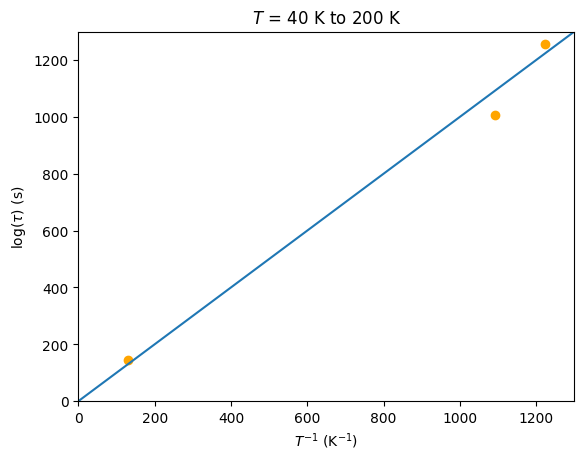

In [112]:
Expf = [129.9,1223,1093]
Full = [143.4,1257,1006]
Exps = []
Sim = []
x = [0, 1300]
y = [0, 1300]
fig3 = plt.figure(num='Fig3').add_subplot(111)
plt.figure("Fig3")
plt.legend(frameon=False,bbox_to_anchor=(1, 0),loc=4,ncol=1)
plt.plot(x, y)
plt.scatter(Expf, Full, c='orange', label='Full')
fig3.set_xlim(0,1300)
fig3.set_ylim(0,1300)
fig3.set_title("$\mathit{T}$ "+"= {x} K to {y} K".format(x = int(Tmin),y = int(Tmax))) 
fig3.set_xlabel("$\mathit{T}^{-1}$ (K$^{-1}$)") 
fig3.set_ylabel(r"log($\mathit{\tau}$) (s)") 
plt.show()


[4.01012006]


C:\Users\10122\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 27010 (\N{CJK UNIFIED IDEOGRAPH-6982}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\10122\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 29575 (\N{CJK UNIFIED IDEOGRAPH-7387}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\10122\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 23494 (\N{CJK UNIFIED IDEOGRAPH-5BC6}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\10122\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 24230 (\N{CJK UNIFIED IDEOGRAPH-5EA6}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\10122\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py

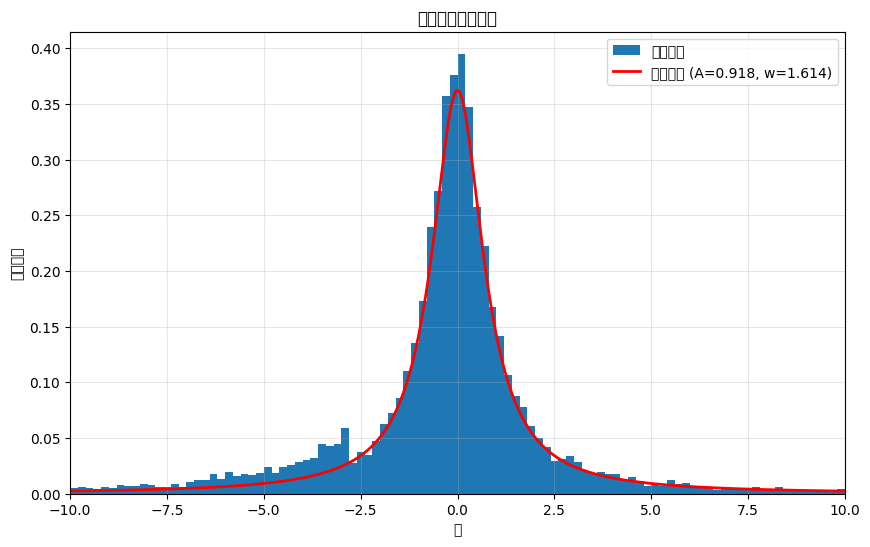

In [21]:
import numpy as np
import matplotlib.pyplot as plt

def generate_custom_lorentz(A, w, size=1):
    """
    生成符合指定洛伦兹分布的随机数
    分布公式：y = (2*A/pi)*(w/(4*x^2 + w^2))
    
    参数:
        A: 振幅参数
        w: 宽度参数
        size: 生成的随机数数量，默认值为1
        
    返回:
        符合指定洛伦兹分布的随机数数组
    """
    # 生成[0, 1)区间的均匀分布随机数
    uniform_rvs = np.random.uniform(0, 1, size)
    
    # 根据逆变换法，从指定的洛伦兹分布生成随机数
    # 推导过程：通过对分布函数求逆得到此转换公式
    lorentz_rvs = (w / 2) * np.tan(np.pi * (uniform_rvs/A - 1/2))
    
    return lorentz_rvs

# 示例用法
if __name__ == "__main__":
    # 设置参数
    A = 0.918         # 振幅参数
    w = 1.614         # 宽度参数
    sample_size = 10000  # 样本数量
    print(generate_custom_lorentz(A=A, w=w))
    
    # 生成随机数
    lorentz_samples = generate_custom_lorentz(A=A, w=w, size=sample_size)
    
    # 绘制直方图以可视化分布
    plt.figure(figsize=(10, 6))
    plt.hist(lorentz_samples, bins=100,range=(-10,10), density=True, label='采样结果')
    
    # 绘制理论概率密度函数进行对比
    x = np.linspace(-10, 10, 1000)
    y = (2 * A / np.pi) * (w / (4 * x**2 + w**2))  # 指定的分布公式
    plt.plot(x, y, 'r-', lw=2, label=f'理论分布 (A={A}, w={w})')
    
    plt.title('自定义洛伦兹分布')
    plt.xlabel('值')
    plt.ylabel('概率密度')
    plt.xlim(-10, 10)  # 限制x轴范围以便更好地观察
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()
    

<>:13: SyntaxWarning: invalid escape sequence '\m'
<>:13: SyntaxWarning: invalid escape sequence '\m'
C:\Users\10122\AppData\Local\Temp\ipykernel_26844\1183712634.py:13: SyntaxWarning: invalid escape sequence '\m'
  plt.xlabel("$\mathit{\omega}$ (cm$^{-1}$)")


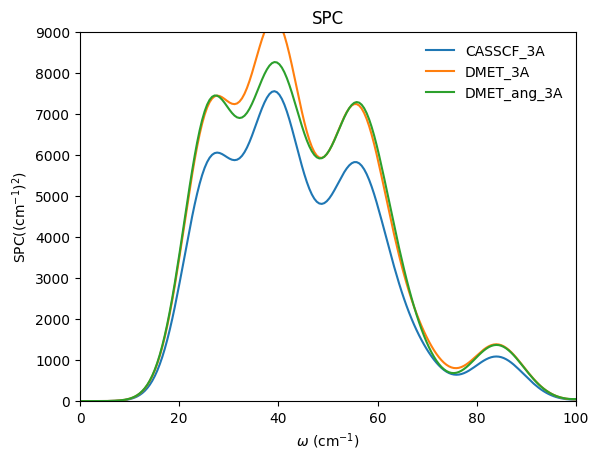

In [4]:
maxlim=100
x = np.linspace(0, maxlim, 200)


y = np.loadtxt('SPC_1h_oc3A.txt')
plt.plot(x, y, label='CASSCF_3A')
y = np.loadtxt('SPC_1h_py3A.txt')
plt.plot(x, y, label='DMET_3A')
y = np.loadtxt('SPC_1h_pyang3A.txt')
plt.plot(x, y, label='DMET_ang_3A')

plt.title("SPC")
plt.xlabel("$\mathit{\omega}$ (cm$^{-1}$)") 
plt.ylabel("SPC((cm$^{-1}$)$^{2}$)") 
plt.ylim(0,9000)
plt.xlim(0,maxlim)
plt.legend(frameon=False,bbox_to_anchor=(1, 1),loc=1,ncol=1)
#np.savetxt(filename+'.txt',y)
plt.savefig('SPC_1h_compy.png',bbox_inches='tight')
plt.show()